# Experiment 2

In [93]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Imports

In [94]:
import os
import sys
import datetime
from collections import defaultdict
import re
from html import escape
import json
from pathlib import Path
import yaml


from dotenv import load_dotenv
import jinja2
import pandas as pd
import docker
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from playwright.async_api import async_playwright
from scipy.stats import chi2
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy.optimize import curve_fit
from scipy import stats
import matplotlib.ticker as ticker
import pyperclip





import common

## Environmental Variables

In [95]:
load_dotenv()
s3_bucket = os.environ.get("S3_BUCKET")
print(f"S3 Bucket: {s3_bucket}")


S3 Bucket: kasbench-test-20260528-377288663341-us-east-1-an


## Constants

In [133]:
RUN = "experiment-1-60m-7rep-xlarge-a"
SAMPLE_TRIAL = "trial0001" # Used to extract common infrastructure details
DATA_DIR = f"../data/{RUN}"
os.makedirs(DATA_DIR, exist_ok=True)
report_date = datetime.datetime.now(datetime.UTC)

RUN_DB = f"{DATA_DIR}/logs.db"
print(f"Run database is {RUN_DB}")

SLO_RT_MS = 100
SLO_FR = 0.0001

# Means from the baseline run (baseline_resource_calculations.ipynb)
SLO_RT_MS = 26.063374 * 2
SLO_FR = 0.000245 * 2

TOLERANCE = 0.20

TOTAL_CPU = 32
TOTAL_MEMORY = 64_000_000_000

TEMPLATE_DIR = "./templates"
FIGURE_DIR = "../figures"

AUTOSCALER_LOOKUP = {"hpa": "Kubernetes Horizontal Pod Autoscaler (HPA)",
    "vpa": "Kubernetes Vertical Pod Autoscaler (VPA)",
    "keda": "Kubernetes Event-Driven Autoscaler (KEDA)",
    "none": "No autoscaler (control condition)"}

TIME_SLICE_SECONDS = 30


MICROSERVICES = ["globeco-allocation-service",
    "globeco-confirmation-service",
    "globeco-execution-service",
    "globeco-fix-engine",
    "globeco-order-generation-service",
    "globeco-order-service",
    "globeco-portfolio-accounting-service",
    "globeco-portfolio-management-portal",
    "globeco-portfolio-service",
    "globeco-pricing-service",
    "globeco-security-service",
    "globeco-trade-service",
    ]

ALPHA = 0.50
BETA = 0.50
K = 5
W_MAX = 1


Run database is ../data/experiment-1-60m-7rep-xlarge-a/logs.db


## Response Time, Failure Rate, and Roundtrip Metrics

### Compile data

In [242]:
# Download the Locust database files and load them into a single database
common.download_and_load_locust_dbs(s3_bucket, RUN, RUN_DB, DATA_DIR)


In [243]:
# Get the log as a dataframe
log_df_filename = f"{DATA_DIR}/log_df.parquet"
if os.path.exists(log_df_filename) and False:  #TEMPORARY
    log_df = pd.read_parquet(log_df_filename)
else:
    log_df = common.get_log_as_dataframe(RUN_DB)
    log_df.to_parquet(log_df_filename)

In [244]:
# # convert log_df.start_time to datetime
# log_df['start_time'] = pd.to_datetime(log_df['start_time'], unit='us')

# # Add a column to log_df called trial_start_time which is the minimum start_time for the trial_id
# log_df['trial_start_time'] = log_df.groupby('trial_id')['start_time'].transform('min')
# log_df['elapsed_time'] = (log_df['start_time'] - log_df['trial_start_time'])  #/ 1_000_000
# log_df['elapsed_seconds'] =log_df['elapsed_time'].dt.total_seconds()

# log_df = log_df[log_df.elapsed_seconds < 100]



In [245]:
# Summarize by trial
trial_summary_df = common.get_trial_summary_df(log_df)

# Merge with roundtrip percentages
merged_trial_summary_df = common.merge_roundtrip_completion_percentage(None, s3_bucket, trial_summary_df, RUN)

# Summary by autoscaler
autoscaler_summary_df = common.get_autoscaler_summary(merged_trial_summary_df)


In [246]:
autoscaler_summary_df.columns

Index(['autoscaler', 'trials', 'mean_rt', 'median_rt', 'sd_rt',
       'mean_failure_rate', 'median_failure_rate', 'sd_failure_rate',
       'mean_p99_response_time', 'median_p99_response_time',
       'sd_p99_response_time', 'mean_roundtrip_completion_percentage',
       'median_roundtrip_completion_percentage',
       'sd_roundtrip_completion_percentage', 'total_quantity_ordered',
       'total_quantity_placed', 'total_quantity_filled', 'ci95_rt',
       'ci95_failure_rate', 'ci95_roundtrip_completion_percentage',
       'pooled_roundtrip_completion_percentage'],
      dtype='str')

In [247]:
autoscaler_summary_df

,autoscaler,trials,mean_rt,median_rt,sd_rt,mean_failure_rate,median_failure_rate,sd_failure_rate,mean_p99_response_time,median_p99_response_time,...,mean_roundtrip_completion_percentage,median_roundtrip_completion_percentage,sd_roundtrip_completion_percentage,total_quantity_ordered,total_quantity_placed,total_quantity_filled,ci95_rt,ci95_failure_rate,ci95_roundtrip_completion_percentage,pooled_roundtrip_completion_percentage
0,horizontal-1,4,1624.003327,1654.000766,141.545978,0.499513,0.497331,0.019329,33989.076346,33079.437320,...,9.635082,9.339454,0.748117,65864080,65864080,6323182,225.231237,0.030757,1.190422,9.600350
1,horizontal-2,3,631.927357,629.695988,55.605190,0.001001,0.001063,0.000113,2511.169677,2587.915147,...,2.984532,2.940891,0.144304,312225859,312225859,9309088,138.130949,0.000281,0.358470,2.981524
2,horizontal-3,3,136.251850,134.504407,5.975605,0.000193,0.000190,0.000023,814.193223,814.845322,...,3.747377,3.820678,0.164237,372614321,372614321,13961286,14.844227,0.000056,0.407988,3.746846
3,horizontal-4,3,100.457529,92.892359,13.107408,0.000068,0.000059,0.000031,582.642175,520.497194,...,5.463976,5.363046,0.485669,375270328,375270328,20500344,32.560605,0.000076,1.206469,5.462820
4,horizontal-5,3,84.797920,83.927087,1.689337,0.000036,0.000032,0.000009,426.743771,444.465291,...,6.366908,6.588047,0.454194,367173228,367173228,23361462,4.196547,0.000023,1.128282,6.362518


In [248]:
merged_trial_summary_df

,autoscaler,trial_id,successful_requests,mean_response_time,sd_response_time,p99_response_time,unmodified_mean_response_time,sd_unmodified_response_time,requests,failures,failure_rate,sd_failure_rate,quantity_ordered,quantity_placed,quantity_filled,roundtrip_completion_percentage
0,horizontal-1,trial0001,197259,1742.746271,5642.414862,40542.647503,2564.578632,10193.562240,385410,188151,0.488184,0.499861,17073974,17073974,1557644,9.122914
1,horizontal-1,trial0005,185888,1732.291899,5047.101550,33435.088666,2343.561864,9565.006531,389956,204068,0.523310,0.499457,15026859,15026859,1613660,10.738505
2,horizontal-1,trial0012,205833,1445.265505,4666.704499,29254.783241,2364.815657,9833.452797,395893,190060,0.480079,0.499604,17526779,17526779,1617551,9.229026
3,horizontal-1,trial0016,196075,1575.709634,4991.805205,32723.785974,2312.098626,9665.061074,397298,201223,0.506479,0.499959,16236468,16236468,1534327,9.449882
4,horizontal-2,trial0002,692343,577.471440,601.139882,2304.211624,577.030219,600.983757,693085,742,0.001071,0.032702,106583299,106583299,3055835,2.867086
5,horizontal-2,trial0006,673464,688.614644,741.875584,2641.382262,688.203808,742.132105,674051,587,0.000871,0.029497,100391394,100391394,3157931,3.145619
6,horizontal-2,trial0010,687177,629.695988,680.242724,2587.915147,629.235283,680.278529,687908,731,0.001063,0.032581,105251166,105251166,3095322,2.940891
7,horizontal-3,trial0003,766148,131.344768,199.553985,814.845322,131.343671,199.543278,766279,131,0.000171,0.013074,121259127,121259127,4683270,3.862200
8,horizontal-3,trial0007,776999,134.504407,196.777564,806.639267,134.503216,196.765547,777147,148,0.000190,0.013799,126861811,126861811,4846981,3.820678
9,horizontal-3,trial0013,772591,142.906376,202.039266,821.095080,142.961841,204.169197,772758,167,0.000216,0.014699,124493383,124493383,4431035,3.559253


### Results table ($\LaTeX$)

In [249]:
df = merged_trial_summary_df.copy()
df["replicas"] = df.autoscaler.str[-1].astype(int)
df = df[['replicas', 'trial_id', 
       'requests', 'failures', 'mean_response_time', 'failure_rate', 
       'roundtrip_completion_percentage']]
df.columns = ['Replicas', 'Trial ID',
       'Requests', 'Failures', 'Mean Response Time (ms)', 'Failure Rate',
       r'Roundtrip Completion \%']

format_dict = {
    "Mean Response Time (ms)": "{:.1f}",
    "Failure Rate": "{:.2e}",
    r"Roundtrip Completion \%": "{:.1f}",
}



# Apply the formatting and export to LaTeX
latex = df.style.format(format_dict, na_rep='').hide(axis="index").hide(axis='index').to_latex(
    caption="Experiment 1 Summary of results by trial.",
    label="tab:experiment-1-summary-of-results-by-trial",
    hrules=True,
    
)

latex = latex.replace("Mean Response Time (ms)", r"\makecell[c]{Mean Response\\Time (ms)}")
latex = latex.replace(r"Roundtrip Completion \%", r"\makecell[c]{Roundtrip \\Completion \%}")

print(latex)
pyperclip.copy(latex)

df

\begin{table}
\caption{Experiment 1 Summary of results by trial.}
\label{tab:experiment-1-summary-of-results-by-trial}
\begin{tabular}{rlrrrrr}
\toprule
Replicas & Trial ID & Requests & Failures & \makecell[c]{Mean Response\\Time (ms)} & Failure Rate & \makecell[c]{Roundtrip \\Completion \%} \\
\midrule
1 & trial0001 & 385410 & 188151 & 1742.7 & 4.88e-01 & 9.1 \\
1 & trial0005 & 389956 & 204068 & 1732.3 & 5.23e-01 & 10.7 \\
1 & trial0012 & 395893 & 190060 & 1445.3 & 4.80e-01 & 9.2 \\
1 & trial0016 & 397298 & 201223 & 1575.7 & 5.06e-01 & 9.4 \\
2 & trial0002 & 693085 & 742 & 577.5 & 1.07e-03 & 2.9 \\
2 & trial0006 & 674051 & 587 & 688.6 & 8.71e-04 & 3.1 \\
2 & trial0010 & 687908 & 731 & 629.7 & 1.06e-03 & 2.9 \\
3 & trial0003 & 766279 & 131 & 131.3 & 1.71e-04 & 3.9 \\
3 & trial0007 & 777147 & 148 & 134.5 & 1.90e-04 & 3.8 \\
3 & trial0013 & 772758 & 167 & 142.9 & 2.16e-04 & 3.6 \\
4 & trial0008 & 772767 & 79 & 115.6 & 1.02e-04 & 5.0 \\
4 & trial0009 & 768263 & 33 & 92.9 & 4.30e-05 & 5.4 

,Replicas,Trial ID,Requests,Failures,Mean Response Time (ms),Failure Rate,Roundtrip Completion \%
0,1,trial0001,385410,188151,1742.746271,0.488184,9.122914
1,1,trial0005,389956,204068,1732.291899,0.523310,10.738505
2,1,trial0012,395893,190060,1445.265505,0.480079,9.229026
3,1,trial0016,397298,201223,1575.709634,0.506479,9.449882
4,2,trial0002,693085,742,577.471440,0.001071,2.867086
5,2,trial0006,674051,587,688.614644,0.000871,3.145619
6,2,trial0010,687908,731,629.695988,0.001063,2.940891
7,3,trial0003,766279,131,131.344768,0.000171,3.862200
8,3,trial0007,777147,148,134.504407,0.000190,3.820678
9,3,trial0013,772758,167,142.906376,0.000216,3.559253


In [250]:
df = autoscaler_summary_df.copy()
df["replicas"] = df["autoscaler"].str[-1]
df = df[['replicas', 'mean_rt', 
       'mean_failure_rate',  'mean_roundtrip_completion_percentage',
       
       ]]
df.columns = ["Replicas", "Mean Response Time (ms)", "Mean Failure Rate", "Mean Roundtrip Completion Percentage" ]

format_dict = {
    "Mean Response Time (ms)": "{:.1f}",
    "Mean Failure Rate": "{:.2e}",
    "Mean Roundtrip Completion Percentage": "{:.1f}",
}

latex = df.style.format(format_dict, na_rep='').hide(axis='index').to_latex(
    caption="Experiment 1 summary of results.",
    label="tab:experiment-1-summary-of-results",
    hrules=True
)

latex = latex.replace("Mean Response Time (ms)", r"\makecell[c]{Mean Response\\Time (ms)}")
latex = latex.replace("Mean Failure Rate", r"\makecell[c]{Mean Failure\\Rate}")
latex = latex.replace("Mean Roundtrip Completion Percentage", r"\makecell[c]{Mean Roundtrip\\Completion Percentage}")

print(latex)
pyperclip.copy(latex)

\begin{table}
\caption{Experiment 1 summary of results.}
\label{tab:experiment-1-summary-of-results}
\begin{tabular}{lrrr}
\toprule
Replicas & \makecell[c]{Mean Response\\Time (ms)} & \makecell[c]{Mean Failure\\Rate} & \makecell[c]{Mean Roundtrip\\Completion Percentage} \\
\midrule
1 & 1624.0 & 5.00e-01 & 9.6 \\
2 & 631.9 & 1.00e-03 & 3.0 \\
3 & 136.3 & 1.93e-04 & 3.7 \\
4 & 100.5 & 6.82e-05 & 5.5 \\
5 & 84.8 & 3.64e-05 & 6.4 \\
\bottomrule
\end{tabular}
\end{table}



Results by API 


['run_id', 'trial_id', 'role', 'autoscaler', 'user_id', 'request_type',
       'name', 'response_time', 'response_length', 'response', 'status_code',
       'reason', 'exception', 'start_time', 'url', 'method_and_name',
       'success', 'failure']

In [251]:
df = log_df.copy()
df["is_success"] = pd.to_numeric(
    df["status_code"], errors="coerce"
).between(200, 299)

api_df = df[df.is_success == True].groupby(["method_and_name", "autoscaler"]).agg(
    {'response_time': 'mean',
     'failure': 'mean',
    }).reset_index()
api_df['autoscaler'] = api_df["autoscaler"].str[-1].astype(int)
api_df.columns = ["API", "Replicas", "Mean Response Time (ms)", "Mean Failure Rate"]

api_rt_df = api_df.pivot(
    index='API', 
    columns='Replicas', values=['Mean Response Time (ms)']
)

api_df = df.groupby(["method_and_name", "autoscaler"]).agg(
    {'response_time': 'mean',
     'failure': 'mean',
    }).reset_index()
api_df['autoscaler'] = api_df["autoscaler"].str[-1].astype(int)
api_df.columns = ["API", "Replicas", "Mean Response Time (ms)", "Mean Failure Rate"]


api_fr_df = api_df.pivot(
    index='API', 
    columns='Replicas', values=['Mean Failure Rate']
)


display(api_rt_df)
display(api_fr_df)


Mean Response Time (ms)  \
Replicas                                                              1   
API                                                                       
GET /api/balances?portfolio_id={id}                          822.349338   
GET /api/executions/{id}                                    1812.327724   
GET /api/executions?portfolio_id={portfolio_id}             1655.149376   
GET /api/models/{id}                                        1244.773338   
GET /api/orders                                             3703.332492   
GET /api/portfolios/{id}                                    1811.304010   
GET /api/rebalances/{id}                                    1068.081625   
GET /api/securities                                          103.123839   
GET /api/trades                                             1560.794783   
GET /api/trades?orderId                                     1046.773726   
GET /api/transactions?portfolio_id={id}                      794.586303   
POST /api/models                                            3079.169598   
POST /api/models/{id}/rebalance                             2937.893334   
POST /api/orders/batch/submit                                939.052085   
POST /api/portfolios/bulk                                   2348.541728   
POST /api/rebalances/submit-positions                        925.092678   
POST /api/trade-orders/batch/submit                          702.463974   
POST /api/transactions                                      1058.295822   

                                                                           \
Replicas                                                   2            3   
API                                                                         
GET /api/balances?portfolio_id={id}               269.983168   215.709415   
GET /api/executions/{id}                         1287.176486   158.962826   
GET /api/executions?portfolio_id={portfolio_id}  2475.048838   344.540157   
GET /api/models/{id}                              259.496620    84.774270   
GET /api/orders                                   310.790491   237.652052   
GET /api/portfolios/{id}                          151.477608    40.900382   
GET /api/rebalances/{id}                          237.430127    84.523067   
GET /api/securities                                62.520350    69.951933   
GET /api/trades                                   475.884934   234.076762   
GET /api/trades?orderId                           288.532209   174.060002   
GET /api/transactions?portfolio_id={id}           281.384852   200.995458   
POST /api/models                                  281.666700    93.851790   
POST /api/models/{id}/rebalance                  1895.207758  1220.757911   
POST /api/orders/batch/submit                     143.040693    46.822452   
POST /api/portfolios/bulk                         131.044300    32.477467   
POST /api/rebalances/submit-positions             174.896251    80.244996   
POST /api/trade-orders/batch/submit               650.195069   210.980174   
POST /api/transactions                            145.441245    37.610279   

                                                                          
Replicas                                                   4           5  
API                                                                       
GET /api/balances?portfolio_id={id}               175.113374  164.123728  
GET /api/executions/{id}                          113.001542   90.509685  
GET /api/executions?portfolio_id={portfolio_id}   247.875468  196.407849  
GET /api/models/{id}                               63.574679   40.970503  
GET /api/orders                                   191.508851  174.077234  
GET /api/portfolios/{id}                           31.782780   27.394466  
GET /api/rebalances/{id}                           64.255555   43.015408  
GET /api/securities                                78.185035   67.619309  
GET /api/trades              

Mean Failure Rate            \
Replicas                                                        1         2   
API                                                                           
GET /api/balances?portfolio_id={id}                      0.247234  0.000568   
GET /api/executions/{id}                                 0.496875  0.000741   
GET /api/executions?portfolio_id={portfolio_id}          0.242232  0.000663   
GET /api/models/{id}                                     0.183255  0.000579   
GET /api/orders                                          0.776079  0.000832   
GET /api/portfolios/{id}                                 0.528375  0.000920   
GET /api/rebalances/{id}                                 0.147054  0.000700   
GET /api/securities                                      0.000000  0.000000   
GET /api/trades                                          0.761639  0.000277   
GET /api/trades?orderId                                  0.350059  0.000879   
GET /api/transactions?portfolio_id={id}                  0.252766  0.000663   
POST /api/models                                         0.732929  0.003400   
POST /api/models/{id}/rebalance                          0.258102  0.005621   
POST /api/orders/batch/submit                            0.141494  0.001015   
POST /api/portfolios/bulk                                0.773979  0.004437   
POST /api/rebalances/submit-positions                    0.051576  0.000292   
POST /api/trade-orders/batch/submit                      0.041444  0.000445   
POST /api/transactions                                   0.199667  0.000899   

                                                                               
Replicas                                                3         4         5  
API                                                                            
GET /api/balances?portfolio_id={id}              0.000148  0.000000  0.000000  
GET /api/executions/{id}                         0.000099  0.000025  0.000009  
GET /api/executions?portfolio_id={portfolio_id}  0.000074  0.000069  0.000000  
GET /api/models/{id}                             0.000164  0.000000  0.000054  
GET /api/orders                                  0.000234  0.000000  0.000000  
GET /api/portfolios/{id}                         0.000093  0.000030  0.000011  
GET /api/rebalances/{id}                         0.000110  0.000000  0.000000  
GET /api/securities                              0.000000  0.000000  0.000000  
GET /api/trades                                  0.000000  0.000000  0.000000  
GET /api/trades?orderId                          0.000294  0.000081  0.000022  
GET /api/transactions?portfolio_id={id}          0.000148  0.000000  0.000000  
POST /api/models                                 0.001528  0.001732  0.001660  
POST /api/models/{id}/rebalance                  0.001863  0.000761  0.000484  
POST /api/orders/batch/submit                    0.000110  0.000073  0.000000  
POST /api/portfolios/bulk                        0.001147  0.000315  0.000224  
POST /api/rebalances/submit-positions            0.000110  0.000109  0.000000  
POST /api/trade-orders/batch/submit              0.000081  0.000031  0.000000  
POST /api/transactions                           0.000081  0.000031  0.000010

Reponse time by API and replicas in LaTeX

In [252]:
api_rt_df.columns

MultiIndex([('Mean Response Time (ms)', 1),
            ('Mean Response Time (ms)', 2),
            ('Mean Response Time (ms)', 3),
            ('Mean Response Time (ms)', 4),
            ('Mean Response Time (ms)', 5)],
           names=[None, 'Replicas'])

In [253]:
format_dict = {c: "{:.1f}" for c in api_rt_df.columns}

latex = api_rt_df.style.format(format_dict, na_rep='').to_latex(
    caption="Response time (ms) by API and number of replicas in Experiment 1.",
    label="tab:experiment-1-response-time-by-api-and-replicas",
    hrules=True
)
latex = latex.replace("{id}", r"\{id\}")
latex = latex.replace("{portfolio_id}", r"\{id\}")

pyperclip.copy(latex)
print(latex)

\begin{table}
\caption{Response time (ms) by API and number of replicas in Experiment 1.}
\label{tab:experiment-1-response-time-by-api-and-replicas}
\begin{tabular}{lrrrrr}
\toprule
 & \multicolumn{5}{r}{Mean Response Time (ms)} \\
Replicas & 1 & 2 & 3 & 4 & 5 \\
API &  &  &  &  &  \\
\midrule
GET /api/balances?portfolio_id=\{id\} & 822.3 & 270.0 & 215.7 & 175.1 & 164.1 \\
GET /api/executions/\{id\} & 1812.3 & 1287.2 & 159.0 & 113.0 & 90.5 \\
GET /api/executions?portfolio_id=\{id\} & 1655.1 & 2475.0 & 344.5 & 247.9 & 196.4 \\
GET /api/models/\{id\} & 1244.8 & 259.5 & 84.8 & 63.6 & 41.0 \\
GET /api/orders & 3703.3 & 310.8 & 237.7 & 191.5 & 174.1 \\
GET /api/portfolios/\{id\} & 1811.3 & 151.5 & 40.9 & 31.8 & 27.4 \\
GET /api/rebalances/\{id\} & 1068.1 & 237.4 & 84.5 & 64.3 & 43.0 \\
GET /api/securities & 103.1 & 62.5 & 70.0 & 78.2 & 67.6 \\
GET /api/trades & 1560.8 & 475.9 & 234.1 & 180.8 & 162.7 \\
GET /api/trades?orderId & 1046.8 & 288.5 & 174.1 & 129.0 & 117.9 \\
GET /api/transactions

Failure rate by API and replicas in LaTeX

In [254]:
def format_apa_sci(val):
    # Return empty string for NaN/None values
    if pd.isna(val):
        return ''
    # Optional: leave 0 as 0 instead of 0.00 x 10^0
    if val == 0:
        return '0'
    
    # Format to standard scientific notation first (e.g., "4.22e-07")
    base, exp = f"{val:.2e}".split("e")
    
    # Convert exponent to integer to strip leading zeros and '+' signs (e.g., "-07" -> -7)
    return f"${base} \\times 10^{{{int(exp)}}}$"

# Apply the function to your numeric columns
format_dict = {c: format_apa_sci for c in api_fr_df.columns}

latex = api_fr_df.style.format(format_dict, na_rep='').to_latex(
    caption="Failure rate by API and number of replicas in Experiment 1.",
    label="tab:experiment-1-failure_rate-by-api-and-replicas",
    hrules=True
)

latex = latex.replace("{id}", r"\{id\}")
latex = latex.replace("{portfolio_id}", r"\{id\}")


pyperclip.copy(latex)
print(latex)


\begin{table}
\caption{Failure rate by API and number of replicas in Experiment 1.}
\label{tab:experiment-1-failure_rate-by-api-and-replicas}
\begin{tabular}{lrrrrr}
\toprule
 & \multicolumn{5}{r}{Mean Failure Rate} \\
Replicas & 1 & 2 & 3 & 4 & 5 \\
API &  &  &  &  &  \\
\midrule
GET /api/balances?portfolio_id=\{id\} & $2.47 \times 10^{-1}$ & $5.68 \times 10^{-4}$ & $1.48 \times 10^{-4}$ & 0 & 0 \\
GET /api/executions/\{id\} & $4.97 \times 10^{-1}$ & $7.41 \times 10^{-4}$ & $9.86 \times 10^{-5}$ & $2.53 \times 10^{-5}$ & $9.35 \times 10^{-6}$ \\
GET /api/executions?portfolio_id=\{id\} & $2.42 \times 10^{-1}$ & $6.63 \times 10^{-4}$ & $7.39 \times 10^{-5}$ & $6.92 \times 10^{-5}$ & 0 \\
GET /api/models/\{id\} & $1.83 \times 10^{-1}$ & $5.79 \times 10^{-4}$ & $1.64 \times 10^{-4}$ & 0 & $5.37 \times 10^{-5}$ \\
GET /api/orders & $7.76 \times 10^{-1}$ & $8.32 \times 10^{-4}$ & $2.34 \times 10^{-4}$ & 0 & 0 \\
GET /api/portfolios/\{id\} & $5.28 \times 10^{-1}$ & $9.20 \times 10^{-4}$ & $9

Additional analysis

MultiIndex([('Mean Response Time (ms)', 1),
            ('Mean Response Time (ms)', 2),
            ('Mean Response Time (ms)', 3),
            ('Mean Response Time (ms)', 4),
            ('Mean Response Time (ms)', 5)],
           names=[None, 'Replicas'])

In [255]:
(1  - api_rt_df[('Mean Response Time (ms)', 2)] / api_rt_df[('Mean Response Time (ms)', 1)]) * 100

API
GET /api/balances?portfolio_id={id}                67.169285
GET /api/executions/{id}                           28.976616
GET /api/executions?portfolio_id={portfolio_id}   -49.536282
GET /api/models/{id}                               79.153103
GET /api/orders                                    91.607816
GET /api/portfolios/{id}                           91.637096
GET /api/rebalances/{id}                           77.770414
GET /api/securities                                39.373523
GET /api/trades                                    69.510089
GET /api/trades?orderId                            72.436048
GET /api/transactions?portfolio_id={id}            64.587251
POST /api/models                                   90.852511
POST /api/models/{id}/rebalance                    35.490927
POST /api/orders/batch/submit                      84.767544
POST /api/portfolios/bulk                          94.420184
POST /api/rebalances/submit-positions              81.094191
POST /api/trade-orde

In [256]:
api_rt_df.max() - api_rt_df.min()

                         Replicas
Mean Response Time (ms)  1           3600.208653
                         2           2412.528488
                         3           1188.280444
                         4           1079.674532
                         5            860.171564
dtype: float64

### Main Effect Plots


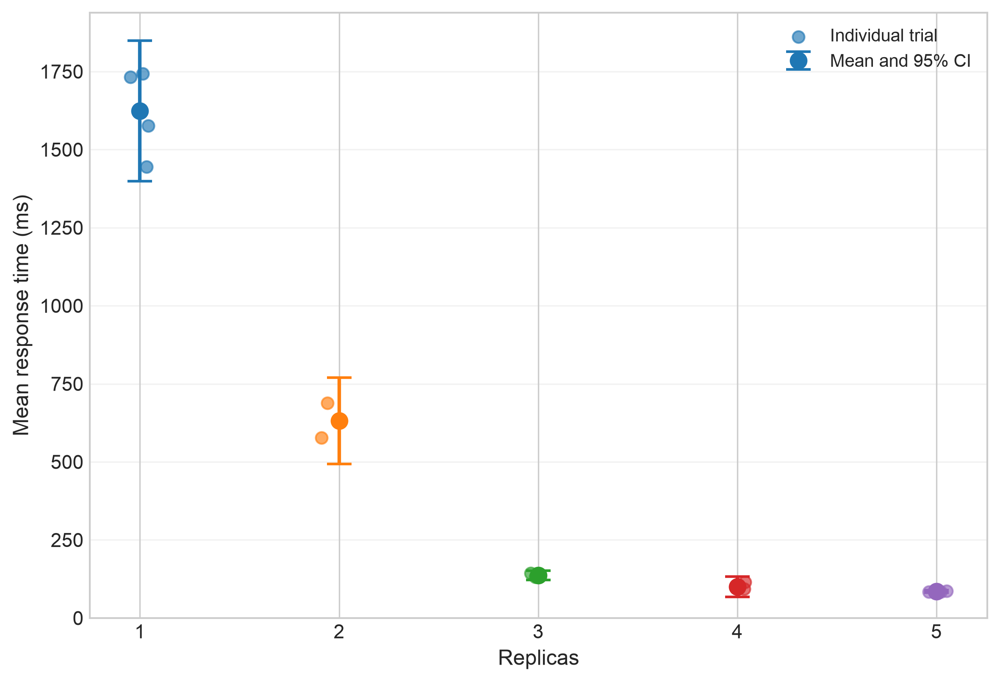

None


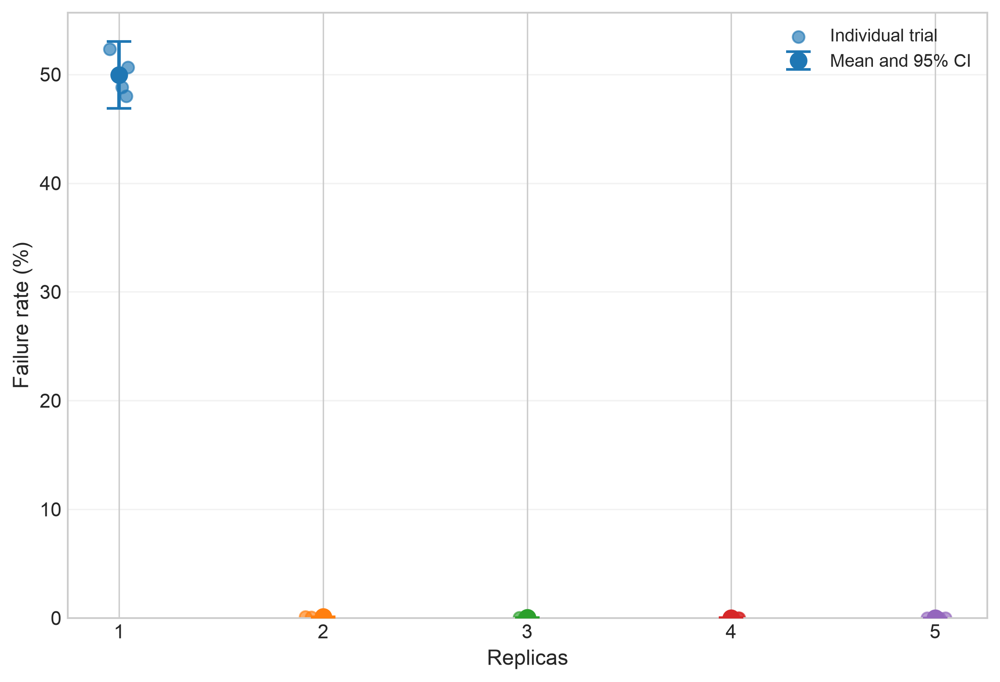

None


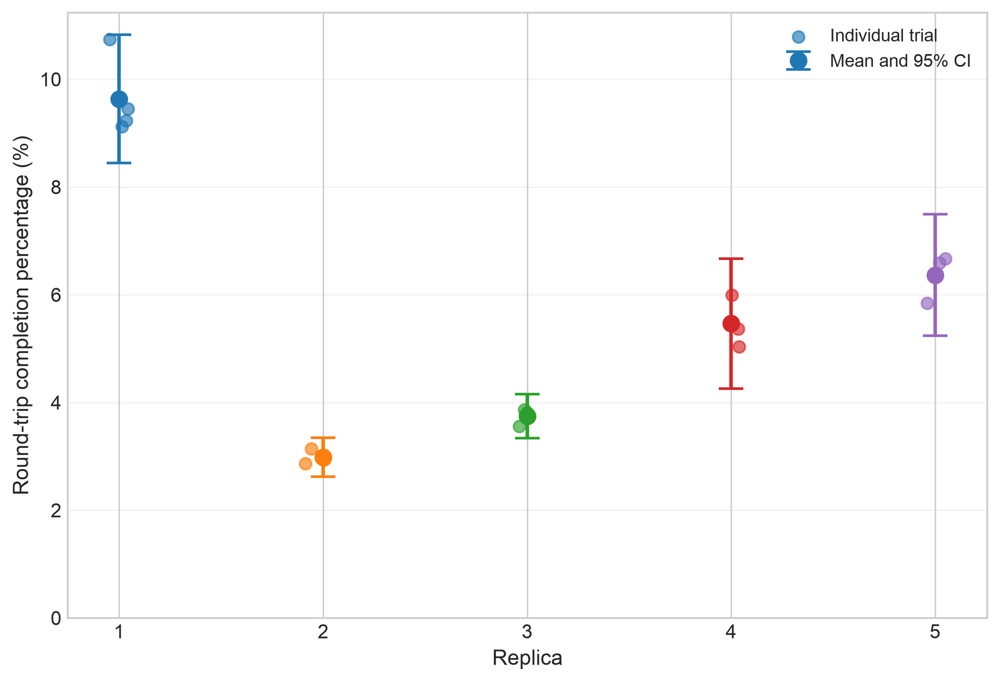

None


In [257]:

# Generate mean response time by autoscaler plot

df = merged_trial_summary_df.copy()
df['autoscaler'] = df["autoscaler"].str[-1]

fig, ax, filename, fit_stats = common.plot_mean_response_time_by_replicas(df, show=True, show_fitted_line=False,
filename = "../figures/experiment_1_response_time_by_autoscaler.png", x_label="Replicas")
print(fit_stats)

# Generate failure rate by autoscaler plot
fig, ax, filename, fit_stats = common.plot_failure_rate_by_autoscaler(df, show=True, show_fitted_line=False,
filename = "../figures/experiment_1_failure_rate_by_autoscaler.png", x_label="Replicas")
print(fit_stats)

fig, ax, filename, fit_stats = common.plot_roundtrip_completion_by_autoscaler(df, show=True, show_fitted_line=False,
filename = "../figures/experiment_1_roundtrip_completion_by_autoscaler.png", x_label="Replica")
print(fit_stats)


### Variance/CV table

In [258]:
df = autoscaler_summary_df.copy()
df['replicas'] = df["autoscaler"].str[-1].astype(int)
df['cv_rt'] = df['sd_rt'] / df['mean_rt']
df['cv_fr'] = df['sd_failure_rate'] / df['mean_failure_rate']
df['cv_rtp'] = df['sd_roundtrip_completion_percentage'] / df['mean_roundtrip_completion_percentage']
df['variance_rt'] = df['sd_rt'] ** 2
df['variance_fr'] = df['sd_failure_rate'] ** 2
df['variance_rtp'] = df['sd_roundtrip_completion_percentage'] ** 2
df = df[['replicas', 'variance_rt', 'variance_fr', 'variance_rtp',
       'cv_rt', 'cv_fr', 'cv_rtp']]
df.columns = ['Replicas', 'RT Variance (ms²)', 'FR Variance', 'RCP Variance (%)',
       'RT CV', 'FR CV', 'RCP CV']

latex = df.style.format({
    "variance_rt": "{:.1e}",
    "variance_fr": "{:.2e}",
    "variance_rtp": "{:.1e}",
    'cv_rt': '{:.2f}',
    'cv_fr': '{:.2f}',
    'cv_rtp': '{:.2f}',
}).to_latex(caption="Experiment 1 variance and coefficient of variance (CV) by number of replicas for Response Time (RT), Failure Rate (FR) and Roundtrip Completion Percentage (RCP).",
label="tab:experiment-1-variance-by-replica-count",
hrules=True)    
print(latex)
pyperclip.copy(latex)
df

\begin{table}
\caption{Experiment 1 variance and coefficient of variance (CV) by number of replicas for Response Time (RT), Failure Rate (FR) and Roundtrip Completion Percentage (RCP).}
\label{tab:experiment-1-variance-by-replica-count}
\begin{tabular}{lrrrrrrr}
\toprule
 & Replicas & RT Variance (ms²) & FR Variance & RCP Variance (%) & RT CV & FR CV & RCP CV \\
\midrule
0 & 1 & 20035.263773 & 0.000374 & 0.559680 & 0.087159 & 0.038696 & 0.077645 \\
1 & 2 & 3091.937154 & 0.000000 & 0.020824 & 0.087993 & 0.112935 & 0.048351 \\
2 & 3 & 35.707861 & 0.000000 & 0.026974 & 0.043857 & 0.117646 & 0.043827 \\
3 & 4 & 171.804133 & 0.000000 & 0.235875 & 0.130477 & 0.449025 & 0.088886 \\
4 & 5 & 2.853861 & 0.000000 & 0.206293 & 0.019922 & 0.259367 & 0.071337 \\
\bottomrule
\end{tabular}
\end{table}



,Replicas,RT Variance (ms²),FR Variance,RCP Variance (%),RT CV,FR CV,RCP CV
0,1,20035.263773,3.736175e-04,0.559680,0.087159,0.038696,0.077645
1,2,3091.937154,1.278907e-08,0.020824,0.087993,0.112935,0.048351
2,3,35.707861,5.128869e-10,0.026974,0.043857,0.117646,0.043827
3,4,171.804133,9.370244e-10,0.235875,0.130477,0.449025,0.088886
4,5,2.853861,8.921214e-11,0.206293,0.019922,0.259367,0.071337


### Variance plots

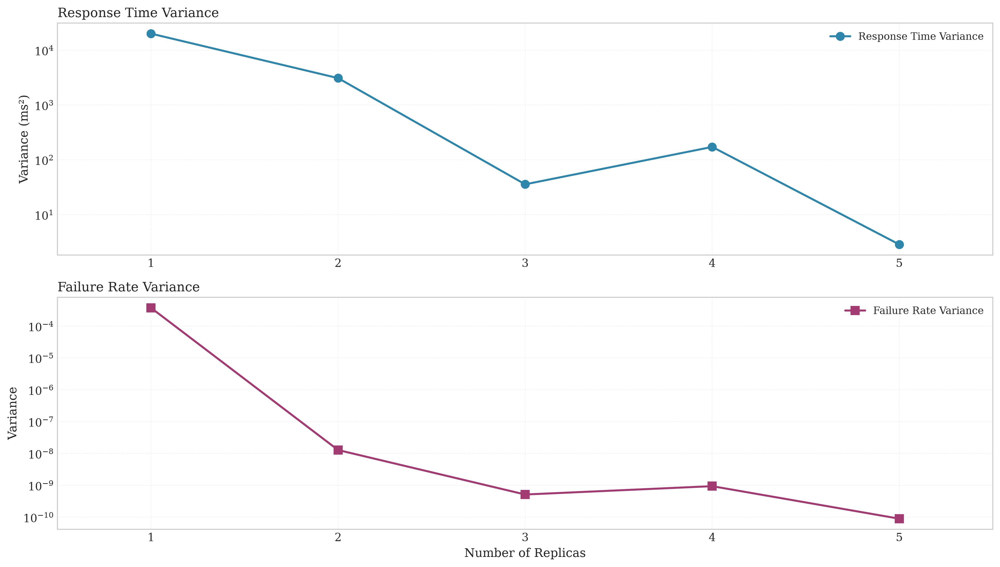

In [259]:
# Index(['autoscaler', 'trials', 'mean_rt', 'median_rt', 'sd_rt',
#        'mean_failure_rate', 'median_failure_rate', 'sd_failure_rate',
#        'mean_p99_response_time', 'median_p99_response_time',
#        'sd_p99_response_time', 'mean_roundtrip_completion_percentage',
#        'median_roundtrip_completion_percentage',
#        'sd_roundtrip_completion_percentage', 'total_quantity_ordered',
#        'total_quantity_placed', 'total_quantity_filled', 'ci95_rt',
#        'ci95_failure_rate', 'ci95_roundtrip_completion_percentage',
#        'pooled_roundtrip_completion_percentage'],
#       dtype='str')

df_u = autoscaler_summary_df.copy()
df_u['replicas'] = df_u["autoscaler"].str[-1].astype(int)


# --- Global style (unchanged) ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 300

color_primary = '#2E86AB'
color_secondary = '#A23B72'

panel_labels = 'abcd'

# --- Figure 1: 2 metrics x 2 user counts ---
fig1, axes1 = plt.subplots(2, 1, figsize=(14, 8))
fig1.subplots_adjust(hspace=0.35, wspace=0.25)

# df_u = df[df['users'] == users].sort_values('replicas')

ax_rt = axes1[0]
ax_fr = axes1[1]

# --- Response Time Variance ---
rt_var = df_u['sd_rt'] ** 2

ax_rt.plot(df_u['replicas'], rt_var,
            marker='o', linewidth=2, markersize=8,
            color=color_primary, label='Response Time Variance')
ax_rt.set_yscale('log')
ax_rt.set_ylabel('Variance (ms²)')
ax_rt.set_title(f'Response Time Variance',
                loc='left')
ax_rt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax_rt.set_xticks(df_u['replicas'])
ax_rt.legend()
ax_rt.set_xlim(df_u['replicas'].min() - 0.5,
                df_u['replicas'].max() + 0.5)
ax_rt.set_xlabel('')

# --- Failure Rate Variance ---
fr_var = df_u['sd_failure_rate'] ** 2

ax_fr.plot(df_u['replicas'], fr_var,
            marker='s', linewidth=2, markersize=8,
            color=color_secondary, label='Failure Rate Variance')
ax_fr.set_yscale('log')
ax_fr.set_ylabel('Variance')
ax_fr.set_xlabel('Number of Replicas')
ax_fr.set_title(f'Failure Rate Variance',
                loc='left')
ax_fr.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax_fr.set_xticks(df_u['replicas'])
ax_fr.legend()
ax_fr.set_xlim(df_u['replicas'].min() - 0.5,
                df_u['replicas'].max() + 0.5)

plt.tight_layout()
plt.savefig('../figures/experiment_1_rt_and_fr_variance_by_replica_count.png',
            dpi=300, bbox_inches='tight')
plt.show()

With confidence intervals

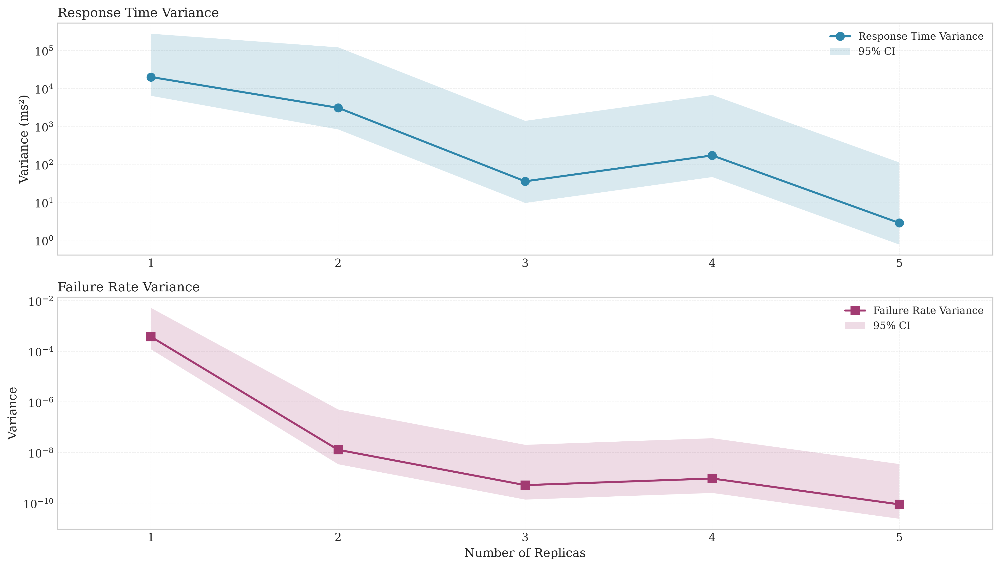

In [260]:

df_u = autoscaler_summary_df.copy()
df_u['replicas'] = df_u["autoscaler"].str[-1].astype(int)
df_u = df_u.sort_values('replicas')

# --- Variance confidence interval (chi-square) ---
# For a sample variance s^2 from n trials, the two-sided (1 - alpha)
# interval for the population variance is:
#     lower = (n - 1) s^2 / chi2_{1 - alpha/2, n-1}
#     upper = (n - 1) s^2 / chi2_{alpha/2, n-1}
# n (the trial count) can differ per replica level, so each point has its
# own interval width. Points with n < 2 have no defined interval.
confidence_level = 0.95
alpha = 1 - confidence_level

def variance_ci(sd, n):
    """Return (lower, upper) arrays for the variance CI; NaN where n < 2."""
    variance = sd ** 2
    dof = n - 1
    lower = np.where(n >= 2, dof * variance / chi2.ppf(1 - alpha / 2, dof), np.nan)
    upper = np.where(n >= 2, dof * variance / chi2.ppf(alpha / 2, dof), np.nan)
    return lower, upper

# --- Global style (unchanged) ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 300

color_primary = '#2E86AB'
color_secondary = '#A23B72'

panel_labels = 'abcd'

# --- Figure 1: 2 metrics x 2 user counts ---
fig1, axes1 = plt.subplots(2, 1, figsize=(14, 8))
fig1.subplots_adjust(hspace=0.35, wspace=0.25)

ax_rt = axes1[0]
ax_fr = axes1[1]

# --- Response Time Variance ---
rt_var = df_u['sd_rt'] ** 2
rt_lower, rt_upper = variance_ci(df_u['sd_rt'], df_u['trials'])

ax_rt.plot(df_u['replicas'], rt_var,
           marker='o', linewidth=2, markersize=8,
           color=color_primary, label='Response Time Variance')
ax_rt.fill_between(df_u['replicas'], rt_lower, rt_upper,
                   color=color_primary, alpha=0.18, linewidth=0,
                   label=f'{confidence_level:.0%} CI')
ax_rt.set_yscale('log')
ax_rt.set_ylabel('Variance (ms²)')
ax_rt.set_title('Response Time Variance', loc='left')
ax_rt.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax_rt.set_xticks(df_u['replicas'])
ax_rt.legend()
ax_rt.set_xlim(df_u['replicas'].min() - 0.5,
               df_u['replicas'].max() + 0.5)
ax_rt.set_xlabel('')

# --- Failure Rate Variance ---
fr_var = df_u['sd_failure_rate'] ** 2
fr_lower, fr_upper = variance_ci(df_u['sd_failure_rate'], df_u['trials'])

ax_fr.plot(df_u['replicas'], fr_var,
           marker='s', linewidth=2, markersize=8,
           color=color_secondary, label='Failure Rate Variance')
ax_fr.fill_between(df_u['replicas'], fr_lower, fr_upper,
                   color=color_secondary, alpha=0.18, linewidth=0,
                   label=f'{confidence_level:.0%} CI')
ax_fr.set_yscale('log')
ax_fr.set_ylabel('Variance')
ax_fr.set_xlabel('Number of Replicas')
ax_fr.set_title('Failure Rate Variance', loc='left')
ax_fr.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax_fr.set_xticks(df_u['replicas'])
ax_fr.legend()
ax_fr.set_xlim(df_u['replicas'].min() - 0.5,
               df_u['replicas'].max() + 0.5)

plt.tight_layout()
plt.savefig('../figures/experiment_1_rt_and_fr_variance_by_replica_count.png',
            dpi=300, bbox_inches='tight')
plt.show()


Including roundtrip completion percentage

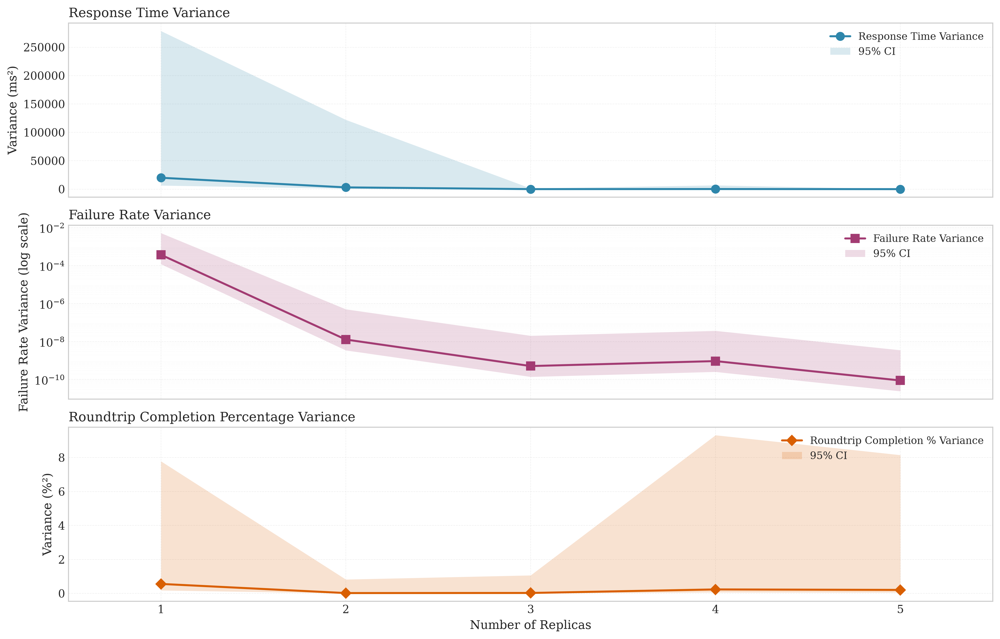

In [261]:


# --- Data Preparation ---
df_u = autoscaler_summary_df.copy()
df_u['replicas'] = df_u["autoscaler"].str[-1].astype(int)
df_u = df_u.sort_values('replicas')

confidence_level = 0.95
alpha = 1 - confidence_level

def variance_ci(sd, n):
    """Return (lower, upper) arrays for the variance CI; NaN where n < 2."""
    variance = sd ** 2
    dof = n - 1
    lower = np.where(n >= 2, dof * variance / chi2.ppf(1 - alpha / 2, dof), np.nan)
    upper = np.where(n >= 2, dof * variance / chi2.ppf(alpha / 2, dof), np.nan)
    return np.maximum(lower, 0.0), upper

# --- Global Style ---
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 300

color_primary = '#2E86AB'    # Teal
color_secondary = '#A23B72'  # Magenta / Plum
color_tertiary = '#D95F02'   # Amber / Rust

x_min = df_u['replicas'].min() - 0.5
x_max = df_u['replicas'].max() + 0.5

# --- Figure Layout ---
fig1, axes1 = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
fig1.subplots_adjust(hspace=0.25)

ax_rt, ax_fr, ax_rtp = axes1

# -------------------------------------------------------------
# 1. Response Time Variance
# -------------------------------------------------------------
rt_var = df_u['sd_rt'] ** 2
rt_lower, rt_upper = variance_ci(df_u['sd_rt'], df_u['trials'])

ax_rt.plot(df_u['replicas'], rt_var,
           marker='o', linewidth=2, markersize=8,
           color=color_primary, label='Response Time Variance')
ax_rt.fill_between(df_u['replicas'], rt_lower, rt_upper,
                   color=color_primary, alpha=0.18, linewidth=0,
                   label=f'{confidence_level:.0%} CI')
ax_rt.set_ylabel('Variance (ms²)')
ax_rt.set_title('Response Time Variance', loc='left')
ax_rt.grid(True, which='major', alpha=0.3, linestyle='--', linewidth=0.5)
ax_rt.set_xlim(x_min, x_max)
ax_rt.legend(loc='upper right')

# -------------------------------------------------------------
# 2. Failure Rate Variance (Log Scale)
# -------------------------------------------------------------
fr_var = df_u['sd_failure_rate'] ** 2
fr_lower, fr_upper = variance_ci(df_u['sd_failure_rate'], df_u['trials'])

ax_fr.plot(df_u['replicas'], fr_var,
           marker='s', linewidth=2, markersize=8,
           color=color_secondary, label='Failure Rate Variance')
ax_fr.fill_between(df_u['replicas'], fr_lower, fr_upper,
                   color=color_secondary, alpha=0.18, linewidth=0,
                   label=f'{confidence_level:.0%} CI')
ax_fr.set_yscale('log')
ax_fr.set_ylabel('Failure Rate Variance (log scale)')
ax_fr.set_title('Failure Rate Variance', loc='left')
ax_fr.grid(True, which='major', alpha=0.3, linestyle='--', linewidth=0.5)
ax_fr.grid(True, which='minor', alpha=0.15, linestyle=':', linewidth=0.5)
ax_fr.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10))
ax_fr.set_xlim(x_min, x_max)
ax_fr.legend(loc='upper right')

# -------------------------------------------------------------
# 3. Roundtrip Percentage Variance
# -------------------------------------------------------------
rtp_var = df_u['sd_roundtrip_completion_percentage'] ** 2
rtp_lower, rtp_upper = variance_ci(df_u['sd_roundtrip_completion_percentage'], df_u['trials'])

ax_rtp.plot(df_u['replicas'], rtp_var,
            marker='D', linewidth=2, markersize=7,
            color=color_tertiary, label='Roundtrip Completion % Variance')
ax_rtp.fill_between(df_u['replicas'], rtp_lower, rtp_upper,
                    color=color_tertiary, alpha=0.18, linewidth=0,
                    label=f'{confidence_level:.0%} CI')
ax_rtp.set_ylabel('Variance (%²)')
ax_rtp.set_xlabel('Number of Replicas')
ax_rtp.set_title('Roundtrip Completion Percentage Variance', loc='left')
ax_rtp.grid(True, which='major', alpha=0.3, linestyle='--', linewidth=0.5)
ax_rtp.set_xticks(df_u['replicas'])
ax_rtp.set_xlim(x_min, x_max)
ax_rtp.legend(loc='upper right')

plt.tight_layout()
plt.savefig('../figures/experiment_1_variance_by_replica_count.png',
            dpi=300, bbox_inches='tight')
plt.show()


### CV plot

The same plot as above, except CV

In [262]:
merged_trial_summary_df.columns

Index(['autoscaler', 'trial_id', 'successful_requests', 'mean_response_time',
       'sd_response_time', 'p99_response_time',
       'unmodified_mean_response_time', 'sd_unmodified_response_time',
       'requests', 'failures', 'failure_rate', 'sd_failure_rate',
       'quantity_ordered', 'quantity_placed', 'quantity_filled',
       'roundtrip_completion_percentage'],
      dtype='str')

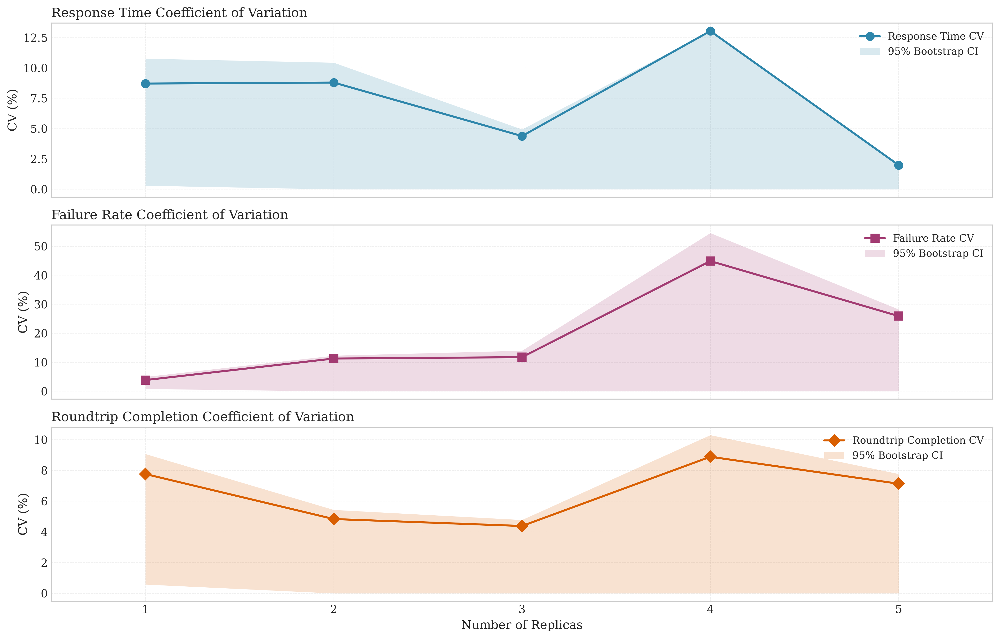

,replicas,metric,trials,cv,ci_lower,ci_upper
0,1,mean_response_time,4,8.716,0.300,10.775
1,1,failure_rate,4,3.870,0.834,4.975
2,1,roundtrip_completion_percentage,4,7.765,0.577,9.070
3,2,mean_response_time,3,8.799,0.000,10.442
4,2,failure_rate,3,11.294,0.000,12.301
5,2,roundtrip_completion_percentage,3,4.835,0.000,5.433
6,3,mean_response_time,3,4.386,0.000,4.937
7,3,failure_rate,3,11.765,0.000,14.015
8,3,roundtrip_completion_percentage,3,4.383,0.000,4.779
9,4,mean_response_time,3,13.048,0.000,13.049


In [263]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =============================================================
# Configuration
# =============================================================
confidence_level = 0.95
n_bootstrap = 10_000
random_seed = 42

metrics = [
    {
        "column": "mean_response_time",
        "title": "Response Time Coefficient of Variation",
        "label": "Response Time CV",
        "color": "#2E86AB",
        "marker": "o",
    },
    {
        "column": "failure_rate",
        "title": "Failure Rate Coefficient of Variation",
        "label": "Failure Rate CV",
        "color": "#A23B72",
        "marker": "s",
    },
    {
        "column": "roundtrip_completion_percentage",
        "title": "Roundtrip Completion Coefficient of Variation",
        "label": "Roundtrip Completion CV",
        "color": "#D95F02",
        "marker": "D",
    },
]

# =============================================================
# Data Preparation
# =============================================================
df_u = merged_trial_summary_df.copy()

df_u["replicas"] = (
    df_u["autoscaler"].str[-1].astype(int)
)

df_u = df_u.sort_values(["replicas", "trial_id"])

# =============================================================
# Bootstrap CV Confidence Intervals
# =============================================================
def bootstrap_cv(
    values,
    *,
    confidence_level=0.95,
    n_bootstrap=10_000,
    rng=None,
):
    """
    Estimate the coefficient of variation (CV) and its
    bootstrap percentile confidence interval.

    CV = 100 * sample standard deviation / sample mean

    Resamples trial-level observations with replacement.

    Returns
    -------
    cv : float
        Observed coefficient of variation (%).
    lower : float
        Lower bootstrap confidence bound (%).
    upper : float
        Upper bootstrap confidence bound (%).
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) < 2:
        return np.nan, np.nan, np.nan

    if rng is None:
        rng = np.random.default_rng()

    mean = np.mean(values)
    sd = np.std(values, ddof=1)

    if mean <= 0:
        return np.nan, np.nan, np.nan

    cv = 100 * sd / mean

    # Bootstrap samples: shape (n_bootstrap, n_trials)
    samples = rng.choice(
        values,
        size=(n_bootstrap, len(values)),
        replace=True,
    )

    boot_means = np.mean(samples, axis=1)
    boot_sds = np.std(samples, axis=1, ddof=1)

    # CV is undefined for samples with nonpositive means.
    valid = boot_means > 0

    boot_cvs = (
        100 * boot_sds[valid] / boot_means[valid]
    )

    if len(boot_cvs) == 0:
        return cv, np.nan, np.nan

    alpha = 1 - confidence_level

    lower, upper = np.quantile(
        boot_cvs,
        [alpha / 2, 1 - alpha / 2],
    )

    return cv, lower, upper


# =============================================================
# Calculate CV and Confidence Intervals by Replica Count
# =============================================================
rng = np.random.default_rng(random_seed)

results = []

for replicas, group in df_u.groupby("replicas", sort=True):
    for metric in metrics:
        column = metric["column"]

        values = group[column].dropna().to_numpy()

        cv, lower, upper = bootstrap_cv(
            values,
            confidence_level=confidence_level,
            n_bootstrap=n_bootstrap,
            rng=rng,
        )

        results.append({
            "replicas": replicas,
            "metric": column,
            "trials": len(values),
            "cv": cv,
            "ci_lower": lower,
            "ci_upper": upper,
        })

cv_results_df = pd.DataFrame(results)

# =============================================================
# Global Style
# =============================================================
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11
plt.rcParams["legend.fontsize"] = 10
plt.rcParams["figure.dpi"] = 300

# =============================================================
# Figure Layout
# =============================================================
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 9),
    sharex=True,
)

replica_counts = np.sort(df_u["replicas"].unique())

x_min = replica_counts.min() - 0.5
x_max = replica_counts.max() + 0.5

# =============================================================
# Plot Each Metric
# =============================================================
for ax, metric in zip(axes, metrics):

    subset = (
        cv_results_df[
            cv_results_df["metric"] == metric["column"]
        ]
        .sort_values("replicas")
    )

    x = subset["replicas"].to_numpy()
    cv = subset["cv"].to_numpy()
    lower = subset["ci_lower"].to_numpy()
    upper = subset["ci_upper"].to_numpy()

    ax.plot(
        x, cv,
        marker=metric["marker"],
        linewidth=2,
        markersize=8,
        color=metric["color"],
        label=metric["label"],
    )

    ax.fill_between(
        x, lower, upper,
        color=metric["color"],
        alpha=0.18,
        linewidth=0,
        label=f"{confidence_level:.0%} Bootstrap CI",
    )

    ax.set_ylabel("CV (%)")
    ax.set_title(metric["title"], loc="left")

    ax.grid(
        True,
        which="major",
        alpha=0.3,
        linestyle="--",
        linewidth=0.5,
    )

    ax.set_xlim(x_min, x_max)
    ax.legend(loc="upper right")

# =============================================================
# Final Formatting
# =============================================================
axes[-1].set_xlabel("Number of Replicas")
axes[-1].set_xticks(replica_counts)

plt.tight_layout()

plt.savefig(
    "../figures/experiment_1_cv_by_replica_count.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# =============================================================
# Display Numerical Results
# =============================================================
display(
    cv_results_df.round(3)
)


### Standard deviation plot

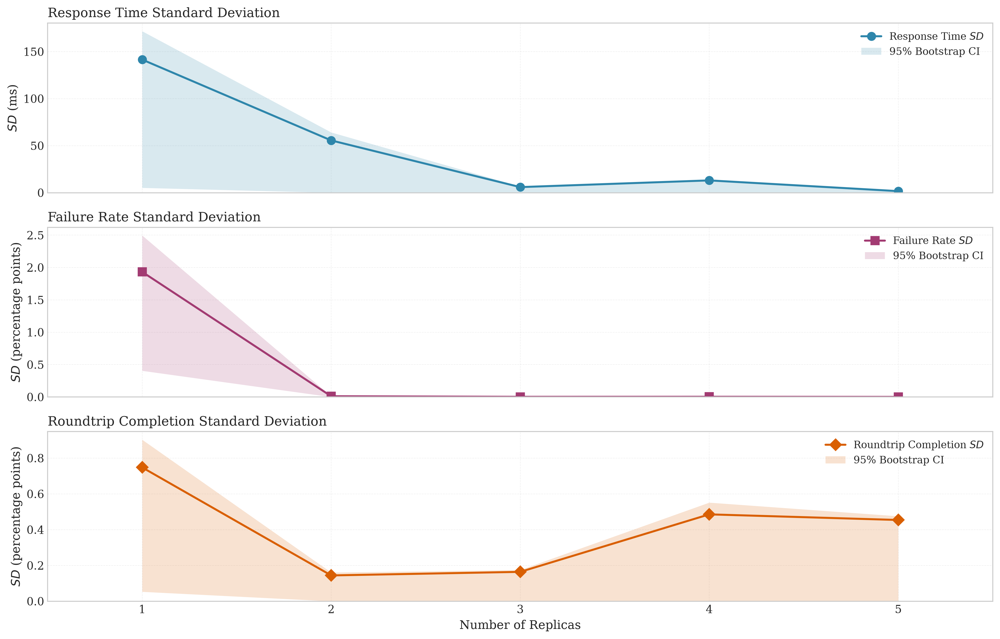

,replicas,metric,trials,sd,ci_lower,ci_upper
0,1,response_time,4,141.5460,5.2272,171.7506
1,1,failure_rate,4,1.9329,0.4052,2.4959
2,1,roundtrip_completion,4,0.7481,0.0531,0.9032
3,2,response_time,3,55.6052,0.0000,64.1686
4,2,failure_rate,3,0.0113,0.0000,0.0115
5,2,roundtrip_completion,3,0.1443,0.0000,0.1608
6,3,response_time,3,5.9756,0.0000,6.6751
7,3,failure_rate,3,0.0023,0.0000,0.0026
8,3,roundtrip_completion,3,0.1642,0.0000,0.1749
9,4,response_time,3,13.1074,0.0000,13.1088


In [264]:


# =============================================================
# Configuration
# =============================================================

# Select any combination, in the desired display order:
selected_metrics = [
    "response_time",
    "failure_rate",
    "roundtrip_completion",
]

# For failure rate only:
# selected_metrics = ["failure_rate"]

confidence_level = 0.95
n_bootstrap = 10_000
random_seed = 42

output_dir = Path("../figures")
output_dir.mkdir(parents=True, exist_ok=True)

# =============================================================
# Metric Definitions
# =============================================================

metrics = {
    "response_time": {
        "column": "mean_response_time",
        "title": "Response Time Standard Deviation",
        "label": r"Response Time $\it{SD}$",
        "ylabel": r"$\it{SD}$ (ms)",
        "color": "#2E86AB",
        "marker": "o",
    },
    "failure_rate": {
        "column": "failure_rate",
        "title": "Failure Rate Standard Deviation",
        "label": r"Failure Rate $\it{SD}$",
        "ylabel": r"$\it{SD}$ (percentage points)",
        "color": "#A23B72",
        "marker": "s",
        "scale": 100.0,
    },
    "roundtrip_completion": {
        "column": "roundtrip_completion_percentage",
        "title": "Roundtrip Completion Standard Deviation",
        "label": r"Roundtrip Completion $\it{SD}$",
        "ylabel": r"$\it{SD}$ (percentage points)",
        "color": "#D95F02",
        "marker": "D",
    },
}

if not selected_metrics:
    raise ValueError("Select at least one metric.")

if len(set(selected_metrics)) != len(selected_metrics):
    raise ValueError("Duplicate metrics are not allowed.")

unknown = set(selected_metrics) - set(metrics)
if unknown:
    raise ValueError(f"Unknown metrics: {unknown}")

# =============================================================
# Data Preparation
# =============================================================

df_u = merged_trial_summary_df.copy()

# Extract replica count from autoscaler label.
df_u["replicas"] = (
    df_u["autoscaler"].str.extract(r"(\d+)$")[0].astype(int)
)

df_u = df_u.sort_values(["replicas", "trial_id"])

if df_u.duplicated(["replicas", "trial_id"]).any():
    raise ValueError(
        "Expected one observation per replica count and trial."
    )

# =============================================================
# Bootstrap Standard Deviation Confidence Intervals
# =============================================================

def bootstrap_sd(
    values,
    *,
    confidence_level=0.95,
    n_bootstrap=10_000,
    rng=None,
):
    """
    Calculate sample standard deviation and a percentile
    bootstrap confidence interval.

    Resampling unit: independent trial.

    Returns
    -------
    sd : float
        Observed sample standard deviation (ddof=1).
    lower : float
        Lower bootstrap confidence bound.
    upper : float
        Upper bootstrap confidence bound.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    n = len(values)

    if n < 2:
        return np.nan, np.nan, np.nan

    if rng is None:
        rng = np.random.default_rng()

    sd = np.std(values, ddof=1)

    # Resample trials with replacement.
    samples = rng.choice(
        values,
        size=(n_bootstrap, n),
        replace=True,
    )

    bootstrap_sds = np.std(
        samples,
        axis=1,
        ddof=1,
    )

    alpha = 1 - confidence_level

    lower, upper = np.quantile(
        bootstrap_sds,
        [alpha / 2, 1 - alpha / 2],
    )

    return sd, lower, upper


# =============================================================
# Calculate Standard Deviations by Replica Count
# =============================================================

rng = np.random.default_rng(random_seed)

results = []

for replicas, group in df_u.groupby("replicas", sort=True):

    for metric_name in selected_metrics:

        metric = metrics[metric_name]
        column = metric["column"]

        values = pd.to_numeric(
            group[column], errors="coerce"
        ).dropna().to_numpy(dtype=float)

        # Convert fractional failure rates to percentage points.
        scale = metric.get("scale", 1.0)
        values = values * scale

        sd, lower, upper = bootstrap_sd(
            values,
            confidence_level=confidence_level,
            n_bootstrap=n_bootstrap,
            rng=rng,
        )

        results.append({
            "replicas": replicas,
            "metric": metric_name,
            "trials": len(values),
            "sd": sd,
            "ci_lower": lower,
            "ci_upper": upper,
        })

sd_results_df = pd.DataFrame(results)

# =============================================================
# Global Style — Consistent with CV Figure
# =============================================================

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11
plt.rcParams["legend.fontsize"] = 10
plt.rcParams["figure.dpi"] = 300

# =============================================================
# Figure Layout — Dynamic Panel Count
# =============================================================

n_panels = len(selected_metrics)

fig, axes = plt.subplots(
    n_panels,
    1,
    figsize=(14, 3 * n_panels),
    sharex=True,
    squeeze=False,
)

axes = axes.flatten()

replica_counts = np.sort(df_u["replicas"].unique())

x_min = replica_counts.min() - 0.5
x_max = replica_counts.max() + 0.5

# =============================================================
# Plot Selected Metrics
# =============================================================

for ax, metric_name in zip(axes, selected_metrics):

    metric = metrics[metric_name]

    subset = (
        sd_results_df[
            sd_results_df["metric"] == metric_name
        ]
        .sort_values("replicas")
    )

    x = subset["replicas"].to_numpy()
    sd = subset["sd"].to_numpy()
    lower = subset["ci_lower"].to_numpy()
    upper = subset["ci_upper"].to_numpy()

    ax.plot(
        x, sd,
        marker=metric["marker"],
        linewidth=2,
        markersize=8,
        color=metric["color"],
        label=metric["label"],
    )

    ax.fill_between(
        x, lower, upper,
        color=metric["color"],
        alpha=0.18,
        linewidth=0,
        label=f"{confidence_level:.0%} Bootstrap CI",
    )

    ax.set_ylabel(metric["ylabel"])
    ax.set_title(metric["title"], loc="left")

    ax.grid(
        True,
        which="major",
        alpha=0.3,
        linestyle="--",
        linewidth=0.5,
    )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper right")

# =============================================================
# Final Formatting
# =============================================================

axes[-1].set_xlabel("Number of Replicas")
axes[-1].set_xticks(replica_counts)

plt.tight_layout()

metric_suffix = "_".join(selected_metrics)

output_file = (
    output_dir /
    f"experiment_1_sd_{metric_suffix}_by_replica_count.png"
)

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# =============================================================
# Display Numerical Results
# =============================================================

display(sd_results_df.round(4))


Throughput stability (using CV)

I'm not going to use this

KeyError: 'mean_roundtrip_completion_percentage'

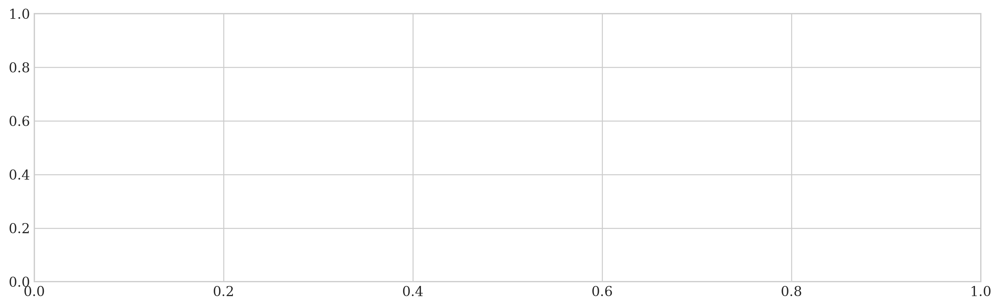

In [265]:
# Index(['autoscaler', 'trials', 'mean_rt', 'median_rt', 'sd_rt',
#        'mean_failure_rate', 'median_failure_rate', 'sd_failure_rate',
#        'mean_p99_response_time', 'median_p99_response_time',
#        'sd_p99_response_time', 'mean_roundtrip_completion_percentage',
#        'median_roundtrip_completion_percentage',
#        'sd_roundtrip_completion_percentage', 'total_quantity_ordered',
#        'total_quantity_placed', 'total_quantity_filled', 'ci95_rt',
#        'ci95_failure_rate', 'ci95_roundtrip_completion_percentage',
#        'pooled_roundtrip_completion_percentage'],
#       dtype='str')

# --- Figure 2: Throughput Stability ---
fig2, axes2 = plt.subplots(1, 1, figsize=(14, 4))
fig2.subplots_adjust(wspace=0.25)

color_tertiary = '#F18F01'
panel_labels = 'ef'

ax = axes2


# --- Throughput Coefficient of Variation ---
throughput_cv = (
    df_u['mean_roundtrip_completion_percentage'] /
    df_u['sd_roundtrip_completion_percentage']
)

ax.plot(df_u['replicas'], throughput_cv,
        marker='^', linewidth=2, markersize=8,
        color=color_tertiary, label='Throughput CV')

ax.set_xlabel('Number of Replicas')
ax.set_ylabel('Coefficient of Variation')
ax.set_title(f'Throughput Stability',
                loc='left')
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax.set_xticks(df_u['replicas'])
ax.legend()
ax.set_xlim(df_u['replicas'].min() - 0.5,
            df_u['replicas'].max() + 0.5)

plt.tight_layout()
plt.savefig('../figures/experiment_1_throughput_stability_by_replica_count.png',
            dpi=300, bbox_inches='tight')
plt.show()

## ANOVA

Baseline is one replica

H0: All group means are equal <br/>
H1: At least one group mean is different 


In [266]:
trial_summary_df

,autoscaler,trial_id,successful_requests,mean_response_time,sd_response_time,p99_response_time,unmodified_mean_response_time,sd_unmodified_response_time,requests,failures,failure_rate,sd_failure_rate
0,horizontal-1,trial0001,197259,1742.746271,5642.414862,40542.647503,2564.578632,10193.562240,385410,188151,0.488184,0.499861
1,horizontal-1,trial0005,185888,1732.291899,5047.101550,33435.088666,2343.561864,9565.006531,389956,204068,0.523310,0.499457
2,horizontal-1,trial0012,205833,1445.265505,4666.704499,29254.783241,2364.815657,9833.452797,395893,190060,0.480079,0.499604
3,horizontal-1,trial0016,196075,1575.709634,4991.805205,32723.785974,2312.098626,9665.061074,397298,201223,0.506479,0.499959
4,horizontal-2,trial0002,692343,577.471440,601.139882,2304.211624,577.030219,600.983757,693085,742,0.001071,0.032702
5,horizontal-2,trial0006,673464,688.614644,741.875584,2641.382262,688.203808,742.132105,674051,587,0.000871,0.029497
6,horizontal-2,trial0010,687177,629.695988,680.242724,2587.915147,629.235283,680.278529,687908,731,0.001063,0.032581
7,horizontal-3,trial0003,766148,131.344768,199.553985,814.845322,131.343671,199.543278,766279,131,0.000171,0.013074
8,horizontal-3,trial0007,776999,134.504407,196.777564,806.639267,134.503216,196.765547,777147,148,0.000190,0.013799
9,horizontal-3,trial0013,772591,142.906376,202.039266,821.095080,142.961841,204.169197,772758,167,0.000216,0.014699


In [267]:
merged_trial_summary_df.columns

Index(['autoscaler', 'trial_id', 'successful_requests', 'mean_response_time',
       'sd_response_time', 'p99_response_time',
       'unmodified_mean_response_time', 'sd_unmodified_response_time',
       'requests', 'failures', 'failure_rate', 'sd_failure_rate',
       'quantity_ordered', 'quantity_placed', 'quantity_filled',
       'roundtrip_completion_percentage'],
      dtype='str')

In [268]:
def replace_small_floats(match):
    # Convert the matched string to a float
    val = float(match.group(0))
    # Check if it is strictly less than 0.001
    if val < 0.001:
        return "$< .001$"
    # Otherwise, leave the original number unchanged
    return match.group(0)

In [269]:
def analyze_raw_scalability(df):
    results_list = []
    
    # Make a copy of the dataframe
    data = df.copy()

    # Add replica column
    data['replicas'] = data["autoscaler"].str[-1].astype(int)

    
    metrics = {
        'mean_response_time': 'Response Time (Mean)',
        'failure_rate': 'Failure Rate (Weighted)',
        'requests': 'Throughput (Total Requests)',
        'roundtrip_completion_percentage': 'Roundtrip Completion %'
    }
    
    for col, label in metrics.items():
        # Prepare groups for 1, 2, 3, and 4 replicas
        groups = [data[data['replicas'] == i][col].dropna() for i in [1, 2, 3, 4, 5]]
        
        # Validate data presence
        if any(len(g) == 0 for g in groups):
            continue

        # Step 1: Omnibus Tests
        f_stat, p_anova = stats.f_oneway(*groups)
        h_stat, p_kruskal = stats.kruskal(*groups)
        
        # Step 2: Post-hoc Analysis
        if p_kruskal < 0.05:
            try:
                # Dunnett's test (SciPy 1.11.0+)
                res = stats.dunnett(*groups[1:], control=groups[0])
                for i, p_val in enumerate(res.pvalue):
                    comp_replica = i + 2
                    results_list.append({
                        'Metric': label,
                        'ANOVA p-value': p_anova,
                        'Kruskal p-value': p_kruskal,
                        'Comparison': f"1 vs {comp_replica}",
                        'PostHoc p-value': p_val,
                        'Significant': "Yes" if p_val < 0.05 else "No"
                    })
            except AttributeError:
                # Fallback to Tukey HSD
                tukey = pairwise_tukeyhsd(endog=data[col], groups=data['replicas'], alpha=0.05)
                tk_df = pd.DataFrame(data=tukey.summary().data[1:], columns=tukey.summary().data[0])
                # Filter for comparisons against the baseline (replica 1)
                vs_baseline = tk_df[tk_df['group1'] == 1]
                for _, row in vs_baseline.iterrows():
                    results_list.append({
                        'Users': user_count,
                        'Metric': label,
                        'ANOVA p-value': p_anova,
                        'Kruskal p-vallue': p_kruskal,
                        'Comparison': f"1 vs {row['group2']}",
                        'PostHoc p-value': row['p-adj'],
                        'Significant': row['reject']
                    })
        else:
            # If not significant, still record the omnibus result
            results_list.append({
                'Users': user_count,
                'Metric': label,
                'ANOVA p-value': p_anova,
                'Kruskal p-value': p_kruskal,
                'Comparison': "None",
                'PostHoc p-value': np.nan,
                'Significant': "No"
            })
            
    return results_list

# --- Execution and Collection ---
all_results = analyze_raw_scalability(merged_trial_summary_df)

# Create the final DataFrame
results_df = pd.DataFrame(all_results)

# Optional: Format for your dissertation (round p-values)
results_df['ANOVA p-value'] = results_df['ANOVA p-value'].apply(lambda x: f"{x:.4e}")
results_df['Kruskal p-value'] = results_df['Kruskal p-value'].apply(lambda x: f"{x:.4e}")

results_df["ANOVA p-value"] = results_df["ANOVA p-value"].astype(float)
results_df["Kruskal p-value"] = results_df["Kruskal p-value"].astype(float)


# display(results_df)
results_df = results_df.set_index(["Metric", "ANOVA p-value", "Kruskal p-value", "Comparison"])

display(results_df)

# latex = results_df.to_latex()
# print(latex)

format_apa_p = lambda x: f"{x:.3f}".lstrip("0") if x >= 0.001 else "$< .001$"

format_dict = {
    'ANOVA p-value': format_apa_p,
    'Kruskal p-value': format_apa_p,
    "PostHoc p-value": format_apa_p
}



# Apply the formatting and export to LaTeX
latex = results_df.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 ANOVA and Kruskal test results",
    label="tab:experiment-1-anova-kruskal-results",
    hrules=True
)

latex = latex.replace("%", r"\%")
latex = latex.replace("Response Time (Mean)",r"\makecell[l]{Response Time\\(Mean)}")
latex = latex.replace("Failure Rate (Weighted)", r"\makecell[l]{Failure Rate\\(Weighted)}")
latex = latex.replace("Throughput (Total Requests)", r"\makecell[l]{Throughput\\(Total\\Requests)}")
latex = latex.replace("ANOVA p-value", r"\makecell[c]{ANOVA\\p-value}")
latex = latex.replace("Kruskal p-value", r"\makecell[c]{Kruskal\\p-value}")
latex = latex.replace("PostHoc p-value", r"\makecell[c]{PostHoc\\p-value}")

float_pattern = r'-?\d*\.\d+|-?\d+\.\d*'
latex = re.sub(float_pattern, replace_small_floats, latex)

latex = latex.replace(r"\multirow[c]{9}{*}{80}", r"\addlinespace[2ex]\multirow[c]{9}{*}{80}")

old_header = r"""\toprule
 &  &  &  & \makecell[c]{PostHoc\\p-value} & Significant \\
Metric & \makecell[c]{ANOVA\\p-value} & \makecell[c]{Kruskal\\p-value} & Comparison &  &  \\
\midrule"""

new_header = r"""\toprule
Metric & \makecell[c]{ANOVA\\p-value} & \makecell[c]{Kruskal\\p-value} & Comparison & \makecell[c]{PostHoc\\p-value} & Significant \\
\midrule"""

latex = latex.replace(old_header, new_header)



pyperclip.copy(latex)

print(latex)




# To export to Excel:
# results_df.to_excel("scalability_analysis_results.xlsx", index=False)

PostHoc p-value  \
Metric                      ANOVA p-value Kruskal p-value Comparison                    
Response Time (Mean)        7.751700e-11  0.006051        1 vs 2         5.134957e-09   
                                                          1 vs 3         0.000000e+00   
                                                          1 vs 4         1.332268e-15   
                                                          1 vs 5         1.008404e-11   
Failure Rate (Weighted)     1.889200e-15  0.006709        1 vs 2         0.000000e+00   
                                                          1 vs 3         0.000000e+00   
                                                          1 vs 4         0.000000e+00   
                                                          1 vs 5         0.000000e+00   
Throughput (Total Requests) 4.999500e-16  0.016394        1 vs 2         0.000000e+00   
                                                          1 vs 3         0.000000e+00   
                                                          1 vs 4         0.000000e+00   
                                                          1 vs 5         0.000000e+00   
Roundtrip Completion %      1.448100e-08  0.006709        1 vs 2         2.331468e-15   
                                                          1 vs 3         1.677081e-10   
                                                          1 vs 4         2.446223e-07   
                                                          1 vs 5         3.083076e-06   

                                                                     Significant  
Metric                      ANOVA p-value Kruskal p-value Comparison              
Response Time (Mean)        7.751700e-11  0.006051        1 vs 2             Yes  
                                                          1 vs 3             Yes  
                                                          1 vs 4             Yes  
                                                          1 vs 5             Yes  
Failure Rate (Weighted)     1.889200e-15  0.006709        1 vs 2             Yes  
                                                          1 vs 3             Yes  
                                                          1 vs 4             Yes  
                                                          1 vs 5             Yes  
Throughput (Total Requests) 4.999500e-16  0.016394        1 vs 2             Yes  
                                                          1 vs 3             Yes  
                                                          1 vs 4             Yes  
                                                          1 vs 5             Yes  
Roundtrip Completion %      1.448100e-08  0.006709        1 vs 2             Yes  
                                                          1 vs 3             Yes  
                                                          1 vs 4             Yes  
                                                          1 vs 5             Yes

\begin{table}
\caption{Experiment 1 ANOVA and Kruskal test results}
\label{tab:experiment-1-anova-kruskal-results}
\begin{tabular}{llllrl}
\toprule
Metric & \makecell[c]{ANOVA\\p-value} & \makecell[c]{Kruskal\\p-value} & Comparison & \makecell[c]{PostHoc\\p-value} & Significant \\
\midrule
\multirow[c]{4}{*}{\makecell[l]{Response Time\\(Mean)}} & \multirow[c]{4}{*}{$< .001$} & \multirow[c]{4}{*}{0.006051} & 1 vs 2 & $< .001$ & Yes \\
 &  &  & 1 vs 3 & $< .001$ & Yes \\
 &  &  & 1 vs 4 & $< .001$ & Yes \\
 &  &  & 1 vs 5 & $< .001$ & Yes \\
\multirow[c]{4}{*}{\makecell[l]{Failure Rate\\(Weighted)}} & \multirow[c]{4}{*}{$< .001$} & \multirow[c]{4}{*}{0.006709} & 1 vs 2 & $< .001$ & Yes \\
 &  &  & 1 vs 3 & $< .001$ & Yes \\
 &  &  & 1 vs 4 & $< .001$ & Yes \\
 &  &  & 1 vs 5 & $< .001$ & Yes \\
\multirow[c]{4}{*}{\makecell[l]{Throughput\\(Total\\Requests)}} & \multirow[c]{4}{*}{$< .001$} & \multirow[c]{4}{*}{0.016394} & 1 vs 2 & $< .001$ & Yes \\
 &  &  & 1 vs 3 & $< .001$ & Yes \\
 &  &

## Scaling efficiency

In [270]:
df = merged_trial_summary_df.copy()
df['replicas'] = df["autoscaler"].str[-1].astype(int)
df = df.drop(columns=["autoscaler"])
df.columns


Index(['trial_id', 'successful_requests', 'mean_response_time',
       'sd_response_time', 'p99_response_time',
       'unmodified_mean_response_time', 'sd_unmodified_response_time',
       'requests', 'failures', 'failure_rate', 'sd_failure_rate',
       'quantity_ordered', 'quantity_placed', 'quantity_filled',
       'roundtrip_completion_percentage', 'replicas'],
      dtype='str')

I'm not going to use this one

,metric,metric_label,replicas,trials,baseline_mean,level_mean,efficiency,ci_lower,ci_upper
0,mean_response_time,Mean response time,1,4,1624.003327,1624.003327,1.000000,1.000000,1.000000
1,mean_response_time,Mean response time,2,3,1624.003327,631.927357,1.284960,1.153605,1.427493
2,mean_response_time,Mean response time,3,3,1624.003327,136.251850,3.973043,3.615551,4.283867
3,mean_response_time,Mean response time,4,3,1624.003327,100.457529,4.041517,3.495713,4.571046
4,mean_response_time,Mean response time,5,3,1624.003327,84.797920,3.830290,3.527566,4.104187
5,failure_rate,Failure rate,1,4,0.499513,0.499513,1.000000,1.000000,1.000000
6,failure_rate,Failure rate,2,3,0.499513,0.001001,249.418009,228.744948,283.005646
7,failure_rate,Failure rate,3,3,0.499513,0.000193,864.949886,776.887774,969.706358
8,failure_rate,Failure rate,4,3,0.499513,0.000068,1831.814920,1232.726639,2882.762499
9,failure_rate,Failure rate,5,3,0.499513,0.000036,2743.340209,2141.284178,3352.002055


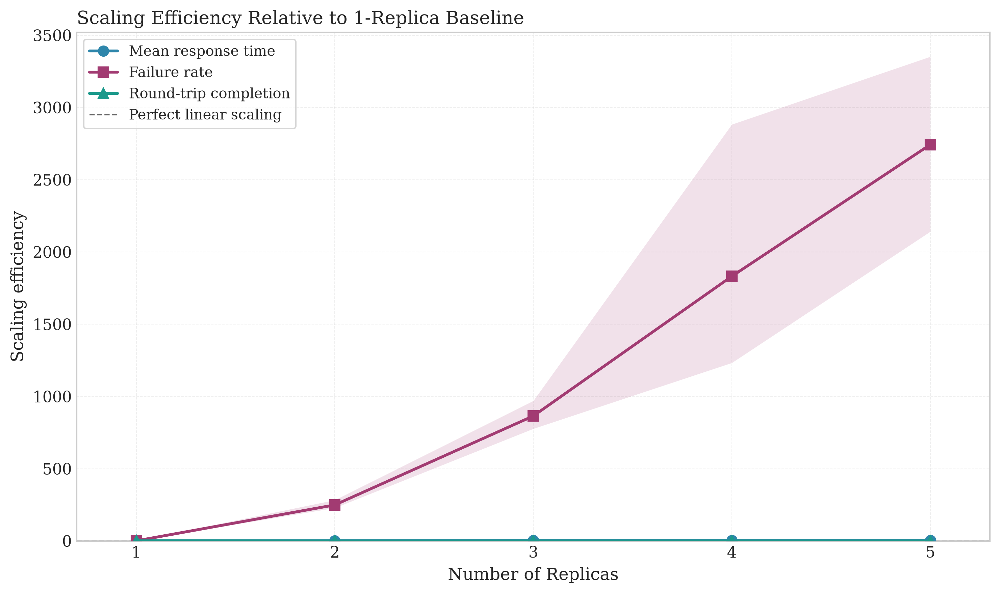

In [271]:

# ----------------------------------------------------------------------
# Scaling efficiency relative to the 1-replica baseline.
#
# Efficiency(N) = speedup(N) / N, where speedup is measured against the
# baseline (N = 1). Efficiency = 1.0 is perfect linear scaling; values
# below 1.0 indicate diminishing returns from adding replicas.
#
#   mean_response_time (lower is better):
#       speedup(N) = R(1) / R(N)   ->  efficiency = R(1) / (N * R(N))
#
#   roundtrip_completion_percentage (higher is better):
#       speedup(N) = C(N) / C(1)   ->  efficiency = C(N) / (N * C(1))
#
#   failure_rate (lower is better):
#       speedup(N) = F(1) / F(N)   ->  efficiency = F(1) / (N * F(N))
#       Undefined (NaN) when the baseline failure rate is 0.
# ----------------------------------------------------------------------

BASELINE_REPLICAS = 1
CONFIDENCE_LEVEL = 0.95
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42

# (column, direction, label). direction is "lower" or "higher" = better.
METRICS = [
    ("mean_response_time", "lower", "Mean response time"),
    ("failure_rate", "lower", "Failure rate"),
    ("roundtrip_completion_percentage", "higher", "Round-trip completion"),
]

def _efficiency(baseline_mean, level_mean, n, direction):
    """Scaling efficiency of a level mean vs the baseline mean."""
    if direction == "lower":
        # Lower is better: speedup = baseline / level.
        if level_mean == 0:
            return np.nan
        speedup = baseline_mean / level_mean
    else:
        # Higher is better: speedup = level / baseline.
        if baseline_mean == 0:
            return np.nan
        speedup = level_mean / baseline_mean
    return speedup / n

def compute_scaling_efficiency(
    trial_df,
    metrics=METRICS,
    baseline_replicas=BASELINE_REPLICAS,
    confidence_level=CONFIDENCE_LEVEL,
    n_bootstrap=N_BOOTSTRAP,
    random_seed=RANDOM_SEED,
):
    """
    Compute per-replica scaling efficiency for each metric, with a
    bootstrap confidence interval.

    Returns a tidy DataFrame with one row per (metric, replicas).
    """
    df = trial_df.copy()
    df["replicas"] = pd.to_numeric(df["replicas"], errors="raise")

    for column, _, _ in metrics:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    if baseline_replicas not in set(df["replicas"]):
        raise ValueError(
            f"No trials found at the baseline of {baseline_replicas} replica(s)."
        )

    rng = np.random.default_rng(random_seed)
    alpha = 1 - confidence_level
    replica_levels = sorted(df["replicas"].unique())

    rows = []

    for column, direction, label in metrics:
        baseline_values = (
            df.loc[df["replicas"] == baseline_replicas, column]
            .dropna()
            .to_numpy()
        )
        baseline_mean = baseline_values.mean()

        for n in replica_levels:
            level_values = (
                df.loc[df["replicas"] == n, column].dropna().to_numpy()
            )
            level_mean = level_values.mean()

            point = _efficiency(baseline_mean, level_mean, n, direction)

            # Bootstrap the efficiency by resampling trials within the
            # baseline and the current level. Efficiency is a ratio of means,
            # so a closed-form interval is not available.
            if n == baseline_replicas:
                # Efficiency is 1.0 by construction at the baseline.
                ci_lower = ci_upper = point
            elif len(baseline_values) >= 2 and len(level_values) >= 2:
                boot = np.empty(n_bootstrap)
                for b in range(n_bootstrap):
                    bl = rng.choice(
                        baseline_values, size=len(baseline_values), replace=True
                    ).mean()
                    lv = rng.choice(
                        level_values, size=len(level_values), replace=True
                    ).mean()
                    boot[b] = _efficiency(bl, lv, n, direction)
                boot = boot[np.isfinite(boot)]
                if boot.size:
                    ci_lower, ci_upper = np.quantile(
                        boot, [alpha / 2, 1 - alpha / 2]
                    )
                else:
                    ci_lower = ci_upper = np.nan
            else:
                ci_lower = ci_upper = np.nan

            rows.append(
                {
                    "metric": column,
                    "metric_label": label,
                    "replicas": n,
                    "trials": len(level_values),
                    "baseline_mean": baseline_mean,
                    "level_mean": level_mean,
                    "efficiency": point,
                    "ci_lower": ci_lower,
                    "ci_upper": ci_upper,
                }
            )

    return pd.DataFrame(rows)

# ----------------------------------------------------------------------
# Compute results
# ----------------------------------------------------------------------
efficiency_df = compute_scaling_efficiency(df) 
display(efficiency_df)

# ----------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------
plt.rcParams["font.family"] = "serif"
plt.rcParams["figure.dpi"] = 300

colors = {
    "mean_response_time": "#2E86AB",
    "failure_rate": "#A23B72",
    "roundtrip_completion_percentage": "#1B998B",
}
markers = {
    "mean_response_time": "o",
    "failure_rate": "s",
    "roundtrip_completion_percentage": "^",
}

fig, ax = plt.subplots(figsize=(10, 6))

replica_levels = sorted(efficiency_df["replicas"].unique())

for column, _, label in METRICS:
    sub = efficiency_df[efficiency_df["metric"] == column].sort_values(
        "replicas"
    )

    ax.plot(
        sub["replicas"],
        sub["efficiency"],
        marker=markers[column],
        linewidth=2,
        markersize=7,
        color=colors[column],
        label=label,
        zorder=3,
    )

    ax.fill_between(
        sub["replicas"],
        sub["ci_lower"],
        sub["ci_upper"],
        color=colors[column],
        alpha=0.15,
        linewidth=0,
        zorder=1,
    )

# Perfect linear scaling reference.
ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.0,
    color="0.4",
    label="Perfect linear scaling",
    zorder=2,
)

ax.set_xlabel("Number of Replicas")
ax.set_ylabel("Scaling efficiency")
ax.set_title(
    "Scaling Efficiency Relative to 1-Replica Baseline", loc="left"
)
ax.set_xticks(replica_levels)
ax.set_xlim(min(replica_levels) - 0.3, max(replica_levels) + 0.3)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3, linestyle="--", linewidth=0.5)
ax.legend(frameon=True)

plt.tight_layout()
plt.savefig(
    "../figures/experiment_1_scaling_efficiency_by_replica_count.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


Use this one

,replicas,trials,baseline_throughput,throughput,speedup,efficiency,ci_lower,ci_upper
0,1,4,0.000619,0.000619,1.000000,1.000000,1.000000,1.000000
1,2,3,0.000619,0.001591,2.568021,1.284010,1.145754,1.428897
2,3,3,0.000619,0.007349,11.863959,3.954653,3.615050,4.296013
3,4,3,0.000619,0.010061,16.242387,4.060597,3.496564,4.562669
4,5,3,0.000619,0.011796,19.043759,3.808752,3.519711,4.105233


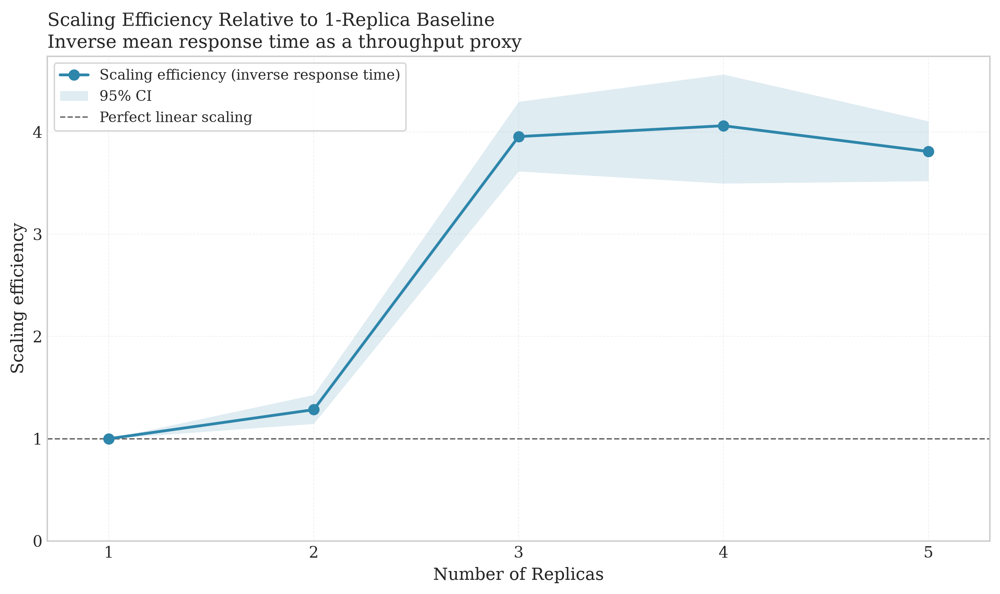

In [272]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# Scaling efficiency relative to the 1-replica baseline, using inverse
# mean response time as a throughput proxy:
#
#     X = 1 / mean_response_time   (higher is better)
#
# Efficiency(N) = speedup(N) / N = X(N) / (N * X(1)). Efficiency = 1.0 is
# perfect linear scaling; values below 1.0 indicate diminishing returns.
#
# The inverse is taken per trial and then averaged, which is the more
# correct throughput estimate and lets the bootstrap resample the actual
# per-trial quantity.
# ----------------------------------------------------------------------

BASELINE_REPLICAS = 1
CONFIDENCE_LEVEL = 0.95
N_BOOTSTRAP = 10_000
RANDOM_SEED = 42

def compute_scaling_efficiency(
    trial_df,
    baseline_replicas=BASELINE_REPLICAS,
    confidence_level=CONFIDENCE_LEVEL,
    n_bootstrap=N_BOOTSTRAP,
    random_seed=RANDOM_SEED,
):
    """
    Compute per-replica scaling efficiency from inverse response time,
    with a bootstrap confidence interval.

    Returns a tidy DataFrame with one row per replica level.
    """
    df = trial_df.copy()
    df["replicas"] = pd.to_numeric(df["replicas"], errors="raise")
    df["mean_response_time"] = pd.to_numeric(
        df["mean_response_time"], errors="coerce"
    )

    # Throughput proxy, computed per trial. Drop nonpositive response times,
    # which cannot yield a valid throughput.
    df = df[df["mean_response_time"] > 0].copy()
    df["throughput"] = 1.0 / df["mean_response_time"]

    if baseline_replicas not in set(df["replicas"]):
        raise ValueError(
            f"No trials found at the baseline of {baseline_replicas} replica(s)."
        )

    rng = np.random.default_rng(random_seed)
    alpha = 1 - confidence_level
    replica_levels = sorted(df["replicas"].unique())

    baseline_values = (
        df.loc[df["replicas"] == baseline_replicas, "throughput"]
        .dropna()
        .to_numpy()
    )
    baseline_mean = baseline_values.mean()

    rows = []

    for n in replica_levels:
        level_values = (
            df.loc[df["replicas"] == n, "throughput"].dropna().to_numpy()
        )
        level_mean = level_values.mean()

        # Efficiency: X(N) / (N * X(1)).
        point = level_mean / (n * baseline_mean)

        if n == baseline_replicas:
            # Efficiency is 1.0 by construction at the baseline.
            ci_lower = ci_upper = point
        elif len(baseline_values) >= 2 and len(level_values) >= 2:
            # Efficiency is a ratio of means, so resample trials within the
            # baseline and the current level for a bootstrap interval.
            bl = rng.choice(
                baseline_values,
                size=(n_bootstrap, len(baseline_values)),
                replace=True,
            ).mean(axis=1)
            lv = rng.choice(
                level_values,
                size=(n_bootstrap, len(level_values)),
                replace=True,
            ).mean(axis=1)
            boot = lv / (n * bl)
            boot = boot[np.isfinite(boot)]
            if boot.size:
                ci_lower, ci_upper = np.quantile(
                    boot, [alpha / 2, 1 - alpha / 2]
                )
            else:
                ci_lower = ci_upper = np.nan
        else:
            ci_lower = ci_upper = np.nan

        rows.append(
            {
                "replicas": n,
                "trials": len(level_values),
                "baseline_throughput": baseline_mean,
                "throughput": level_mean,
                "speedup": level_mean / baseline_mean,
                "efficiency": point,
                "ci_lower": ci_lower,
                "ci_upper": ci_upper,
            }
        )

    return pd.DataFrame(rows)

# ----------------------------------------------------------------------
# Compute results
# ----------------------------------------------------------------------
efficiency_df = compute_scaling_efficiency(df)  
display(efficiency_df)

# ----------------------------------------------------------------------
# Plot
# ----------------------------------------------------------------------
plt.rcParams["font.family"] = "serif"
plt.rcParams["figure.dpi"] = 300

color = "#2E86AB"

fig, ax = plt.subplots(figsize=(10, 6))

efficiency_df = efficiency_df.sort_values("replicas")
replica_levels = efficiency_df["replicas"].to_numpy()

ax.plot(
    efficiency_df["replicas"],
    efficiency_df["efficiency"],
    marker="o",
    linewidth=2,
    markersize=7,
    color=color,
    label="Scaling efficiency (inverse response time)",
    zorder=3,
)

ax.fill_between(
    efficiency_df["replicas"],
    efficiency_df["ci_lower"],
    efficiency_df["ci_upper"],
    color=color,
    alpha=0.15,
    linewidth=0,
    label=f"{CONFIDENCE_LEVEL:.0%} CI",
    zorder=1,
)

# Perfect linear scaling reference.
ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.0,
    color="0.4",
    label="Perfect linear scaling",
    zorder=2,
)

ax.set_xlabel("Number of Replicas")
ax.set_ylabel("Scaling efficiency")
ax.set_title(
    "Scaling Efficiency Relative to 1-Replica Baseline\n"
    "Inverse mean response time as a throughput proxy",
    loc="left",
)
ax.set_xticks(replica_levels)
ax.set_xlim(replica_levels.min() - 0.3, replica_levels.max() + 0.3)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3, linestyle="--", linewidth=0.5)
ax.legend(frameon=True)

plt.tight_layout()
plt.savefig(
    "../figures/experiment_1_scaling_efficiency_by_replica_count.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [273]:
baseline = 0.005226
throughput =0.014711
replicas = 3
efficiency = throughput / (replicas * baseline)
print(efficiency)


0.9383212144406176


## Analysis by API

In [274]:
log_df

,run_id,trial_id,role,autoscaler,user_id,request_type,name,response_time,response_length,response,status_code,reason,exception,start_time,url,method_and_name,success,failure
0,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,dfeb932c-885f-4859-be24-723f0929fcff,POST,/api/portfolios/bulk,42.212722,140,<Response [201]>,201,Created,None,2026-11-18 13:03:24.396322,http://kasb-20261118124252125700000012-3be888b...,POST /api/portfolios/bulk,1,0
1,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,95f1e2d2-29a0-4fe9-88e0-5e6ff023cd68,GET,/api/portfolios/{id},24.795519,133,<Response [200]>,200,OK,None,2026-11-18 13:03:24.965653,http://kasb-20261118124252125700000012-3be888b...,GET /api/portfolios/{id},1,0
2,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,4f0be7dc-4f91-489d-9920-affd46356449,POST,/api/portfolios/bulk,17.207027,140,<Response [201]>,201,Created,None,2026-11-18 13:03:25.139030,http://kasb-20261118124252125700000012-3be888b...,POST /api/portfolios/bulk,1,0
3,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,984ebd9a-8c9b-4053-8d65-5e2cc8c0d1da,POST,/api/portfolios/bulk,18.590194,140,<Response [201]>,201,Created,None,2026-11-18 13:03:25.657692,http://kasb-20261118124252125700000012-3be888b...,POST /api/portfolios/bulk,1,0
4,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,b6480430-e86b-4a33-bfef-89e0db8f881c,GET,/api/portfolios/{id},15.581285,133,<Response [200]>,200,OK,None,2026-11-18 13:03:25.706929,http://kasb-20261118124252125700000012-3be888b...,GET /api/portfolios/{id},1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10566111,experiment-1-60m-7rep-xlarge-a,trial0016,trader,horizontal-1,a1dc1b48-2e7b-48ee-aed5-cf1267ca9f67,GET,/api/orders,2.210343,98,<Response [503]>,503,Service Unavailable,503 Server Error: Service Unavailable for url:...,2026-11-19 11:29:48.291159,http://kasb-20261119101001635000000012-53074d0...,GET /api/orders,0,1
10566112,experiment-1-60m-7rep-xlarge-a,trial0016,trader,horizontal-1,ef1ffd69-e424-4980-9968-999eb0a5696f,GET,/api/orders,2.078545,98,<Response [503]>,503,Service Unavailable,503 Server Error: Service Unavailable for url:...,2026-11-19 11:29:48.381188,http://kasb-20261119101001635000000012-53074d0...,GET /api/orders,0,1
10566113,experiment-1-60m-7rep-xlarge-a,trial0016,trader,horizontal-1,f022d0e2-6a45-4a8c-bd8f-8df6de19054c,GET,/api/orders,2.159610,98,<Response [503]>,503,Service Unavailable,503 Server Error: Service Unavailable for url:...,2026-11-19 11:29:48.585894,http://kasb-20261119101001635000000012-53074d0...,GET /api/orders,0,1
10566114,experiment-1-60m-7rep-xlarge-a,trial0016,trader,horizontal-1,a1dc1b48-2e7b-48ee-aed5-cf1267ca9f67,GET,/api/trades,2.158949,98,<Response [503]>,503,Service Unavailable,503 Server Error: Service Unavailable for url:...,2026-11-19 11:29:48.848811,http://kasb-20261119101001635000000012-53074d0...,GET /api/trades,0,1


### Prepare the data

In [275]:
df = log_df.copy()
df["replicas"] = df.autoscaler.str[-1]
agg_df = df.groupby(["replicas", "method_and_name"]).agg(
    response_time_mean=("response_time", "mean"),
    response_time_std=("response_time", "std"),
    requests=("response_time", "count"),
    successful_requests=("success", "sum"),
    failures=("failure", "sum"),
    failure_rate=("failure", "mean"),
    failure_rate_std=("failure", "std"),
).reset_index()

agg_df = agg_df.sort_values(by=["method_and_name", "replicas"])

api_to_microservice_map = {
    'GET /api/executions?portfolio_id={portfolio_id}': 'Execution',
    'GET /api/models/{id}': 'Order Generation', 
    'GET /api/orders': 'Order',
    'GET /api/portfolios/{id}': 'Portfolio', 
    'GET /api/rebalances/{id}': 'Order Generation',
    'GET /api/trades': 'Trade', 
    'POST /api/models': 'Order Generation',
    'POST /api/models/{id}/rebalance': 'Order Generation', 
    'POST /api/orders/batch/submit': 'Order',
    'POST /api/portfolios/bulk': 'Portfolio',
    'POST /api/rebalances/submit-positions': 'Order Generation',
    'POST /api/trade-orders/batch/submit': 'Trade', 
    'POST /api/transactions': 'Execution',
    'GET /api/balances?portfolio_id={id}': 'Portfolio Accounting',
    'GET /api/executions/{id}': 'Execution',
    'GET /api/securities': 'Security',
    'GET /api/trades?orderId': 'Trade',
    'GET /api/transactions?portfolio_id={id}': 'Portfolio Accounting'
}

agg_df["microservice"] = agg_df.method_and_name.map(api_to_microservice_map)
agg_df["name"] = agg_df.method_and_name 

agg_df


,replicas,method_and_name,response_time_mean,response_time_std,requests,successful_requests,failures,failure_rate,failure_rate_std,microservice,name
0,1,GET /api/balances?portfolio_id={id},1646.833459,7314.294069,16992,12791,4201,0.247234,0.431417,Portfolio Accounting,GET /api/balances?portfolio_id={id}
18,2,GET /api/balances?portfolio_id={id},269.905639,234.358764,10557,10551,6,0.000568,0.023834,Portfolio Accounting,GET /api/balances?portfolio_id={id}
36,3,GET /api/balances?portfolio_id={id},215.730253,137.840049,13537,13535,2,0.000148,0.012155,Portfolio Accounting,GET /api/balances?portfolio_id={id}
54,4,GET /api/balances?portfolio_id={id},175.113374,76.322061,14448,14448,0,0.000000,0.000000,Portfolio Accounting,GET /api/balances?portfolio_id={id}
72,5,GET /api/balances?portfolio_id={id},164.123728,56.791414,13629,13629,0,0.000000,0.000000,Portfolio Accounting,GET /api/balances?portfolio_id={id}
...,...,...,...,...,...,...,...,...,...,...,...
17,1,POST /api/transactions,2810.633905,10160.956561,44980,35999,8981,0.199667,0.399754,Execution,POST /api/transactions
35,2,POST /api/transactions,145.427967,174.849840,93464,93380,84,0.000899,0.029966,Execution,POST /api/transactions
53,3,POST /api/transactions,37.611149,55.641424,98283,98275,8,0.000081,0.009022,Execution,POST /api/transactions
71,4,POST /api/transactions,29.836907,42.396134,98231,98228,3,0.000031,0.005526,Execution,POST /api/transactions


### Latex data table for response time

In [276]:
df_pivoted = agg_df.pivot(index='method_and_name', columns='replicas', values='response_time_mean')
print(df_pivoted.columns)

format_dict = {
     "1": '{:.2f}',
     "2": '{:.2f}',
     "3": '{:.2f}',
     "4": '{:.2f}',
     "5": '{:.2f}',
}



# Apply the formatting and export to LaTeX
latex = df_pivoted.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 response times in milliseconds by API and replica count.",
    label="tab:experiment-1-response-time-by-api-and-replica-count",
    hrules=True
)

latex = latex.replace("%", r"\%")
latex = latex.replace("method_and_name",r"\makecell[l]{API}")
latex = latex.replace("replicas", r"\makecell[l]{Replicas}")
latex = latex.replace("_", r"\_")
latex = latex.replace("{id}", r"\{id\}")

pyperclip.copy(latex)

print(latex)

Index(['1', '2', '3', '4', '5'], dtype='str', name='replicas')
\begin{table}
\caption{Experiment 1 response times in milliseconds by API and replica count.}
\label{tab:experiment-1-response-time-by-api-and-replica-count}
\begin{tabular}{lrrrrr}
\toprule
\makecell[l]{Replicas} & 1 & 2 & 3 & 4 & 5 \\
\makecell[l]{API} &  &  &  &  &  \\
\midrule
GET /api/balances?portfolio\_id=\{id\} & 1646.83 & 269.91 & 215.73 & 175.11 & 164.12 \\
GET /api/executions/\{id\} & 2227.50 & 1286.34 & 158.96 & 113.01 & 90.51 \\
GET /api/executions?portfolio\_id={portfolio\_id} & 2654.84 & 2473.53 & 344.52 & 247.87 & 196.41 \\
GET /api/models/\{id\} & 3430.13 & 259.42 & 84.76 & 63.57 & 40.97 \\
GET /api/orders & 2644.56 & 310.59 & 237.65 & 191.51 & 174.08 \\
GET /api/portfolios/\{id\} & 3145.22 & 151.46 & 40.90 & 31.78 & 27.39 \\
GET /api/rebalances/\{id\} & 2895.84 & 237.32 & 84.52 & 64.26 & 43.02 \\
GET /api/securities & 103.12 & 62.52 & 69.95 & 78.19 & 67.62 \\
GET /api/trades & 1218.09 & 475.84 & 234.08 & 1

### Latex CV table for response time

These CVs are very high for most APIs.  They are significantly worse than preliminary experiments (which used fixed user loads).  Let's take a look at CVs by API in experiment 3 to see how they compare.

I've double checked the calculations and they look correct.

In [277]:
df_copy = agg_df.copy()
df_copy["cv"] = df_copy.response_time_std / df_copy.response_time_mean * 100
df_pivoted = df_copy.pivot(index='method_and_name', columns='replicas', values='cv')
df_pivoted

format_dict = {
     "1": '{:.2f}',
     "2": '{:.2f}',
     "3": '{:.2f}',
     "4": '{:.2f}',
     "5": '{:.2f}',
}


latex = df_pivoted.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 coefficient of variation percentage for response time by API and replica count.",
    label="tab:experiment-1-cv-by-api-and-replica-count",
    hrules=True
)

latex = latex.replace("%", r"\%")
latex = latex.replace("method_and_name",r"\makecell[l]{API}")
latex = latex.replace("replicas", r"\makecell[l]{Replicas}")
latex = latex.replace("_", r"\_")
latex = latex.replace("{id}", r"\{id\}")


pyperclip.copy(latex)

print(latex)

\begin{table}
\caption{Experiment 1 coefficient of variation percentage for response time by API and replica count.}
\label{tab:experiment-1-cv-by-api-and-replica-count}
\begin{tabular}{lrrrrr}
\toprule
\makecell[l]{Replicas} & 1 & 2 & 3 & 4 & 5 \\
\makecell[l]{API} &  &  &  &  &  \\
\midrule
GET /api/balances?portfolio\_id=\{id\} & 444.14 & 86.83 & 63.89 & 43.58 & 34.60 \\
GET /api/executions/\{id\} & 400.80 & 47.24 & 104.74 & 96.87 & 83.95 \\
GET /api/executions?portfolio\_id={portfolio\_id} & 325.54 & 36.57 & 88.08 & 68.23 & 52.38 \\
GET /api/models/\{id\} & 329.04 & 102.65 & 145.82 & 161.76 & 168.26 \\
GET /api/orders & 423.53 & 88.69 & 83.12 & 87.71 & 90.12 \\
GET /api/portfolios/\{id\} & 373.75 & 122.95 & 151.55 & 148.98 & 114.59 \\
GET /api/rebalances/\{id\} & 350.56 & 98.18 & 135.68 & 148.27 & 154.08 \\
GET /api/securities & 89.17 & 97.69 & 102.81 & 100.80 & 95.82 \\
GET /api/trades & 594.60 & 101.11 & 74.44 & 59.83 & 45.23 \\
GET /api/trades?orderId & 457.30 & 93.39 & 83.49 & 

### Latex data table for failure rate

If I use this, need to figure out a better presentation.  The zeros are misleading.

In [278]:
df_pivoted = agg_df.pivot(index='method_and_name', columns='replicas', values='failure_rate')
print(df_pivoted.columns)



format_dict = {
     "1": '{:.4f}',
     "2": '{:.4f}',
     "3": '{:.4f}',
     "4": '{:.4f}',
     "5": '{:.4f}',
}



# Apply the formatting and export to LaTeX
latex = df_pivoted.style.format(format_dict, na_rep='').to_latex(
    caption="Experiment 1 failure rate by API and replica count.",
    label="tab:experiment-1-failure-rate-by-api-and-replica-count",
    hrules=True
)

latex = latex.replace("%", r"\%")
latex = latex.replace("method_and_name",r"\makecell[l]{API}")
latex = latex.replace("replicas", r"\makecell[l]{Replicas}")
latex = latex.replace("_", r"\_")
latex = latex.replace("{id}", r"\{id\}")

pyperclip.copy(latex)

print(latex)

Index(['1', '2', '3', '4', '5'], dtype='str', name='replicas')
\begin{table}
\caption{Experiment 1 failure rate by API and replica count.}
\label{tab:experiment-1-failure-rate-by-api-and-replica-count}
\begin{tabular}{lrrrrr}
\toprule
\makecell[l]{Replicas} & 1 & 2 & 3 & 4 & 5 \\
\makecell[l]{API} &  &  &  &  &  \\
\midrule
GET /api/balances?portfolio\_id=\{id\} & 0.2472 & 0.0006 & 0.0001 & 0.0000 & 0.0000 \\
GET /api/executions/\{id\} & 0.4969 & 0.0007 & 0.0001 & 0.0000 & 0.0000 \\
GET /api/executions?portfolio\_id={portfolio\_id} & 0.2422 & 0.0007 & 0.0001 & 0.0001 & 0.0000 \\
GET /api/models/\{id\} & 0.1833 & 0.0006 & 0.0002 & 0.0000 & 0.0001 \\
GET /api/orders & 0.7761 & 0.0008 & 0.0002 & 0.0000 & 0.0000 \\
GET /api/portfolios/\{id\} & 0.5284 & 0.0009 & 0.0001 & 0.0000 & 0.0000 \\
GET /api/rebalances/\{id\} & 0.1471 & 0.0007 & 0.0001 & 0.0000 & 0.0000 \\
GET /api/securities & 0.0000 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
GET /api/trades & 0.7616 & 0.0003 & 0.0000 & 0.0000 & 0.0000 

### Plots

In [279]:
agg_df.columns

Index(['replicas', 'method_and_name', 'response_time_mean',
       'response_time_std', 'requests', 'successful_requests', 'failures',
       'failure_rate', 'failure_rate_std', 'microservice', 'name'],
      dtype='str')

Index(['replicas', 'method_and_name', 'response_time_mean',
       'response_time_std', 'requests', 'successful_requests', 'failures',
       'failure_rate', 'failure_rate_std', 'microservice', 'name'],
      dtype='str')


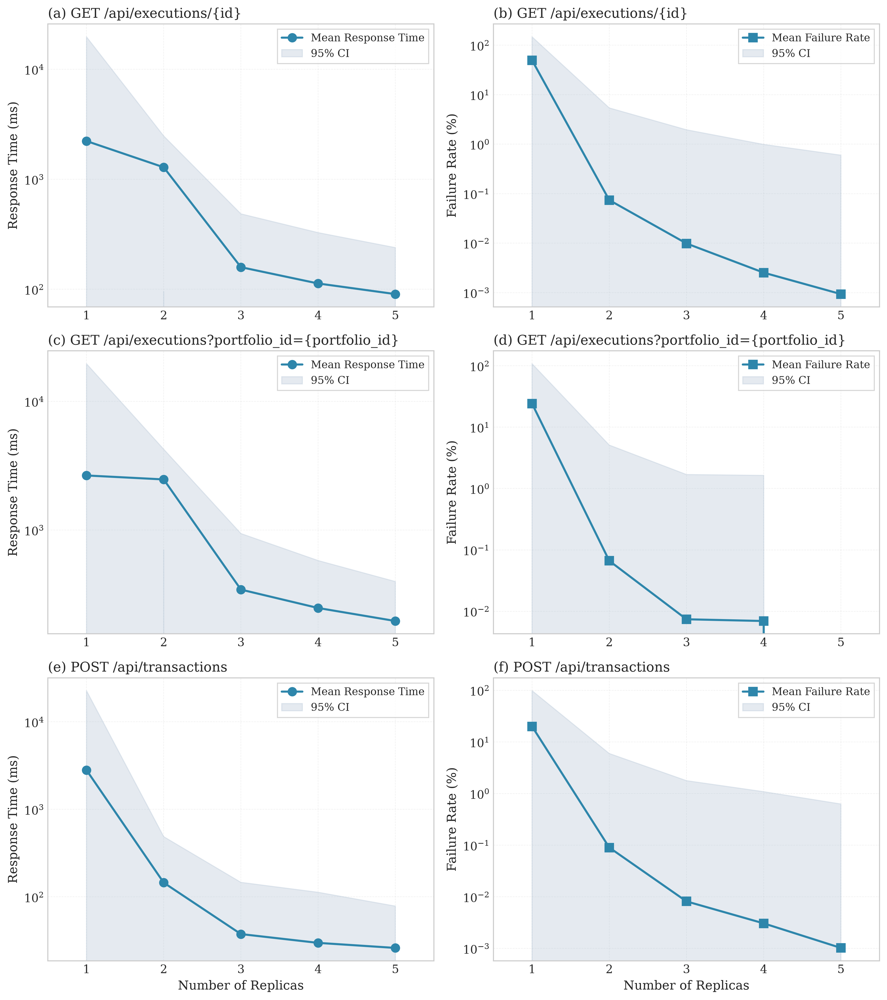

Saved: ../figures/experiment_1_replica_analysis_Execution.png


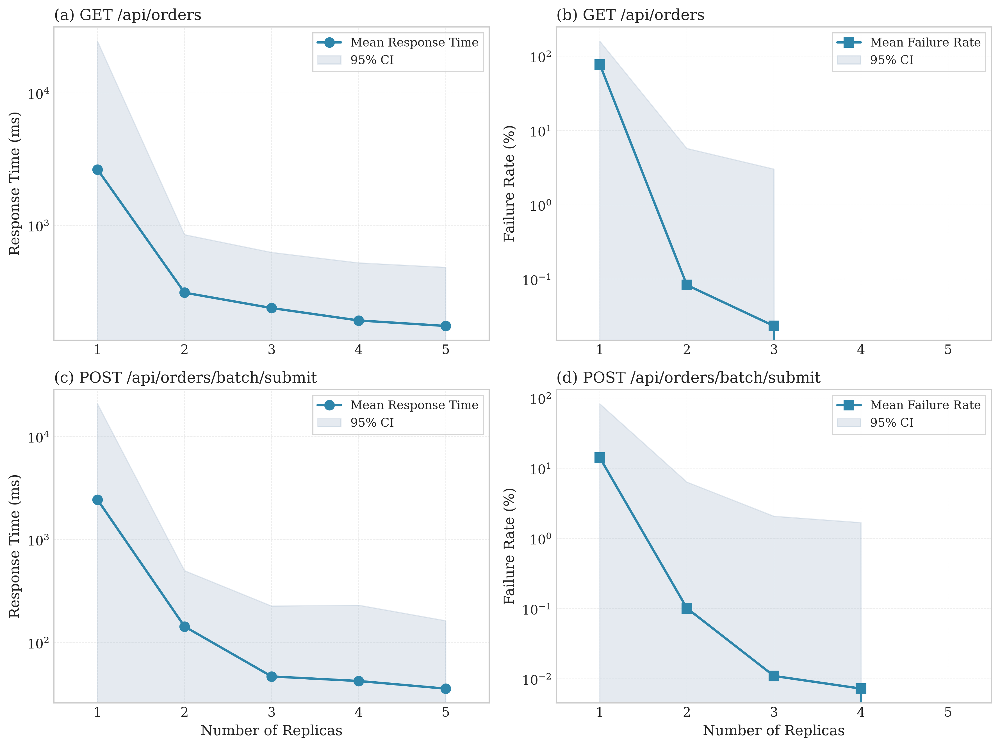

Saved: ../figures/experiment_1_replica_analysis_Order.png


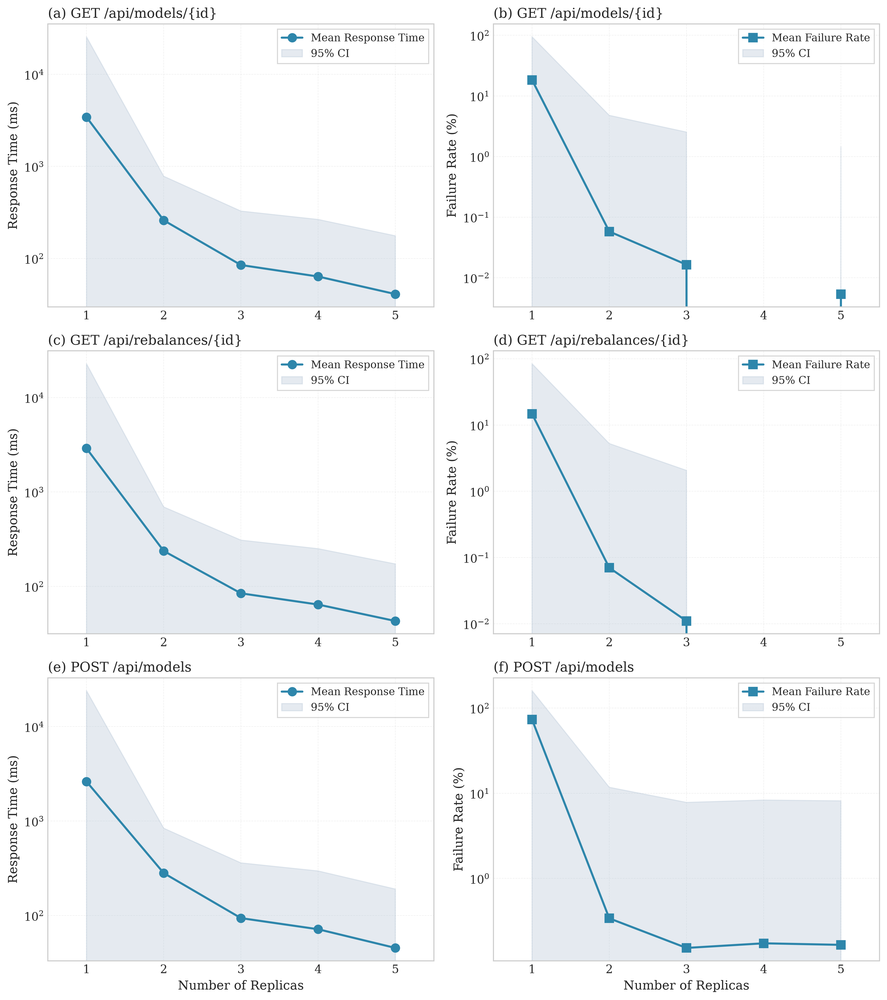

Saved: ../figures/experiment_1_replica_analysis_Order_Generation_part1.png


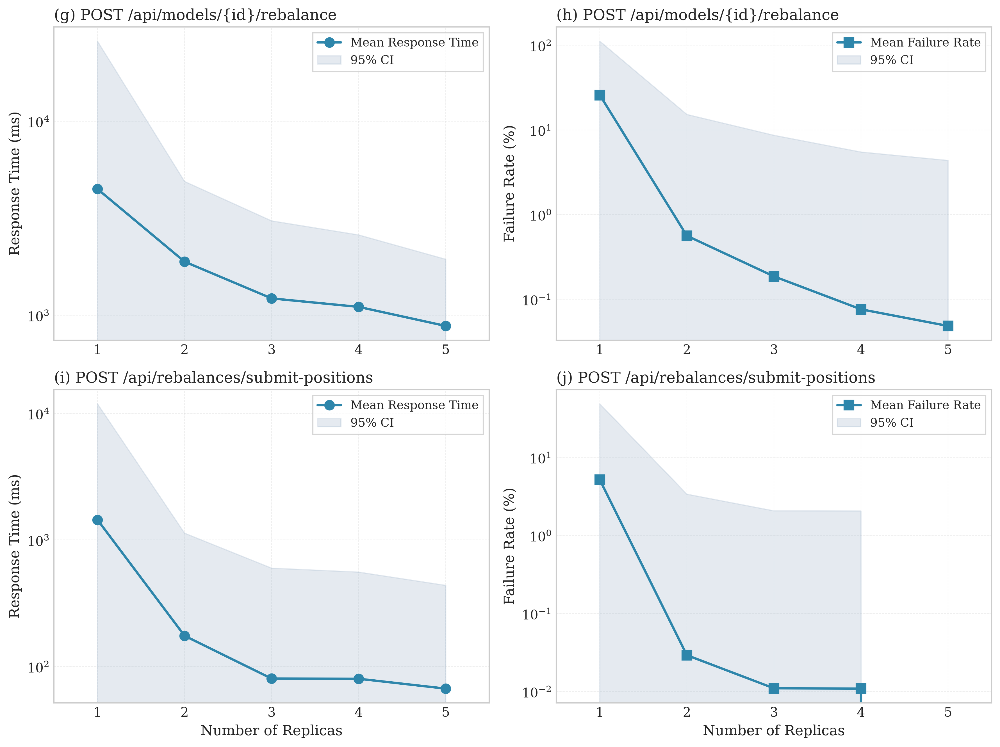

Saved: ../figures/experiment_1_replica_analysis_Order_Generation_part2.png


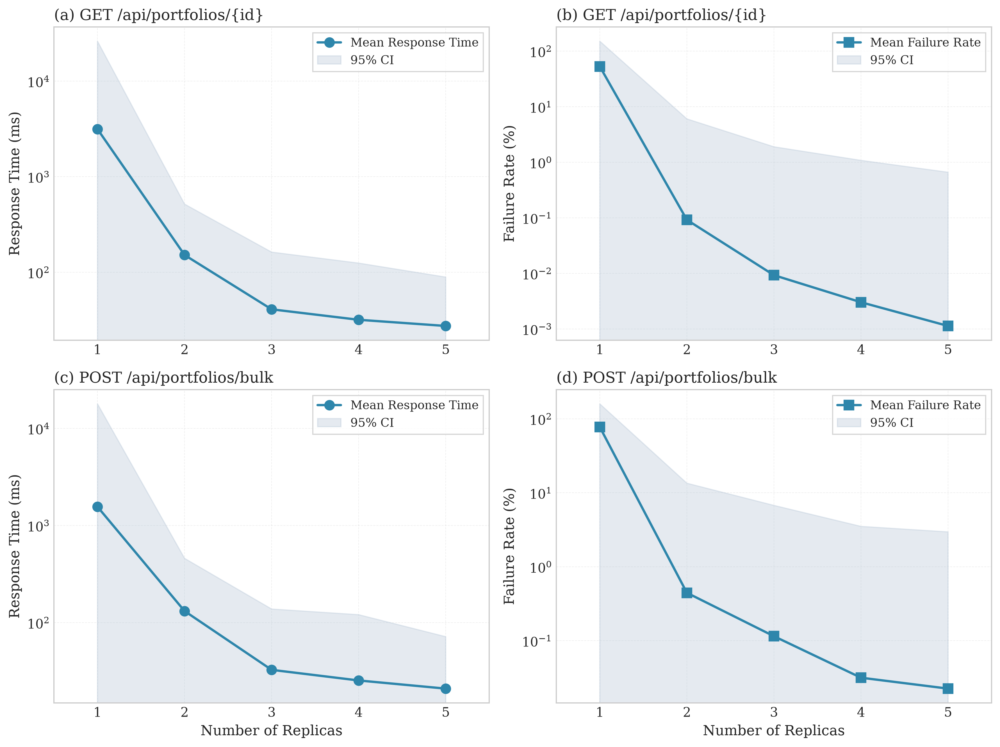

Saved: ../figures/experiment_1_replica_analysis_Portfolio.png


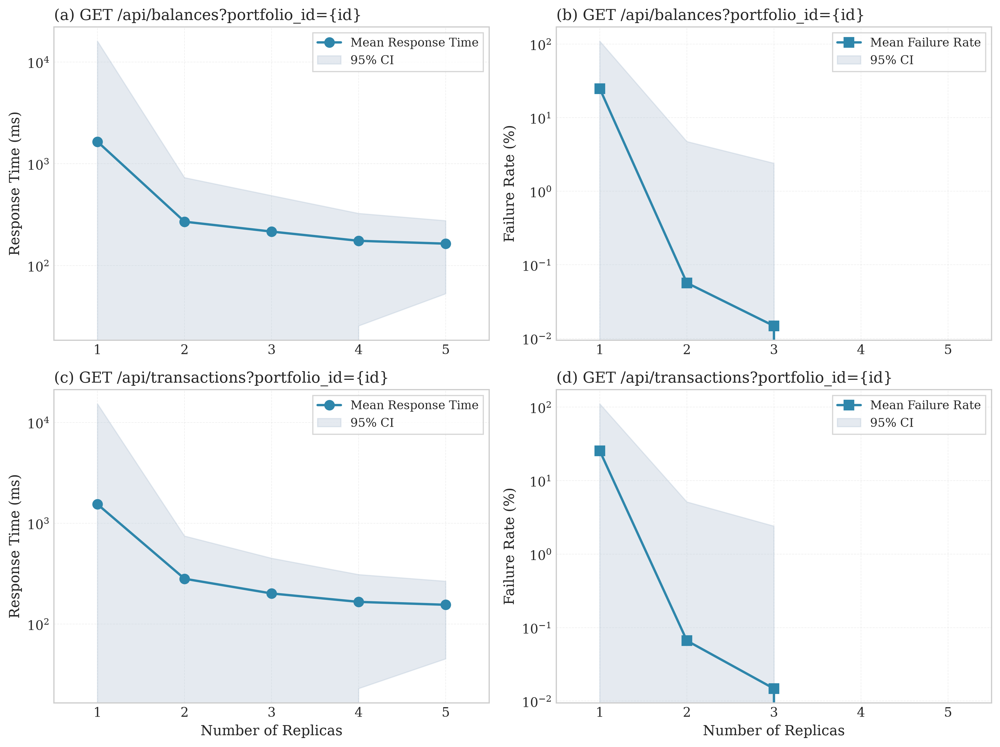

Saved: ../figures/experiment_1_replica_analysis_Portfolio_Accounting.png


/var/folders/sh/1_33sr491y7488wgvd7hldqr0000gn/T/ipykernel_69005/1099194893.py:123: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale('log')


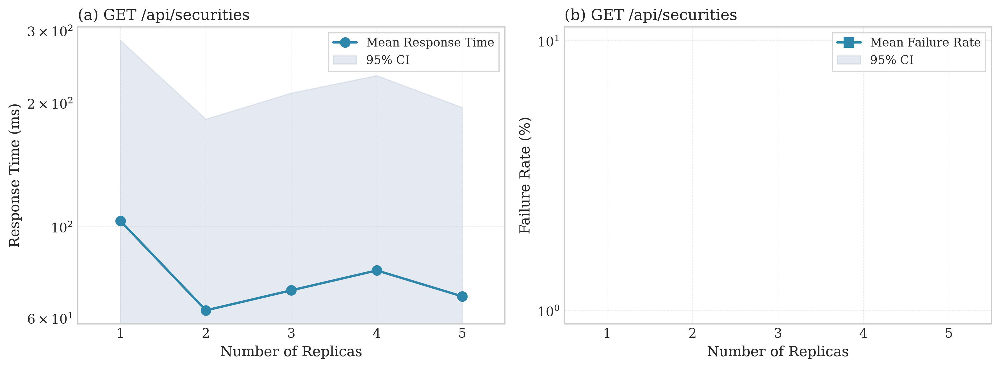

Saved: ../figures/experiment_1_replica_analysis_Security.png


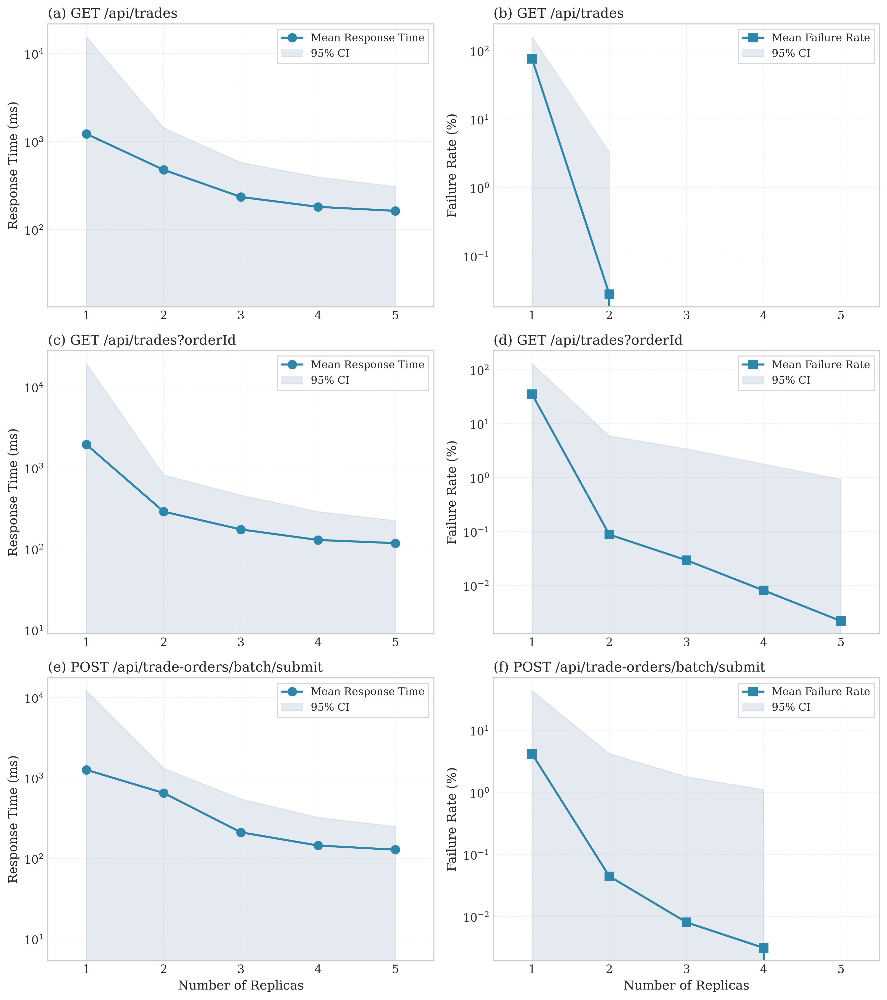

Saved: ../figures/experiment_1_replica_analysis_Trade.png

Summary Statistics (per microservice / name / replicas):

  Microservice: Execution

    API: GET /api/executions/{id}
      Response Time Range : 90.51 - 2227.50 ms
      Failure Rate Range  : 0.0009 - 49.6875 %

    API: GET /api/executions?portfolio_id={portfolio_id}
      Response Time Range : 196.41 - 2654.84 ms
      Failure Rate Range  : 0.0000 - 24.2232 %

    API: POST /api/transactions
      Response Time Range : 26.12 - 2810.63 ms
      Failure Rate Range  : 0.0010 - 19.9667 %

  Microservice: Order

    API: GET /api/orders
      Response Time Range : 174.08 - 2644.56 ms
      Failure Rate Range  : 0.0000 - 77.6079 %

    API: POST /api/orders/batch/submit
      Response Time Range : 35.67 - 2437.44 ms
      Failure Rate Range  : 0.0000 - 14.1494 %

  Microservice: Order Generation

    API: GET /api/models/{id}
      Response Time Range : 40.97 - 3430.13 ms
      Failure Rate Range  : 0.0000 - 18.3255 %

    API: G

In [280]:
df = agg_df.copy()
df.replicas = df.replicas.astype(int)
print(df.columns)
# ---------------------------------------------------------------------------
# Publication-quality rcParams (matching reference style)
# ---------------------------------------------------------------------------
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.dpi'] = 300

# Color scheme (reference)
color_primary = '#2E86AB'
color_ci       = '#A9BCD0'

# ---------------------------------------------------------------------------
# Derive CI half-widths from the std columns already in the dataframe.
# 95% CI half-width = 1.96 * std  (treating the reported std as the
# standard-error proxy produced by the load-test harness).
# ---------------------------------------------------------------------------
Z_95 = 1.96

# df['failure_rate']     = df['total_failures'] / df['total_requests']
df['response_time_ci'] = Z_95 * df['response_time_std']
df['failure_rate_ci']  = Z_95 * df['failure_rate_std']

# Work directly on the dataframe (one row per microservice/name/replicas).
agg = df[['microservice', 'name', 'replicas',
          'response_time_mean', 'response_time_ci',
          'failure_rate',      'failure_rate_ci']].copy()
agg.rename(columns={'failure_rate':      'failure_rate_mean'}, inplace=True)

# ---------------------------------------------------------------------------
# One figure per microservice (split into multiple figures if > 3 APIs)
# ---------------------------------------------------------------------------
panel_labels = 'abcdefghijklmnopqrstuvwxyz'
MAX_ROWS_PER_FIGURE = 3  # Maximum number of API rows per figure

for microservice, ms_data in agg.groupby('microservice'):
    names  = sorted(ms_data['name'].unique())
    total_apis = len(names)
    
    # Calculate how many figures we need
    num_figures = (total_apis + MAX_ROWS_PER_FIGURE - 1) // MAX_ROWS_PER_FIGURE
    
    panel_idx = 0  # running index for (a), (b), ... labels across all figures
    
    # Split the APIs into chunks
    for fig_num in range(num_figures):
        start_idx = fig_num * MAX_ROWS_PER_FIGURE
        end_idx = min(start_idx + MAX_ROWS_PER_FIGURE, total_apis)
        names_chunk = names[start_idx:end_idx]
        
        n_rows = len(names_chunk)  # one row per API name in this chunk
        n_cols = 2                  # left = response time, right = failure rate

        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(12, 4.5 * n_rows),
            squeeze=False          # always 2-D array even for 1 row
        )
        fig.subplots_adjust(hspace=0.38, wspace=0.30)

        for row, name in enumerate(names_chunk):
            nd       = ms_data[ms_data['name'] == name].sort_values('replicas')
            replicas = nd['replicas'].values

            # ----------------------------------------------------------------
            # LEFT - Response Time
            # ----------------------------------------------------------------
            ax = axes[row, 0]
            rt_mean = nd['response_time_mean'].values
            rt_ci   = nd['response_time_ci'].values

            ax.plot(replicas, rt_mean,
                    marker='o', linewidth=2, markersize=8,
                    color=color_primary, label='Mean Response Time')
            ax.fill_between(replicas,
                            rt_mean - rt_ci,
                            rt_mean + rt_ci,
                            alpha=0.3, color=color_ci, label='95% CI')

            ax.set_ylabel('Response Time (ms)', fontweight='normal')

            ax.set_yscale('log')


            ax.set_title(f'({panel_labels[panel_idx]}) {name}',
                         loc='left', fontweight='normal')
            ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
            ax.set_xticks(replicas)
            ax.set_xlim(replicas.min() - 0.5, replicas.max() + 0.5)
            ax.legend(loc='upper right', frameon=True, shadow=False, fancybox=False)

            if row == n_rows - 1:
                ax.set_xlabel('Number of Replicas', fontweight='normal')
            else:
                ax.set_xlabel('')

            panel_idx += 1

            # ----------------------------------------------------------------
            # RIGHT - Failure Rate
            # ----------------------------------------------------------------
            ax        = axes[row, 1]
            fr_pct    = nd['failure_rate_mean'].values * 100
            fr_ci_pct = nd['failure_rate_ci'].values   * 100

            ax.plot(replicas, fr_pct,
                    marker='s', linewidth=2, markersize=8,
                    color=color_primary, label='Mean Failure Rate')
            ax.fill_between(replicas,
                            fr_pct - fr_ci_pct,
                            fr_pct + fr_ci_pct,
                            alpha=0.3, color=color_ci, label='95% CI')

            ax.set_ylabel('Failure Rate (%)', fontweight='normal')

            ax.set_yscale('log')

            ax.set_title(f'({panel_labels[panel_idx]}) {name}',
                         loc='left', fontweight='normal')
            ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
            ax.set_xticks(replicas)
            ax.set_xlim(replicas.min() - 0.5, replicas.max() + 0.5)
            ax.legend(loc='upper right', frameon=True, shadow=False, fancybox=False)

            if row == n_rows - 1:
                ax.set_xlabel('Number of Replicas', fontweight='normal')
            else:
                ax.set_xlabel('')

            panel_idx += 1

        plt.tight_layout()
        safe_name = microservice.replace(' ', '_').replace('/', '_')
        
        # Add figure number suffix if multiple figures for this microservice
        if num_figures > 1:
            filename = f'../figures/experiment_1_replica_analysis_{safe_name}_part{fig_num + 1}.png'
        else:
            filename = f'../figures/experiment_1_replica_analysis_{safe_name}.png'
            
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        plt.show()
        print(f"Saved: {filename}")

# ---------------------------------------------------------------------------
# Summary statistics
# ---------------------------------------------------------------------------
print("\nSummary Statistics (per microservice / name / replicas):")
for microservice in sorted(agg['microservice'].unique()):
    print(f"\n  Microservice: {microservice}")
    for name in sorted(agg[agg['microservice'] == microservice]['name'].unique()):
        nd = agg[(agg['microservice'] == microservice) & (agg['name'] == name)]
        print(f"\n    API: {name}")
        print(f"      Response Time Range : "
              f"{nd['response_time_mean'].min():.2f} - "
              f"{nd['response_time_mean'].max():.2f} ms")
        print(f"      Failure Rate Range  : "
              f"{nd['failure_rate_mean'].min()*100:.4f} - "
              f"{nd['failure_rate_mean'].max()*100:.4f} %")

## USL Analysis

### Data prep

In [281]:
usl_df = trial_summary_df.copy()
display(usl_df)
usl_df["replicas"] = usl_df.autoscaler.str[-1].astype(int)
usl_df["throughput"] = 1.0 / usl_df.mean_response_time * 1000
# usl_df["throughput"] = usl_df.successful_requests
usl_df = usl_df.groupby(["replicas"]).agg({"throughput": ["mean", "std"]})
usl_df.columns = ["mean", "std"]
print(usl_df)

,autoscaler,trial_id,successful_requests,mean_response_time,sd_response_time,p99_response_time,unmodified_mean_response_time,sd_unmodified_response_time,requests,failures,failure_rate,sd_failure_rate
0,horizontal-1,trial0001,197259,1742.746271,5642.414862,40542.647503,2564.578632,10193.562240,385410,188151,0.488184,0.499861
1,horizontal-1,trial0005,185888,1732.291899,5047.101550,33435.088666,2343.561864,9565.006531,389956,204068,0.523310,0.499457
2,horizontal-1,trial0012,205833,1445.265505,4666.704499,29254.783241,2364.815657,9833.452797,395893,190060,0.480079,0.499604
3,horizontal-1,trial0016,196075,1575.709634,4991.805205,32723.785974,2312.098626,9665.061074,397298,201223,0.506479,0.499959
4,horizontal-2,trial0002,692343,577.471440,601.139882,2304.211624,577.030219,600.983757,693085,742,0.001071,0.032702
5,horizontal-2,trial0006,673464,688.614644,741.875584,2641.382262,688.203808,742.132105,674051,587,0.000871,0.029497
6,horizontal-2,trial0010,687177,629.695988,680.242724,2587.915147,629.235283,680.278529,687908,731,0.001063,0.032581
7,horizontal-3,trial0003,766148,131.344768,199.553985,814.845322,131.343671,199.543278,766279,131,0.000171,0.013074
8,horizontal-3,trial0007,776999,134.504407,196.777564,806.639267,134.503216,196.765547,777147,148,0.000190,0.013799
9,horizontal-3,trial0013,772591,142.906376,202.039266,821.095080,142.961841,204.169197,772758,167,0.000216,0.014699


               mean       std
replicas                     
1          0.619406  0.055809
2          1.590649  0.139766
3          7.348613  0.316876
4         10.060640  1.220725
5         11.795828  0.232369


In [282]:
# Excluding the 1 replica case, which is not useful for USL analysis ($\rho \to 1$)

usl_df = usl_df[usl_df.index > 1]
usl_df

,mean,std
replicas,,
2,1.590649,0.139766
3,7.348613,0.316876
4,10.060640,1.220725
5,11.795828,0.232369


### Plot

This is the wrong approach.  Attempting to fit the USL to a rollup is giving misleading results.  Simpson's paradox.  Even excluding the 1-replica scenario is not helping.  Jump down to USL analysis by endpoint

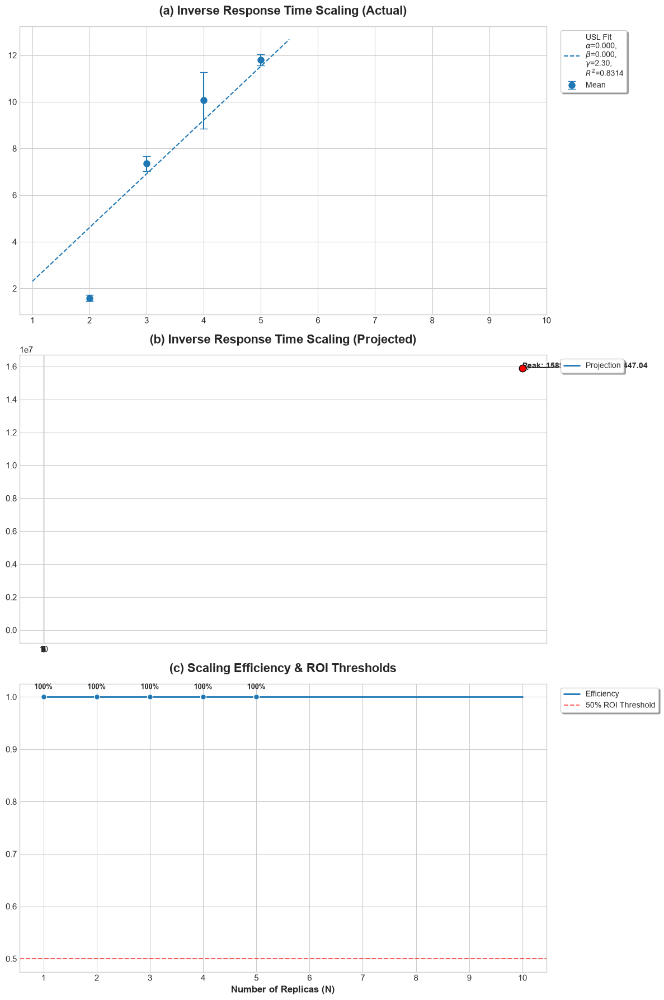

In [283]:
# --- 1. USL MODEL DEFINITIONS ---
def usl_model(N, alpha, beta, gamma):
    """The Universal Scalability Law formula."""
    return (gamma * N) / (1 + alpha * (N - 1) + beta * N * (N - 1))

def usl_efficiency(N, alpha, beta):
    """Calculates efficiency E(N)."""
    return 1 / (1 + alpha * (N - 1) + beta * N * (N - 1))

def fit_usl(df):
    """Dynamically solves for alpha, beta, and gamma based on dataframe input."""
    subset = df
    x = subset.index.values
    y = subset['mean'].values
    # Bounds ensure physical parameters stay positive/realistic
    popt, _ = curve_fit(usl_model, x, y, p0=[0.1, 0.01, y[0]], bounds=(0, [1, 1, np.inf]))
    return popt

def r_squared(y_actual, y_predicted):
    """Calculate the coefficient of determination R²."""
    ss_res = np.sum((y_actual - y_predicted) ** 2)
    ss_tot = np.sum((y_actual - np.mean(y_actual)) ** 2)
    return 1 - (ss_res / ss_tot)


# --- 2. PLOTTING SETUP ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 18), dpi=100)
n_proj = np.linspace(1, 10, 500)
colors = {40: '#1f77b4', 80: '#ff7f0e'}
markers = {40: 'o', 80: 's'}

# --- 3. EXECUTION LOOP ---
# Perform Fit
alpha, beta, gamma = fit_usl(usl_df)
c, m = colors[40], markers[40]

# Calculate R²
subset = usl_df
x_data = subset.index.values
y_data = subset['mean'].values
y_pred = usl_model(x_data, alpha, beta, gamma)
r2 = r_squared(y_data, y_pred)

# Plot 1: Throughput + Fit
subset = usl_df
ax1.errorbar(subset.index, subset['mean'], yerr=subset['std'], fmt=m, color=c, 
                label=f'Mean', capsize=5, markersize=8)
n_fit = np.linspace(1, 5.5, 100)
ax1.plot(n_fit, usl_model(n_fit, alpha, beta, gamma), color=c, linestyle='--', 
            label=f'USL Fit\n$\\alpha$={alpha:.3f}, \n$\\beta$={beta:.3f}, \n$\\gamma$={gamma:.2f}, \n$R^2$={r2:.4f}')

# Plot 2: Projection & Maxima
y_proj = usl_model(n_proj, alpha, beta, gamma)
n_max = np.sqrt((1 - alpha) / beta) if beta > 0 else 10
x_max = usl_model(n_max, alpha, beta, gamma)

ax2.plot(n_proj, y_proj, color=c, linewidth=2, label=f'Projection')
ax2.scatter(n_max, x_max, color='red', s=80, edgecolors='black', zorder=5)
ax2.fill_between(n_proj, y_proj, where=(n_proj > n_max), color=c, alpha=0.1)
ax2.annotate(f'Peak: {x_max:.1f} @ {n_max:.2f}', xy=(n_max, x_max), xytext=(n_max+0.3, x_max+1),
                arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=10, fontweight='bold')

# Plot 3: Efficiency
eff = usl_efficiency(n_proj, alpha, beta)
ax3.plot(n_proj, eff, color=c, linewidth=2, label=f'Efficiency')
n_pts = np.array([1, 2, 3, 4, 5])
eff_pts = usl_efficiency(n_pts, alpha, beta)
ax3.scatter(n_pts, eff_pts, color=c, s=50, edgecolors='white', zorder=5)
for n, e in zip(n_pts, eff_pts):
    ax3.annotate(f'{e:.0%}', (n, e), textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold')

# Formatting
ax1.set_title('(a) Inverse Response Time Scaling (Actual)', fontsize=16, fontweight='bold', pad=15)
ax2.set_title('(b) Inverse Response Time Scaling (Projected)', fontsize=16, fontweight='bold', pad=15)
ax3.set_title('(c) Scaling Efficiency & ROI Thresholds', fontsize=16, fontweight='bold', pad=15)
ax3.set_xlabel('Number of Replicas (N)', fontsize=12, fontweight='bold')
ax3.axhline(0.5, color='red', linestyle='--', alpha=0.6, label='50% ROI Threshold')

for ax in [ax1, ax2, ax3]:
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, shadow=True)
    ax.set_xticks(range(1, 11))

plt.tight_layout()

plt.savefig("../figures/experiment-1-usl-analysis.png", dpi=300, bbox_inches="tight")
plt.show()

The code above is flawed.  The following is a drop in replacement.  At 1 replica, the system violates the stability assumption of USL.  This starts at 2

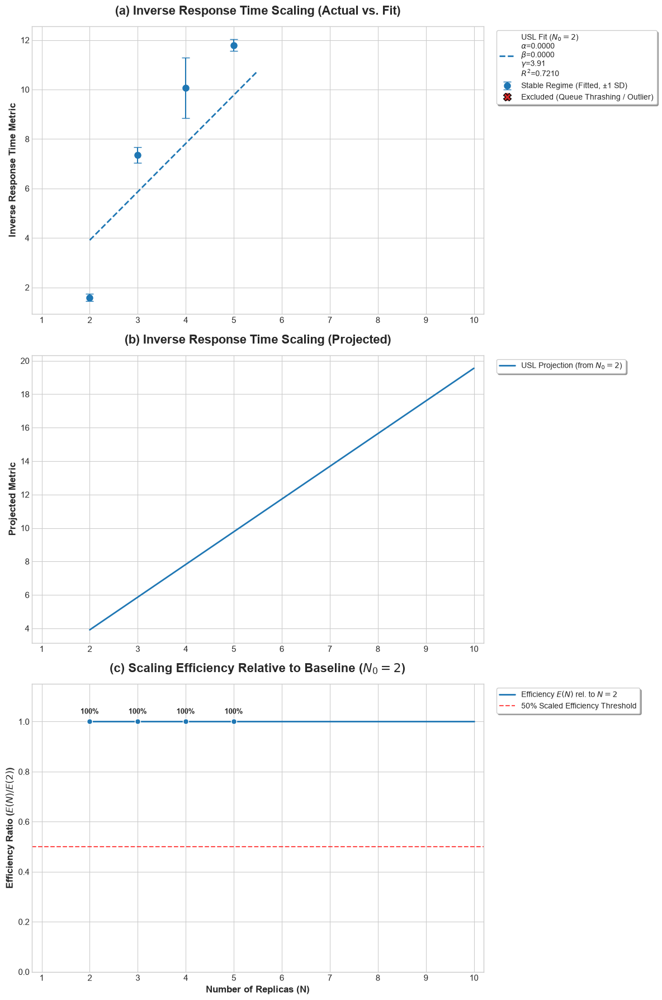

In [284]:
# --- 1. GENERALIZED USL MODEL DEFINITIONS (N0 = 2 BASELINE) ---
N0 = 2.0


def usl_model_base_n0(N, alpha, beta, gamma, n0=N0):
    """
    Generalized Universal Scalability Law referenced to an arbitrary baseline n0.
    X(N) = (gamma * (N / n0)) / (1 + alpha * (N/n0 - 1) + beta * (N/n0) * (N/n0 - 1))
    where gamma = X(n0).
    """
    N = np.asarray(N, dtype=float)
    scaled_n = N / n0
    denom = 1.0 + alpha * (scaled_n - 1.0) + beta * scaled_n * (scaled_n - 1.0)
    return (gamma * scaled_n) / denom

def usl_efficiency_base_n0(N, alpha, beta, n0=N0):
    """
    Scaling efficiency relative to the n0 baseline.
    E(n0) = 1.0 (100% baseline efficiency).
    """
    N = np.asarray(N, dtype=float)
    scaled_n = N / n0
    denom = 1.0 + alpha * (scaled_n - 1.0) + beta * scaled_n * (scaled_n - 1.0)
    return 1.0 / denom

def fit_usl_stable(df, n_min=2.0):
    """
    Extracts replica levels, filters out unstable regimes (N < n_min),
    and fits the generalized USL model weighted by measurement standard deviation.
    """
    if 'replicas' in df.columns:
        x_all = df['replicas'].to_numpy(dtype=float)
    else:
        x_all = df.index.to_numpy(dtype=float)
        
    y_all = df['mean'].to_numpy(dtype=float)
    sigma_all = df['std'].to_numpy(dtype=float) if 'std' in df.columns else None

    # Filter to stable regime
    stable_mask = x_all >= n_min
    x_stable = x_all[stable_mask]
    y_stable = y_all[stable_mask]
    sigma_stable = sigma_all[stable_mask] if sigma_all is not None else None

    # Initial guess: alpha ~ 0.05, beta ~ 0.01, gamma ~ mean at N=2
    gamma_init = y_stable[0]
    p0 = [0.05, 0.01, gamma_init]
    bounds = (0.0, [1.0, 1.0, np.inf])

    popt, _ = curve_fit(
        lambda N, a, b, g: usl_model_base_n0(N, a, b, g, n0=n_min),
        x_stable,
        y_stable,
        p0=p0,
        sigma=sigma_stable,
        absolute_sigma=True if sigma_stable is not None else False,
        bounds=bounds,
        maxfev=10000
    )

    
    return popt, (x_all, y_all, sigma_all), stable_mask, sigma_stable

def r_squared(y_actual, y_predicted):
    """Calculate R² strictly across fitted evaluation points."""
    ss_res = np.sum((y_actual - y_predicted) ** 2)
    ss_tot = np.sum((y_actual - np.mean(y_actual)) ** 2)
    return 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0


# --- 2. EXECUTION & FIT ---
(alpha, beta, gamma), (x_data, y_data, y_std), stable_mask, sigma_stable = fit_usl_stable(usl_df, n_min=2.0)

# Evaluate goodness-of-fit on stable regime (N >= 2)
x_stable = x_data[stable_mask]
y_stable = y_data[stable_mask]
y_pred_stable = usl_model_base_n0(x_stable, alpha, beta, gamma, n0=N0)
r2_val = r_squared(y_stable, y_pred_stable)


# --- 3. PLOTTING SETUP ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 18), dpi=100)

c_fit = '#1f77b4'
c_outlier = '#d62728'
n_proj = np.linspace(N0, 10, 500)
n_fit = np.linspace(N0, max(x_data) + 0.5, 200)

# Plot 1: Measured Data + USL Fit + Outlier Annotation
# Fitted points (N >= 2)
ax1.errorbar(
    x_stable, y_stable,
    yerr=y_std[stable_mask] if y_std is not None else None,
    fmt='o', color=c_fit, label='Stable Regime (Fitted, ±1 SD)',
    capsize=5, markersize=8
)

# Excluded points (N < 2)
x_excl = x_data[~stable_mask]
y_excl = y_data[~stable_mask]
std_excl = y_std[~stable_mask] if y_std is not None else None
ax1.errorbar(
    x_excl, y_excl, yerr=std_excl,
    fmt='X', color=c_outlier, label='Excluded (Queue Thrashing / Outlier)',
    capsize=5, markersize=10, markeredgecolor='black', zorder=6
)

# Plot fit line starting from N0
ax1.plot(
    n_fit, usl_model_base_n0(n_fit, alpha, beta, gamma, n0=N0),
    color=c_fit, linestyle='--', linewidth=2,
    label=f'USL Fit ($N_0={int(N0)}$)\n$\\alpha$={alpha:.4f}\n$\\beta$={beta:.4f}\n$\\gamma$={gamma:.2f}\n$R^2$={r2_val:.4f}'
)

# Outlier callout annotation
for ox, oy in zip(x_excl, y_excl):
    ax1.annotate(
        f'N={int(ox)} Excluded\n(Severe Queue Saturation)',
        xy=(ox, oy),
        xytext=(ox + 0.35, 3.6),
        arrowprops=dict(facecolor=c_outlier, edgecolor='none', arrowstyle='->', lw=1.2),
        fontsize=9, fontweight='bold', color=c_outlier,
        bbox=dict(boxstyle='round,pad=0.35', facecolor='#ffebee', edgecolor=c_outlier, alpha=0.95)
    )

# Plot 2: Scalability Projection & Peak Analysis
y_proj = usl_model_base_n0(n_proj, alpha, beta, gamma, n0=N0)
ax2.plot(n_proj, y_proj, color=c_fit, linewidth=2, label=f'USL Projection (from $N_0={int(N0)}$)')

# Scaled peak calculation for N0 reference
if beta > 1e-7 and alpha < 1.0:
    scaled_n_max = np.sqrt((1.0 - alpha) / beta)
    n_max = scaled_n_max * N0
    x_max = usl_model_base_n0(n_max, alpha, beta, gamma, n0=N0)
    
    ax2.scatter(n_max, x_max, color='red', s=80, edgecolors='black', zorder=5, label='Optimal Capacity Point')
    ax2.fill_between(n_proj, y_proj, where=(n_proj > n_max), color='red', alpha=0.1, label='Retrograde Scaling')
    ax2.annotate(
        f'Peak: {x_max:.2f} @ N={n_max:.2f}',
        xy=(n_max, x_max),
        xytext=(n_max + 0.35, x_max + 0.25),
        arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
        fontsize=10, fontweight='bold'
    )

# Plot 3: Scaling Efficiency (Normalized to N0 = 2)
eff = usl_efficiency_base_n0(n_proj, alpha, beta, n0=N0)
ax3.plot(n_proj, eff, color=c_fit, linewidth=2, label=f'Efficiency $E(N)$ rel. to $N={int(N0)}$')

n_pts = np.array([2, 3, 4, 5])
eff_pts = usl_efficiency_base_n0(n_pts, alpha, beta, n0=N0)
ax3.scatter(n_pts, eff_pts, color=c_fit, s=50, edgecolors='white', zorder=5)

for n_val, e_val in zip(n_pts, eff_pts):
    ax3.annotate(
        f'{e_val:.0%}',
        (n_val, e_val),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )

ax3.axhline(0.5, color='red', linestyle='--', alpha=0.7, label='50% Scaled Efficiency Threshold')

# --- 4. FORMATTING & DISPLAY ---
ax1.set_title('(a) Inverse Response Time Scaling (Actual vs. Fit)', fontsize=16, fontweight='bold', pad=15)
ax2.set_title('(b) Inverse Response Time Scaling (Projected)', fontsize=16, fontweight='bold', pad=15)
ax3.set_title(f'(c) Scaling Efficiency Relative to Baseline ($N_0={int(N0)}$)', fontsize=16, fontweight='bold', pad=15)

ax1.set_ylabel('Inverse Response Time Metric', fontsize=12, fontweight='bold')
ax2.set_ylabel('Projected Metric', fontsize=12, fontweight='bold')
ax3.set_ylabel(f'Efficiency Ratio ($E(N) / E({int(N0)})$)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Number of Replicas (N)', fontsize=12, fontweight='bold')

for ax in [ax1, ax2, ax3]:
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, shadow=True)
    ax.set_xticks(range(1, 11))
    ax.set_xlim(0.8, 10.2)

ax3.set_ylim(0, 1.15)

plt.tight_layout()
plt.savefig("../figures/experiment-1-usl-analysis.png", dpi=300, bbox_inches="tight")
plt.show()


In [235]:
gamma_fixed = y_stable[0]  # 6.541012

def usl_fixed_gamma(N, alpha, beta):
    scaled_n = N / 2.0
    denom = 1.0 + alpha * (scaled_n - 1.0) + beta * scaled_n * (scaled_n - 1.0)
    return (gamma_fixed * scaled_n) / denom

popt_fixed, _ = curve_fit(
    usl_fixed_gamma,
    x_stable,
    y_stable,
    p0=[0.05, 0.01],
    sigma=sigma_stable,
    absolute_sigma=True,
    bounds=(0.0, [1.0, 1.0])
)
print(f"Fixed Gamma Fit: alpha = {popt_fixed[0]:.4f}, beta = {popt_fixed[1]:.4f}")


NameError: name 'y_stable' is not defined

### USL Analysis at the endpoint level

#### Fit to USL

In [236]:
# prepare the data
df_raw = log_df.copy()
df_raw["replicas"] = df_raw["autoscaler"].str[-1].astype(int)


# Set reference baseline (use 2.0 or 3.0 based on minimum stable replica count)
N0 = 2.0

# ==============================================================================
# 1. TEST FOR SIMPSON'S PARADOX: REQUEST MIX STABILITY ACROSS REPLICAS
# ==============================================================================
def check_request_mix(df):
    """
    Computes percentage share of total requests handled by each endpoint at each replica level.
    A non-trivial shift in proportion confirms aggregation/Simpson's paradox distortion.
    """
    # Count requests per endpoint and replica
    counts = df.groupby(['replicas', 'method_and_name']).size().unstack(fill_value=0)
    # Convert to percentage of total load per replica tier
    pct_share = counts.div(counts.sum(axis=1), axis=0) * 100.0
    return pct_share.round(2)

print("--- Endpoint Request Mix Share (%) Across Replicas ---")
mix_df = check_request_mix(df_raw)
display(mix_df)
print("\n")


# ==============================================================================
# 2. DISAGGREGATED METRIC AGGREGATION
# ==============================================================================
# Filter out failed requests (timeouts/exceptions) to evaluate true service performance
successful_df = df_raw[df_raw['success'] == 1].copy()

# Compute inverse response time per request (throughput proxy: 1 / RT in seconds or ms)
# If response_time is in milliseconds, scale appropriately (e.g., 1000 / response_time)
successful_df['inv_response_time'] = 1.0 / successful_df['response_time']

# Aggregate by endpoint and replica level: mean and standard error of inverse response time
endpoint_agg = (
    successful_df.groupby(['method_and_name', 'replicas'])['inv_response_time']
    .agg(['mean', 'std', 'count'])
    .reset_index()
)
# Standard error of the mean (SE = std / sqrt(n)) for rigorous least-squares weighting
endpoint_agg['sem'] = endpoint_agg['std'] / np.sqrt(endpoint_agg['count'])


# ==============================================================================
# 3. GENERALIZED USL FITTING ENGINE
# ==============================================================================
def usl_model_base_n0(N, alpha, beta, gamma, n0=N0):
    """Generalized Universal Scalability Law referenced to baseline n0."""
    N = np.asarray(N, dtype=float)
    scaled_n = N / n0
    denom = 1.0 + alpha * (scaled_n - 1.0) + beta * scaled_n * (scaled_n - 1.0)
    return (gamma * scaled_n) / denom

def r_squared(y_actual, y_predicted):
    ss_res = np.sum((y_actual - y_predicted) ** 2)
    ss_tot = np.sum((y_actual - np.mean(y_actual)) ** 2)
    return 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

def fit_single_endpoint(sub_df, n0=N0):
    """Fits USL model for a specific endpoint across stable replicas (N >= n0)."""
    # Filter stable points
    stable = sub_df[sub_df['replicas'] >= n0].sort_values('replicas')
    if len(stable) < 3:
        return {'status': 'insufficient_points'}

    x = stable['replicas'].to_numpy(dtype=float)
    y = stable['mean'].to_numpy(dtype=float)
    sigma = stable['sem'].to_numpy(dtype=float)

    # Initial guesses
    p0 = [0.05, 0.01, y[0]]
    bounds = (0.0, [1.0, 1.0, np.inf])

    try:
        popt, _ = curve_fit(
            lambda N, a, b, g: usl_model_base_n0(N, a, b, g, n0=n0),
            x,
            y,
            p0=p0,
            sigma=sigma if not np.any(np.isnan(sigma)) else None,
            absolute_sigma=True if not np.any(np.isnan(sigma)) else False,
            bounds=bounds,
            maxfev=10000
        )
        alpha, beta, gamma = popt
        y_pred = usl_model_base_n0(x, alpha, beta, gamma, n0=n0)
        r2 = r_squared(y, y_pred)
        
        # Calculate theoretical peak replica count if beta > 0
        n_max = (np.sqrt((1.0 - alpha) / beta) * n0) if (beta > 1e-7 and alpha < 1.0) else np.nan
        
        return {
            'alpha': alpha,
            'beta': beta,
            'gamma': gamma,
            'R2': r2,
            'N_peak': n_max,
            'status': 'converged'
        }
    except Exception as e:
        return {
            'alpha': np.nan, 'beta': np.nan, 'gamma': np.nan,
            'R2': np.nan, 'N_peak': np.nan, 'status': f'failed: {str(e)}'
        }


# ==============================================================================
# 4. EXECUTION ACROSS ALL ENDPOINTS
# ==============================================================================
endpoint_results = []
for endpoint, group in endpoint_agg.groupby('method_and_name'):
    res = fit_single_endpoint(group, n0=N0)
    res['method_and_name'] = endpoint
    endpoint_results.append(res)

fit_summary_df = pd.DataFrame(endpoint_results).set_index('method_and_name')

# Display sorted by beta penalty to immediately isolate bottlenecks
fit_summary_df = fit_summary_df.sort_values(by='beta', ascending=False)
print(f"--- Per-Endpoint USL Fit Summary (Baseline N0={int(N0)}) ---")
display(fit_summary_df[['alpha', 'beta', 'gamma', 'R2', 'N_peak', 'status']])


--- Endpoint Request Mix Share (%) Across Replicas ---


method_and_name,GET /api/balances?portfolio_id={id},GET /api/executions/{id},GET /api/executions?portfolio_id={portfolio_id},GET /api/models/{id},GET /api/orders,GET /api/portfolios/{id},GET /api/rebalances/{id},GET /api/securities,GET /api/trades,GET /api/trades?orderId,GET /api/transactions?portfolio_id={id},POST /api/models,POST /api/models/{id}/rebalance,POST /api/orders/batch/submit,POST /api/portfolios/bulk,POST /api/rebalances/submit-positions,POST /api/trade-orders/batch/submit,POST /api/transactions
replicas,,,,,,,,,,,,,,,,,,
1,1.01,31.70,1.01,0.56,1.40,31.00,0.41,0.01,1.40,6.96,1.01,2.09,0.56,0.99,12.83,0.35,3.87,2.87
2,0.50,32.36,0.50,0.84,0.18,24.12,0.84,0.01,0.18,12.91,0.50,0.85,0.84,2.50,4.58,0.84,12.88,4.56
3,0.61,32.39,0.61,0.79,0.18,22.78,0.79,0.01,0.18,13.92,0.61,0.79,0.79,2.35,4.26,0.79,13.91,4.25
4,0.62,32.39,0.62,0.80,0.19,22.86,0.79,0.01,0.19,13.84,0.62,0.80,0.79,2.38,4.25,0.79,13.83,4.25
5,0.62,32.40,0.62,0.82,0.19,23.13,0.81,0.01,0.19,13.60,0.62,0.82,0.81,2.44,4.28,0.81,13.58,4.27




--- Per-Endpoint USL Fit Summary (Baseline N0=2) ---


,alpha,beta,gamma,R2,N_peak,status
method_and_name,,,,,,
POST /api/rebalances/submit-positions,5.463373e-19,2.090509e-01,0.024165,0.831322,4.374254e+00,converged
POST /api/orders/batch/submit,1.160873e-17,1.872725e-01,0.026824,0.896094,4.621607e+00,converged
GET /api/securities,1.000000e+00,1.814948e-01,0.023977,0.633814,9.893114e-08,converged
POST /api/transactions,1.499808e-16,1.565310e-01,0.033643,0.837092,5.055101e+00,converged
POST /api/portfolios/bulk,8.049621e-14,1.401086e-01,0.042527,0.827236,5.343154e+00,converged
GET /api/portfolios/{id},8.675448e-17,1.303717e-01,0.037444,0.824253,5.539088e+00,converged
GET /api/trades?orderId,1.000000e+00,4.189643e-02,0.010676,-0.107920,6.177288e-07,converged
GET /api/orders,1.000000e+00,2.850307e-02,0.007359,-0.061146,1.248215e-07,converged
GET /api/trades,1.000000e+00,2.431560e-02,0.007834,0.004485,1.351427e-07,converged


In [237]:
df_raw

,run_id,trial_id,role,autoscaler,user_id,request_type,name,response_time,response_length,response,status_code,reason,exception,start_time,url,method_and_name,success,failure,replicas
0,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,dfeb932c-885f-4859-be24-723f0929fcff,POST,/api/portfolios/bulk,42.212722,140,<Response [201]>,201,Created,None,2026-11-18 13:03:24.396322,http://kasb-20261118124252125700000012-3be888b...,POST /api/portfolios/bulk,1,0,1
1,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,95f1e2d2-29a0-4fe9-88e0-5e6ff023cd68,GET,/api/portfolios/{id},24.795519,133,<Response [200]>,200,OK,None,2026-11-18 13:03:24.965653,http://kasb-20261118124252125700000012-3be888b...,GET /api/portfolios/{id},1,0,1
2,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,4f0be7dc-4f91-489d-9920-affd46356449,POST,/api/portfolios/bulk,17.207027,140,<Response [201]>,201,Created,None,2026-11-18 13:03:25.139030,http://kasb-20261118124252125700000012-3be888b...,POST /api/portfolios/bulk,1,0,1
3,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,984ebd9a-8c9b-4053-8d65-5e2cc8c0d1da,POST,/api/portfolios/bulk,18.590194,140,<Response [201]>,201,Created,None,2026-11-18 13:03:25.657692,http://kasb-20261118124252125700000012-3be888b...,POST /api/portfolios/bulk,1,0,1
4,experiment-1-60m-7rep-xlarge-a,trial0001,back-office,horizontal-1,b6480430-e86b-4a33-bfef-89e0db8f881c,GET,/api/portfolios/{id},15.581285,133,<Response [200]>,200,OK,None,2026-11-18 13:03:25.706929,http://kasb-20261118124252125700000012-3be888b...,GET /api/portfolios/{id},1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5989118,experiment-1-60m-7rep-xlarge-a,trial0009,trader,horizontal-4,4de40af9-0116-4fad-b051-60e39f540081,POST,/api/trade-orders/batch/submit,135.096254,1055,<Response [200]>,200,OK,None,2026-11-19 01:36:13.702979,http://kasb-20261119001529334600000012-f7a2a89...,POST /api/trade-orders/batch/submit,1,0,4
5989119,experiment-1-60m-7rep-xlarge-a,trial0009,trader,horizontal-4,8ae30108-1787-4eda-9511-10a569eccd6f,GET,/api/executions/{id},170.860628,406,<Response [200]>,200,OK,None,2026-11-19 01:36:13.675904,http://kasb-20261119001529334600000012-f7a2a89...,GET /api/executions/{id},1,0,4
5989120,experiment-1-60m-7rep-xlarge-a,trial0009,trader,horizontal-4,2809172f-4f40-480d-9746-0a88740bc580,GET,/api/trades?orderId,152.212349,627,<Response [200]>,200,OK,None,2026-11-19 01:36:13.704837,http://kasb-20261119001529334600000012-f7a2a89...,GET /api/trades?orderId,1,0,4
5989121,experiment-1-60m-7rep-xlarge-a,trial0009,trader,horizontal-4,f94970f6-316e-4955-bc00-3db8b0f742ac,GET,/api/trades?orderId,161.065990,628,<Response [200]>,200,OK,None,2026-11-19 01:36:13.705332,http://kasb-20261119001529334600000012-f7a2a89...,GET /api/trades?orderId,1,0,4


#### Fit Summary to LaTeX format

In [238]:

df = fit_summary_df.copy()

df.reset_index(inplace=True)

df = df[["method_and_name", "alpha", "beta", "gamma", "R2", "N_peak"]]
display(df)


df.columns = ["API", "Alpha", "Beta", "Gamma", r"$R^2$", "Peak N"]

format_dict = {
    "Alpha": "{:.3f}",
    "Beta": "{:.3f}",
    "Gamma": "{:.3f}",
    r"$R^2$": "{:.3f}",
    "Peak N": "{:.3f}",
}


latex = df.style.format(format_dict, na_rep='').hide(axis='index').to_latex(
    caption="Experiment 1 API fit to USL.",
    label="tab:experiment-1-api-fit-to-usl",
    hrules=True
)
print(latex)
pyperclip.copy(latex)
fit_summary_df


,method_and_name,alpha,beta,gamma,R2,N_peak
0,POST /api/rebalances/submit-positions,5.463373e-19,2.090509e-01,0.024165,0.831322,4.374254e+00
1,POST /api/orders/batch/submit,1.160873e-17,1.872725e-01,0.026824,0.896094,4.621607e+00
2,GET /api/securities,1.000000e+00,1.814948e-01,0.023977,0.633814,9.893114e-08
3,POST /api/transactions,1.499808e-16,1.565310e-01,0.033643,0.837092,5.055101e+00
4,POST /api/portfolios/bulk,8.049621e-14,1.401086e-01,0.042527,0.827236,5.343154e+00
5,GET /api/portfolios/{id},8.675448e-17,1.303717e-01,0.037444,0.824253,5.539088e+00
6,GET /api/trades?orderId,1.000000e+00,4.189643e-02,0.010676,-0.107920,6.177288e-07
7,GET /api/orders,1.000000e+00,2.850307e-02,0.007359,-0.061146,1.248215e-07
8,GET /api/trades,1.000000e+00,2.431560e-02,0.007834,0.004485,1.351427e-07
9,GET /api/rebalances/{id},7.043197e-15,2.294858e-02,0.022773,0.906090,1.320237e+01


\begin{table}
\caption{Experiment 1 API fit to USL.}
\label{tab:experiment-1-api-fit-to-usl}
\begin{tabular}{lrrrrr}
\toprule
API & Alpha & Beta & Gamma & $R^2$ & Peak N \\
\midrule
POST /api/rebalances/submit-positions & 0.000 & 0.209 & 0.024 & 0.831 & 4.374 \\
POST /api/orders/batch/submit & 0.000 & 0.187 & 0.027 & 0.896 & 4.622 \\
GET /api/securities & 1.000 & 0.181 & 0.024 & 0.634 & 0.000 \\
POST /api/transactions & 0.000 & 0.157 & 0.034 & 0.837 & 5.055 \\
POST /api/portfolios/bulk & 0.000 & 0.140 & 0.043 & 0.827 & 5.343 \\
GET /api/portfolios/{id} & 0.000 & 0.130 & 0.037 & 0.824 & 5.539 \\
GET /api/trades?orderId & 1.000 & 0.042 & 0.011 & -0.108 & 0.000 \\
GET /api/orders & 1.000 & 0.029 & 0.007 & -0.061 & 0.000 \\
GET /api/trades & 1.000 & 0.024 & 0.008 & 0.004 & 0.000 \\
GET /api/rebalances/{id} & 0.000 & 0.023 & 0.023 & 0.906 & 13.202 \\
POST /api/models & 0.000 & 0.019 & 0.023 & 0.890 & 14.439 \\
GET /api/balances?portfolio_id={id} & 1.000 & 0.017 & 0.007 & -0.267 & 0.000 \\
G

,alpha,beta,gamma,R2,N_peak,status
method_and_name,,,,,,
POST /api/rebalances/submit-positions,5.463373e-19,2.090509e-01,0.024165,0.831322,4.374254e+00,converged
POST /api/orders/batch/submit,1.160873e-17,1.872725e-01,0.026824,0.896094,4.621607e+00,converged
GET /api/securities,1.000000e+00,1.814948e-01,0.023977,0.633814,9.893114e-08,converged
POST /api/transactions,1.499808e-16,1.565310e-01,0.033643,0.837092,5.055101e+00,converged
POST /api/portfolios/bulk,8.049621e-14,1.401086e-01,0.042527,0.827236,5.343154e+00,converged
GET /api/portfolios/{id},8.675448e-17,1.303717e-01,0.037444,0.824253,5.539088e+00,converged
GET /api/trades?orderId,1.000000e+00,4.189643e-02,0.010676,-0.107920,6.177288e-07,converged
GET /api/orders,1.000000e+00,2.850307e-02,0.007359,-0.061146,1.248215e-07,converged
GET /api/trades,1.000000e+00,2.431560e-02,0.007834,0.004485,1.351427e-07,converged


#### Endpoint mix to LaTeX format

In [239]:
mix_df.T

replicas,1,2,3,4,5
method_and_name,,,,,
GET /api/balances?portfolio_id={id},1.01,0.50,0.61,0.62,0.62
GET /api/executions/{id},31.70,32.36,32.39,32.39,32.40
GET /api/executions?portfolio_id={portfolio_id},1.01,0.50,0.61,0.62,0.62
GET /api/models/{id},0.56,0.84,0.79,0.80,0.82
GET /api/orders,1.40,0.18,0.18,0.19,0.19
GET /api/portfolios/{id},31.00,24.12,22.78,22.86,23.13
GET /api/rebalances/{id},0.41,0.84,0.79,0.79,0.81
GET /api/securities,0.01,0.01,0.01,0.01,0.01
GET /api/trades,1.40,0.18,0.18,0.19,0.19


#### USL Plot by Endpoint

In [240]:

# Output directory for individual endpoint figures
OUTPUT_DIR = "../figures/usl_endpoints"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Baseline reference configuration
N0 = 2.0

# --- 1. MODEL DEFINITIONS ---
def usl_model_base_n0(N, alpha, beta, gamma, n0=N0):
    """Generalized Universal Scalability Law referenced to baseline n0."""
    N = np.asarray(N, dtype=float)
    scaled_n = N / n0
    denom = 1.0 + alpha * (scaled_n - 1.0) + beta * scaled_n * (scaled_n - 1.0)
    return (gamma * scaled_n) / denom

def usl_efficiency_base_n0(N, alpha, beta, n0=N0):
    """Scaling efficiency relative to n0 baseline (E(n0) = 1.0)."""
    N = np.asarray(N, dtype=float)
    scaled_n = N / n0
    denom = 1.0 + alpha * (scaled_n - 1.0) + beta * scaled_n * (scaled_n - 1.0)
    return 1.0 / denom

def r_squared(y_actual, y_predicted):
    """Coefficient of determination R²."""
    ss_res = np.sum((y_actual - y_predicted) ** 2)
    ss_tot = np.sum((y_actual - np.mean(y_actual)) ** 2)
    return 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0


# --- 2. PREPARE RAW DATA METRICS ---
# Filter successful requests to measure uncorrupted service execution latency
df_clean = df_raw[df_raw['success'] == 1].copy()

# Compute inverse response time per request (throughput metric proxy)
df_clean['inv_rt'] = 1.0 / df_clean['response_time']

# Aggregate by endpoint and replica level
endpoint_summary = (
    df_clean.groupby(['method_and_name', 'replicas'])['inv_rt']
    .agg(['mean', 'std', 'count'])
    .reset_index()
)
# Standard error for curve_fit weighting
endpoint_summary['sem'] = endpoint_summary['std'] / np.sqrt(endpoint_summary['count'])


# --- 3. PLOTTING FUNCTION FOR A SINGLE ENDPOINT ---
def generate_endpoint_usl_plot(endpoint_name, sub_df):
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 18), dpi=100)

    c_fit = '#1f77b4'
    c_outlier = '#d62728'
    n_proj = np.linspace(N0, 10, 500)

    # Sort levels
    sub_df = sub_df.sort_values('replicas').copy()
    x_all = sub_df['replicas'].to_numpy(dtype=float)
    y_all = sub_df['mean'].to_numpy(dtype=float)
    y_std = sub_df['std'].to_numpy(dtype=float)
    y_sem = sub_df['sem'].to_numpy(dtype=float)

    # Stable mask (N >= N0)
    stable_mask = x_all >= N0
    x_stable = x_all[stable_mask]
    y_stable = y_all[stable_mask]
    sigma_stable = y_sem[stable_mask]

    # Outlier / excluded (N < N0)
    x_excl = x_all[~stable_mask]
    y_excl = y_all[~stable_mask]
    std_excl = y_std[~stable_mask]

    # Fit USL on stable regime
    p0 = [0.05, 0.01, y_stable[0]]
    bounds = (0.0, [1.0, 1.0, np.inf])
    
    try:
        popt, _ = curve_fit(
            lambda N, a, b, g: usl_model_base_n0(N, a, b, g, n0=N0),
            x_stable,
            y_stable,
            p0=p0,
            sigma=sigma_stable if not np.any(np.isnan(sigma_stable)) else None,
            absolute_sigma=True if not np.any(np.isnan(sigma_stable)) else False,
            bounds=bounds,
            maxfev=10000
        )
        alpha, beta, gamma = popt
        y_pred = usl_model_base_n0(x_stable, alpha, beta, gamma, n0=N0)
        r2_val = r_squared(y_stable, y_pred)
    except Exception as e:
        print(f"Skipping {endpoint_name} due to fit error: {e}")
        plt.close(fig)
        return

    n_fit = np.linspace(N0, max(x_all) + 0.5, 200)

    # -------------------------------------------------------------------------
    # Plot 1: Actual vs. Fit
    # -------------------------------------------------------------------------
    ax1.errorbar(
        x_stable, y_stable, yerr=y_std[stable_mask],
        fmt='o', color=c_fit, label='Stable Regime (Fitted, ±1 SD)',
        capsize=5, markersize=8
    )
    if len(x_excl) > 0:
        ax1.errorbar(
            x_excl, y_excl, yerr=std_excl,
            fmt='X', color=c_outlier, label='Excluded (Queue Thrashing / Outlier)',
            capsize=5, markersize=10, markeredgecolor='black', zorder=6
        )
        # Annotation for N=1
        for ox, oy in zip(x_excl, y_excl):
            y_span = max(y_all) - min(y_all)
            ax1.annotate(
                f'N={int(ox)} Excluded\n(Severe Queue Saturation)',
                xy=(ox, oy),
                xytext=(ox + 0.35, oy + (0.25 * y_span if y_span > 0 else 0.01)),
                arrowprops=dict(facecolor=c_outlier, edgecolor='none', arrowstyle='->', lw=1.2),
                fontsize=9, fontweight='bold', color=c_outlier,
                bbox=dict(boxstyle='round,pad=0.35', facecolor='#ffebee', edgecolor=c_outlier, alpha=0.95)
            )

    ax1.plot(
        n_fit, usl_model_base_n0(n_fit, alpha, beta, gamma, n0=N0),
        color=c_fit, linestyle='--', linewidth=2,
        label=f'USL Fit ($N_0={int(N0)}$)\n$\\alpha$={alpha:.4f}\n$\\beta$={beta:.4f}\n$\\gamma$={gamma:.4f}\n$R^2$={r2_val:.4f}'
    )

    # -------------------------------------------------------------------------
    # Plot 2: Scalability Projection & Peak Analysis
    # -------------------------------------------------------------------------
    y_proj = usl_model_base_n0(n_proj, alpha, beta, gamma, n0=N0)
    ax2.plot(n_proj, y_proj, color=c_fit, linewidth=2, label=f'USL Projection (from $N_0={int(N0)}$)')

    # Peak detection logic
    if beta > 1e-6 and alpha < 0.999:
        scaled_n_max = np.sqrt((1.0 - alpha) / beta)
        n_max = scaled_n_max * N0
        if n_max <= 10.0:
            x_max = usl_model_base_n0(n_max, alpha, beta, gamma, n0=N0)
            ax2.scatter(n_max, x_max, color='red', s=80, edgecolors='black', zorder=5, label='Optimal Capacity Point')
            ax2.fill_between(n_proj, y_proj, where=(n_proj > n_max), color='red', alpha=0.1, label='Retrograde Scaling')
            ax2.annotate(
                f'Peak: {x_max:.4f} @ N={n_max:.2f}',
                xy=(n_max, x_max),
                xytext=(n_max + 0.35, x_max + 0.05 * (max(y_proj) - min(y_proj))),
                arrowprops=dict(facecolor='black', arrowstyle='->', lw=1.2),
                fontsize=10, fontweight='bold'
            )
        else:
            ax2.text(0.03, 0.92, f'Peak beyond plot bounds: N={n_max:.2f}', transform=ax2.transAxes,
                     fontsize=10, fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    else:
        ax2.text(0.03, 0.92, 'Monotonic / Saturated: No Retrograde Peak', transform=ax2.transAxes,
                 fontsize=10, fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # -------------------------------------------------------------------------
    # Plot 3: Scaling Efficiency Relative to N0
    # -------------------------------------------------------------------------
    eff = usl_efficiency_base_n0(n_proj, alpha, beta, n0=N0)
    ax3.plot(n_proj, eff, color=c_fit, linewidth=2, label=f'Efficiency $E(N)$ rel. to $N={int(N0)}$')

    n_pts = np.array([n for n in [2, 3, 4, 5] if n in x_all])
    eff_pts = usl_efficiency_base_n0(n_pts, alpha, beta, n0=N0)
    ax3.scatter(n_pts, eff_pts, color=c_fit, s=50, edgecolors='white', zorder=5)

    for n_val, e_val in zip(n_pts, eff_pts):
        ax3.annotate(
            f'{e_val:.0%}',
            (n_val, e_val),
            textcoords="offset points",
            xytext=(0, 10),
            ha='center',
            fontsize=9,
            fontweight='bold'
        )

    ax3.axhline(0.5, color='red', linestyle='--', alpha=0.7, label='50% Scaled Efficiency Threshold')

    # -------------------------------------------------------------------------
    # Formatting
    # -------------------------------------------------------------------------
    clean_title = endpoint_name.replace('_', ' ')
    ax1.set_title(f'(a) {clean_title} — Scaling (Actual vs. Fit)', fontsize=15, fontweight='bold', pad=15)
    ax2.set_title('(b) Inverse Response Time Scaling (Projected)', fontsize=15, fontweight='bold', pad=15)
    ax3.set_title(f'(c) Scaling Efficiency Relative to Baseline ($N_0={int(N0)}$)', fontsize=15, fontweight='bold', pad=15)

    ax1.set_ylabel('Inverse Response Time (1/s)', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Projected Metric', fontsize=12, fontweight='bold')
    ax3.set_ylabel(f'Efficiency Ratio ($E(N) / E({int(N0)})$)', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Number of Replicas (N)', fontsize=12, fontweight='bold')

    for ax in [ax1, ax2, ax3]:
        ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, shadow=True)
        ax.set_xticks(range(1, 11))
        ax.set_xlim(0.8, 10.2)

    ax3.set_ylim(0, 1.15)
    plt.tight_layout()

    # Clean filename string
    safe_name = re.sub(r'[^a-zA-Z0-9_\-]', '_', endpoint_name).strip('_')
    out_file = os.path.join(OUTPUT_DIR, f"usl_{safe_name}.pdf")
    plt.savefig(out_file, dpi=300, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved: {out_file}")


# --- 4. EXECUTE FOR ALL ENDPOINTS ---
print(f"Generating USL plots for {endpoint_summary['method_and_name'].nunique()} endpoints...")
for endpoint, group in endpoint_summary.groupby('method_and_name'):
    generate_endpoint_usl_plot(endpoint, group)
print("Complete.")


Generating USL plots for 18 endpoints...
Saved: ../figures/usl_endpoints/usl_GET__api_balances_portfolio_id__id.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_executions__id.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_executions_portfolio_id__portfolio_id.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_models__id.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_orders.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_portfolios__id.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_rebalances__id.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_securities.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_trades.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_trades_orderId.pdf
Saved: ../figures/usl_endpoints/usl_GET__api_transactions_portfolio_id__id.pdf
Saved: ../figures/usl_endpoints/usl_POST__api_models.pdf
Saved: ../figures/usl_endpoints/usl_POST__api_models__id__rebalance.pdf
Saved: ../figures/usl_endpoints/usl_POST__api_orders_batch_submit.pdf
Saved: ../figures/usl_endpoints

#### Plot efficiency of all APIs

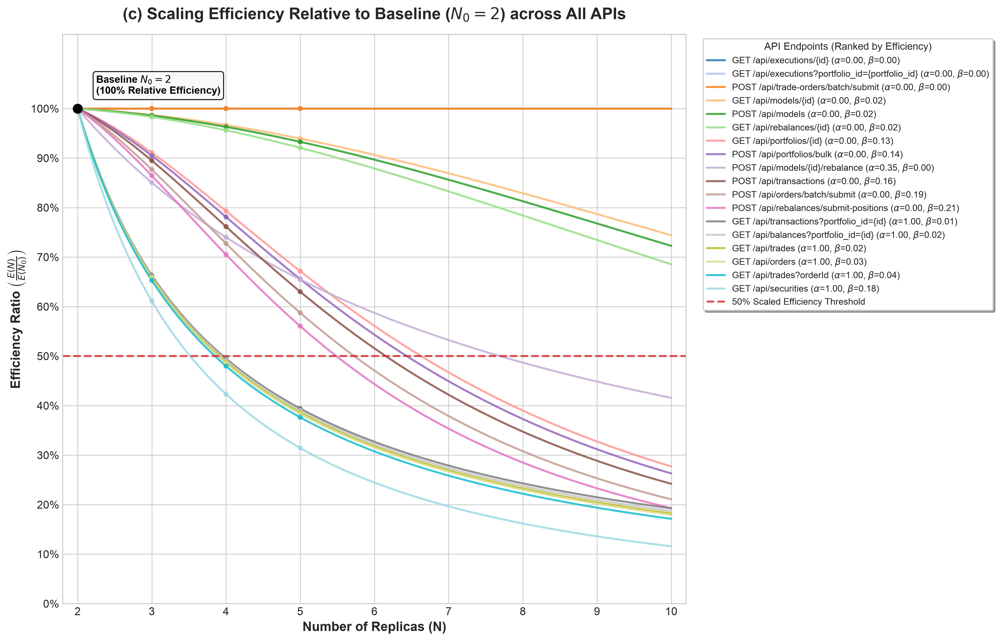

In [241]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

N0 = 2.0

# --- 1. MODEL DEFINITIONS ---
def usl_model_base_n0(N, alpha, beta, gamma, n0=N0):
    N = np.asarray(N, dtype=float)
    scaled_n = N / n0
    denom = 1.0 + alpha * (scaled_n - 1.0) + beta * scaled_n * (scaled_n - 1.0)
    return (gamma * scaled_n) / denom

def usl_efficiency_base_n0(N, alpha, beta, n0=N0):
    """Calculates scaling efficiency E(N) relative to N0."""
    N = np.asarray(N, dtype=float)
    scaled_n = N / n0
    denom = 1.0 + alpha * (scaled_n - 1.0) + beta * scaled_n * (scaled_n - 1.0)
    return 1.0 / denom

# --- 2. AGGREGATE RAW DATA & FIT ALL ENDPOINTS ---
df_clean = df_raw[df_raw['success'] == 1].copy()
df_clean['inv_rt'] = 1.0 / df_clean['response_time']

endpoint_summary = (
    df_clean.groupby(['method_and_name', 'replicas'])['inv_rt']
    .agg(['mean', 'std', 'count'])
    .reset_index()
)
endpoint_summary['sem'] = endpoint_summary['std'] / np.sqrt(endpoint_summary['count'])

fits = {}
for endpoint, group in endpoint_summary.groupby('method_and_name'):
    sub = group[group['replicas'] >= N0].sort_values('replicas')
    if len(sub) < 3:
        continue
    x = sub['replicas'].to_numpy(dtype=float)
    y = sub['mean'].to_numpy(dtype=float)
    sigma = sub['sem'].to_numpy(dtype=float)
    
    p0 = [0.05, 0.01, y[0]]
    bounds = (0.0, [1.0, 1.0, np.inf])
    
    try:
        popt, _ = curve_fit(
            lambda N, a, b, g: usl_model_base_n0(N, a, b, g, n0=N0),
            x, y, p0=p0,
            sigma=sigma if not np.any(np.isnan(sigma)) else None,
            absolute_sigma=True if not np.any(np.isnan(sigma)) else False,
            bounds=bounds, maxfev=10000
        )
        fits[endpoint] = {'alpha': popt[0], 'beta': popt[1], 'gamma': popt[2]}
    except Exception:
        continue

# --- 3. PLOTTING COMPARATIVE EFFICIENCY ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(14, 9), dpi=300)

n_proj = np.linspace(N0, 10, 500)

# Sort endpoints by efficiency at N=5 for clean stacking in the legend
def sort_key(item):
    ep, params = item
    return usl_efficiency_base_n0(5.0, params['alpha'], params['beta'], n0=N0)

sorted_fits = sorted(fits.items(), key=sort_key, reverse=True)

# Generate a visually distinct color palette across all endpoints
colormap = plt.cm.tab20(np.linspace(0, 1, len(sorted_fits)))

for idx, (endpoint, params) in enumerate(sorted_fits):
    eff_curve = usl_efficiency_base_n0(n_proj, params['alpha'], params['beta'], n0=N0)
    color = colormap[idx]
    
    # Plot efficiency projection line
    ax.plot(
        n_proj, eff_curve, 
        color=color, linewidth=2.0, alpha=0.85,
        label=f"{endpoint} ($\\alpha$={params['alpha']:.2f}, $\\beta$={params['beta']:.2f})"
    )
    
    # Scatter discrete points at actual benchmark levels (N = 2, 3, 4, 5)
    bench_n = np.array([2.0, 3.0, 4.0, 5.0])
    bench_eff = usl_efficiency_base_n0(bench_n, params['alpha'], params['beta'], n0=N0)
    ax.scatter(bench_n, bench_eff, color=color, s=25, alpha=0.9, edgecolors='none', zorder=4)

# 50% ROI Threshold Line
ax.axhline(
    0.5, color='#d62728', linestyle='--', linewidth=2, alpha=0.8, 
    label='50% Scaled Efficiency Threshold'
)

# Anchor at N0 = 2 marker
ax.scatter([N0], [1.0], color='black', s=80, marker='o', zorder=6)
ax.annotate(
    f'Baseline $N_0=2$\n(100% Relative Efficiency)', 
    xy=(N0, 1.0), 
    xytext=(N0 + 0.25, 1.03),
    fontsize=10, fontweight='bold', color='black',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#f8f9fa', edgecolor='black', alpha=0.9)
)

# Formatting
ax.set_title('(c) Scaling Efficiency Relative to Baseline ($N_0 = 2$) across All APIs', fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Number of Replicas (N)', fontsize=13, fontweight='bold')
ax.set_ylabel(r'Efficiency Ratio $\left(\frac{E(N)}{E(N_0)}\right)$', fontsize=13, fontweight='bold')

ax.set_xlim(1.8, 10.2)
ax.set_ylim(0.0, 1.15)
ax.set_xticks(range(2, 11))
ax.set_yticks(np.linspace(0.0, 1.0, 11))
ax.yaxis.set_major_formatter('{x:.0%}')

# Place legend outside on the right with two-column layout if wide
ax.legend(
    bbox_to_anchor=(1.02, 1), loc='upper left', 
    frameon=True, shadow=True, fontsize=9, title="API Endpoints (Ranked by Efficiency)", title_fontsize=10
)

plt.tight_layout()
plt.savefig("../figures/experiment_1_all_apis_scaling_efficiency_n0_2.png", dpi=300, bbox_inches="tight")
plt.show()


# Node analysis

The analysis below shows that HORIZONTAL-5 is the maximum number of replicas that can be supported before
overloading the nodes.

In [164]:
files = common.get_s3_file_listing(s3_bucket, s3_prefix=RUN)


## Get metrics from tsdb snapshots

In [165]:
client = docker.from_env()
port = 9099

queries = []

cluster_pod_requested_query = r"""
count by (node) (
  kube_pod_info
  * on (pod, namespace) group_left()
  (kube_pod_status_phase{phase=~"Running|Pending"} == 1)
)
/
sum by (node) (kube_node_status_allocatable{resource="pods"})
"""

queries.append({"name": "cluster_pod_requested", "query": cluster_pod_requested_query})


cluster_memory_requested_query = r"""
sum by (node) (
  kube_pod_container_resource_requests{resource="memory"}
  * on (pod, namespace) group_left(node)
  (
    kube_pod_info
    * on (pod, namespace) group_left()
    (kube_pod_status_phase{phase=~"Running|Pending"} == 1)
  )
)
/
sum by (node) (
  kube_node_status_allocatable{resource="memory"}
)
"""

queries.append({"name": "cluster_memory_requested", "query": cluster_memory_requested_query})



cluster_cpu_requested_query = r"""
sum by (node) (
  kube_pod_container_resource_requests{resource="cpu"}
  * on (pod, namespace) group_left(node)
  (
    kube_pod_info
    * on (pod, namespace) group_left()
    (kube_pod_status_phase{phase=~"Running|Pending"} == 1)
  )
)
/
sum by (node) (
  kube_node_status_allocatable{resource="cpu"}
)
"""

queries.append({"name": "cluster_cpu_requested", "query": cluster_cpu_requested_query})


cpu_cores_by_node_query = r"""sum by (node) (
  kube_pod_container_resource_requests{resource="cpu"}
  * on (namespace, pod) group_left(node)
  kube_pod_info
)"""

queries.append({"name": "cpu_cores_by_node", "query": cpu_cores_by_node_query})


node_cpu_usage_query = r"""
  avg(1 - rate(node_cpu_seconds_total{mode="idle"}[2m])) by (node)"""

queries.append({"name": "node_cpu_usage", "query": node_cpu_usage_query})


total_cpu_usage_ratio = r"""1 - (
  sum by (node) (
    rate(node_cpu_seconds_total{mode="idle"}[2m])
  )
  /
  sum by (node) (
    rate(node_cpu_seconds_total[2m])
  )
)
"""

queries.append({"name": "node_cpu_usage", "query": node_cpu_usage_query})


allocatable_cpu_usage_ratio_query = r"""
sum by (node) (
  label_replace(
    rate(container_cpu_usage_seconds_total{container!="", container!="POD"}[2m]),
    "node",
    "$1",
    "instance",
    "(.*)"
  )
)
/
sum by (node) (
  kube_node_status_allocatable{resource="cpu"}
)
"""

queries.append({"name": "allocatable_cpu_usage_ratio", "query": allocatable_cpu_usage_ratio_query})

cluster_cpu_usage_query = r"""
sum by (node) (
  label_replace(
    rate(
      container_cpu_usage_seconds_total{
        container!="",
        container!="POD"
      }[2m]
    ),
    "node",
    "$1",
    "instance",
    "(.*)"
  )
)
/
sum by (node) (
  kube_node_status_allocatable{resource="cpu"}
)
"""

queries.append({"name": "cluster_cpu_usage", "query": cluster_cpu_usage_query})



results = {}
for query in queries:
  df = common.get_metric_from_tsdb(
    s3_bucket,
    files,
    query["query"],
    client=client,
    port=port)
  results[query["name"]] = df

print(results.keys())



    

dict_keys(['cluster_pod_requested', 'cluster_memory_requested', 'cluster_cpu_requested', 'cpu_cores_by_node', 'node_cpu_usage', 'allocatable_cpu_usage_ratio', 'cluster_cpu_usage'])


## Headroom analysis

In [179]:
import importlib
importlib.reload(common)


<module 'common' from '/Users/noahkrieger/projects/dissertation/kasbench/kasbench-analysis/src/common.py'>

In [186]:
results["cluster_cpu_requested"].value.describe()

count    12705.000000
mean         0.530942
std          0.145101
min          0.249312
25%          0.474187
50%          0.490000
75%          0.617062
max          0.925813
Name: value, dtype: float64

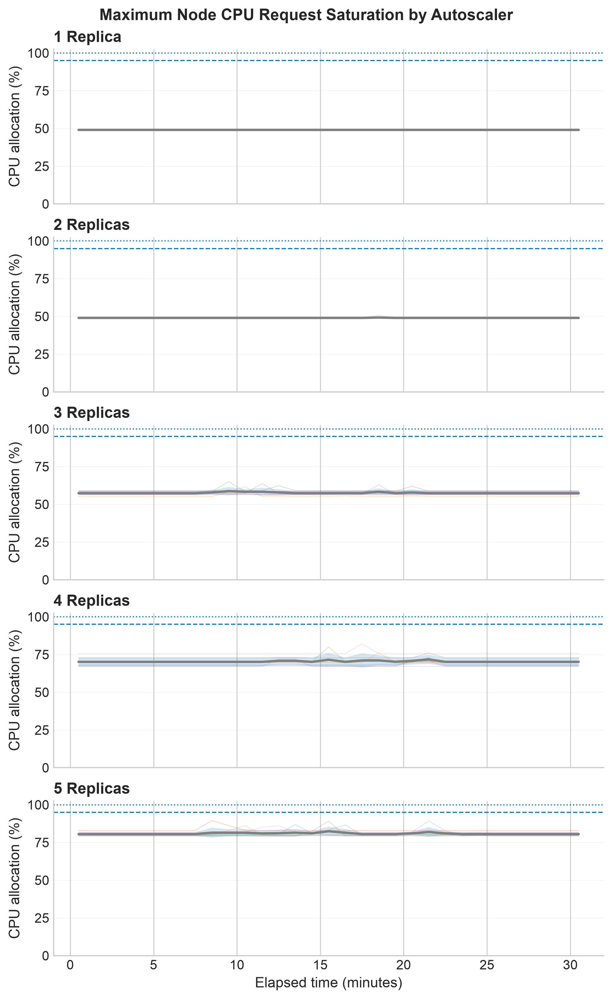

In [184]:
df = results["cluster_cpu_requested"].copy()
df.autoscaler = df.autoscaler.str[-1].astype(int)
fig, axes, cpu_trial_binned, cpu_summary = common.plot_cpu_allocation(
    df,
    bin_seconds=60,
    show_replicas=True,
)

plt.savefig("../figures/experiment_1_node_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

## Time at CPU Over-saturation

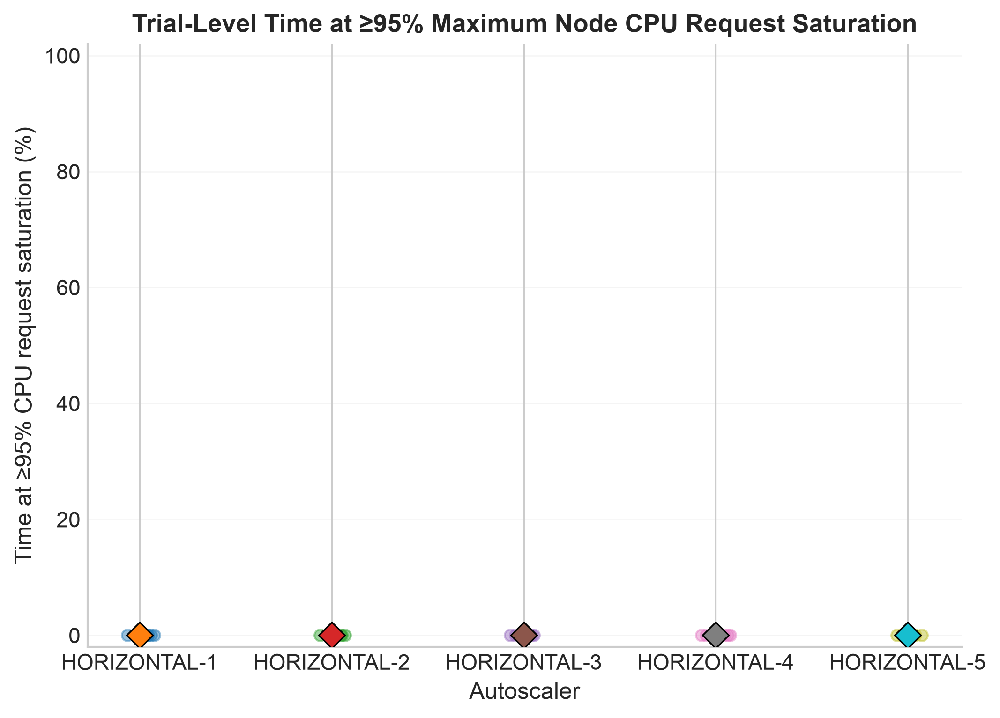

In [167]:
fig, ax, cpu_saturation_trials, cpu_saturation_summary = (
    common.plot_cpu_saturation_time_share(
        results["cluster_cpu_requested"],
        threshold=0.95,
    )
)

plt.show()

In [168]:
cpu_saturation_trials[
    [
        "autoscaler",
        "trial_id",
        "cpu_saturation_time_share_pct",
        "mean_max_cpu_request_ratio",
        "max_cpu_request_ratio",
    ]
].sort_values(
    ["autoscaler", "trial_id"]
)

,autoscaler,trial_id,cpu_saturation_time_share_pct,mean_max_cpu_request_ratio,max_cpu_request_ratio
8,horizontal-1,trial0009,0.0,0.490000,0.490000
9,horizontal-1,trial0010,0.0,0.490000,0.490000
11,horizontal-1,trial0012,0.0,0.490000,0.490000
14,horizontal-1,trial0015,0.0,0.490000,0.490000
21,horizontal-1,trial0022,0.0,0.490000,0.490000
26,horizontal-1,trial0027,0.0,0.490000,0.490000
33,horizontal-1,trial0034,0.0,0.490000,0.490000
10,horizontal-2,trial0011,0.0,0.490000,0.490000
20,horizontal-2,trial0021,0.0,0.490251,0.505188
25,horizontal-2,trial0026,0.0,0.490000,0.490000


In [169]:
cpu_saturation_summary[
    [
        "autoscaler",
        "mean",
        "ci_low",
        "ci_high",
        "count",
    ]
]

,autoscaler,mean,ci_low,ci_high,count
0,horizontal-1,0.0,0.0,0.0,7
1,horizontal-2,0.0,0.0,0.0,7
2,horizontal-3,0.0,0.0,0.0,7
3,horizontal-4,0.0,0.0,0.0,7
4,horizontal-5,0.0,0.0,0.0,7


## Distribution of arrival rate and service times

In [316]:
log_df.columns

Index(['run_id', 'trial_id', 'role', 'autoscaler', 'user_id', 'request_type',
       'name', 'response_time', 'response_length', 'response', 'status_code',
       'reason', 'exception', 'start_time', 'url', 'method_and_name',
       'success', 'failure'],
      dtype='str')

In [320]:

# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt

# from scipy import stats


def prepare_queueing_data(df):
    """
    Parse UTC timestamps and calculate elapsed time per trial.

    Trials are identified by (run_id, trial_id).
    """
    data = df.copy()

    data["start_time"] = pd.to_datetime(
        data["start_time"], utc=True, errors="coerce"
    )
    data["response_time"] = pd.to_numeric(
        data["response_time"], errors="coerce"
    )

    data = data.dropna(subset=["start_time"])
    data = data.sort_values(
        ["run_id", "trial_id", "start_time"]
    ).reset_index(drop=True)

    keys = ["run_id", "trial_id"]

    data["elapsed_seconds"] = (
        data["start_time"]
        - data.groupby(keys)["start_time"].transform("min")
    ).dt.total_seconds()

    data["interarrival_seconds"] = (
        data.groupby(keys)["start_time"]
        .diff()
        .dt.total_seconds()
    )

    return data


def characterize_queueing(
    df,
    *,
    bin_seconds=30,
    minimum_requests=30,
):
    """
    Characterize client-side arrivals and response times.

    Notes:
    - Response time is NOT equivalent to service time.
    - The KS p-values are descriptive only because the
      exponential parameters are estimated from the data.
    - Arrival counts use complete bins within the observed
      request interval.
    """
    data = prepare_queueing_data(df)
    results = []
    keys = ["run_id", "trial_id"]

    for (run_id, trial_id), group in data.groupby(keys):
        if len(group) < minimum_requests:
            continue

        autoscaler = group["autoscaler"].iloc[0]

        # Interarrival times, including observed zero gaps.
        ia_all = (
            group["interarrival_seconds"]
            .dropna()
            .to_numpy(dtype=float)
        )
        ia = ia_all[np.isfinite(ia_all)]

        # Positive interarrival times for the continuous
        # exponential comparison.
        ia_positive = ia[ia > 0]

        duration = group["elapsed_seconds"].max()

        # Arrival counts in complete bins only.
        n_bins = int(duration // bin_seconds)

        if n_bins >= 2:
            counts, _ = np.histogram(
                group["elapsed_seconds"],
                bins=np.arange(n_bins + 1) * bin_seconds
            )
            fano = (
                np.var(counts, ddof=1) / np.mean(counts)
                if np.mean(counts) > 0 else np.nan
            )
        else:
            fano = np.nan

        # Response times: successful requests only.
        success = group["success"].astype(str).str.lower().isin(
            ["true", "1"]
        )
        rt = (
            group.loc[success, "response_time"]
            .dropna()
            .to_numpy(dtype=float)
        )
        rt = rt[np.isfinite(rt) & (rt > 0)]

        def cv(x):
            if len(x) < 2 or np.mean(x) <= 0:
                return np.nan
            return np.std(x, ddof=1) / np.mean(x)

        def exponential_ks(x):
            if len(x) < 2:
                return np.nan, np.nan
            return stats.kstest(
                x, "expon", args=(0, np.mean(x))
            )

        ia_ks, ia_p = exponential_ks(ia_positive)
        rt_ks, rt_p = exponential_ks(rt)

        lag1 = (
            np.corrcoef(ia[:-1], ia[1:])[0, 1]
            if len(ia) > 2
            and np.std(ia[:-1]) > 0
            and np.std(ia[1:]) > 0
            else np.nan
        )

        results.append({
            "run_id": run_id,
            "trial_id": trial_id,
            "autoscaler": autoscaler,
            "requests": len(group),
            "duration_seconds": duration,
            "arrival_rate_per_second": (
                (len(group) - 1) / duration
                if duration > 0 else np.nan
            ),
            "zero_interarrival_fraction": (
                np.mean(ia == 0) if len(ia) else np.nan
            ),
            "mean_interarrival_seconds": (
                np.mean(ia) if len(ia) else np.nan
            ),
            "cv_interarrival": cv(ia),
            "interarrival_lag1_corr": lag1,
            "arrival_fano": fano,
            "interarrival_ks_stat": ia_ks,
            "interarrival_ks_p_naive": ia_p,
            "mean_response_time_ms": (
                np.mean(rt) if len(rt) else np.nan
            ),
            "cv_response_time": cv(rt),
            "response_time_ks_stat": rt_ks,
            "response_time_ks_p_naive": rt_p,
        })

    return data, pd.DataFrame(results)


def plot_queueing_diagnostics(
    data,
    *,
    run_id,
    trial_id,
    bin_seconds=30,
):
    """Plot diagnostics for one selected trial."""
    group = data[
        (data["run_id"] == run_id)
        & (data["trial_id"] == trial_id)
    ].sort_values("start_time")

    if group.empty:
        raise ValueError("Trial not found")

    ia = (
        group["interarrival_seconds"]
        .dropna()
        .to_numpy(dtype=float)
    )
    ia = ia[np.isfinite(ia) & (ia > 0)]

    success = group["success"].astype(str).str.lower().isin(
        ["true", "1"]
    )
    rt = (
        group.loc[success, "response_time"]
        .dropna()
        .to_numpy(dtype=float)
    )
    rt = rt[np.isfinite(rt) & (rt > 0)]

    fig, axes = plt.subplots(
        2, 2, figsize=(12, 8), constrained_layout=True
    )

    # Arrival rate
    duration = group["elapsed_seconds"].max()
    edges = np.arange(
        0, duration + 2 * bin_seconds, bin_seconds
    )
    counts, edges = np.histogram(
        group["elapsed_seconds"], bins=edges
    )
    axes[0, 0].step(
        edges[:-1] / 60,
        counts / bin_seconds,
        where="post"
    )
    axes[0, 0].set(
        title="Observed Arrival Rate",
        xlabel="Elapsed Time (minutes)",
        ylabel="Requests / second"
    )

    # Interarrival empirical CDF vs exponential
    
    if len(ia) > 1:
        x = np.sort(ia * 1000)  # Convert to milliseconds
        y = np.arange(1, len(x) + 1) / len(x)

        theoretical = stats.expon.cdf(
            x, scale=np.mean(ia) * 1000
        )

        axes[0, 1].plot(x, y, label="Empirical")
        axes[0, 1].plot(
            x, theoretical, "--", label="Exponential"
        )

        axes[0, 1].set_xlim(0, np.percentile(x, 99))
        axes[0, 1].legend()

    axes[0, 1].set(
        title="Interarrival-Time CDF",
        xlabel="Interarrival Time (ms)",
        ylabel="Cumulative Probability"
    )
    # Response-time empirical CDF
    if len(rt) > 1:
        x = np.sort(rt)
        y = np.arange(1, len(x) + 1) / len(x)
        axes[1, 0].plot(x, y, label="Empirical")
        axes[1, 0].plot(
            x,
            stats.expon.cdf(x, scale=np.mean(rt)),
            "--", label="Exponential"
        )
        axes[1, 0].legend()
        axes[1, 0].set_xscale("log")

    axes[1, 0].set(
        title="Successful Request Response-Time CDF",
        xlabel="Response Time (ms, log scale)",
        ylabel="Cumulative Probability"
    )

    # Response-time exponential Q-Q
    if len(rt) > 1:
        probabilities = (
            np.arange(1, len(rt) + 1) - 0.5
        ) / len(rt)

        theoretical = stats.expon.ppf(
            probabilities, scale=np.mean(rt)
        )
        observed = np.sort(rt)

        axes[1, 1].scatter(
            theoretical, observed, s=8, alpha=0.35
        )
        upper = max(theoretical.max(), observed.max())
        axes[1, 1].plot(
            [0, upper], [0, upper], "--", color="black"
        )

    axes[1, 1].set(
        title="Response-Time Exponential Q-Q",
        xlabel="Theoretical Quantiles (ms)",
        ylabel="Observed Quantiles (ms)"
    )

    fig.suptitle(
        f"Queueing Diagnostics: {run_id}, Trial {trial_id}",
        fontsize=14
    )
    return fig, axes


cv_interarrival               arrival_fano                   \
                        mean    std median         mean     std   median   
autoscaler                                                                 
horizontal-1           1.625  0.139  1.615      192.334  54.203  187.696   
horizontal-2           1.297  0.031  1.286       10.994   0.527   11.013   
horizontal-3           1.323  0.048  1.323       10.796   0.503   10.567   
horizontal-4           1.280  0.072  1.266       10.623   0.773   10.371   
horizontal-5           1.295  0.082  1.272       10.310   0.562   10.462   

             interarrival_lag1_corr               cv_response_time         \
                               mean    std median             mean    std   
autoscaler                                                                  
horizontal-1                  0.280  0.049  0.303            3.986  0.869   
horizontal-2                  0.228  0.020  0.224            1.848  0.393   
horizontal-3                  0.203  0.040  0.204            0.831  0.033   
horizontal-4                  0.197  0.023  0.188            0.800  0.039   
horizontal-5                  0.198  0.033  0.202            0.746  0.035   

                    interarrival_ks_stat               response_time_ks_stat  \
             median                 mean    std median                  mean   
autoscaler                                                                     
horizontal-1  3.987                0.146  0.010  0.145                 0.588   
horizontal-2  1.915                0.089  0.005  0.091                 0.105   
horizontal-3  0.839                0.089  0.003  0.090                 0.105   
horizontal-4  0.811                0.091  0.005  0.092                 0.100   
horizontal-5  0.743                0.089  0.005  0.090                 0.127   

                            
                std median  
autoscaler                  
horizontal-1  0.101  0.546  
horizontal-2  0.022  0.110  
horizontal-3  0.015  0.105  
horizontal-4  0.014  0.092  
horizontal-5  0.020  0.125

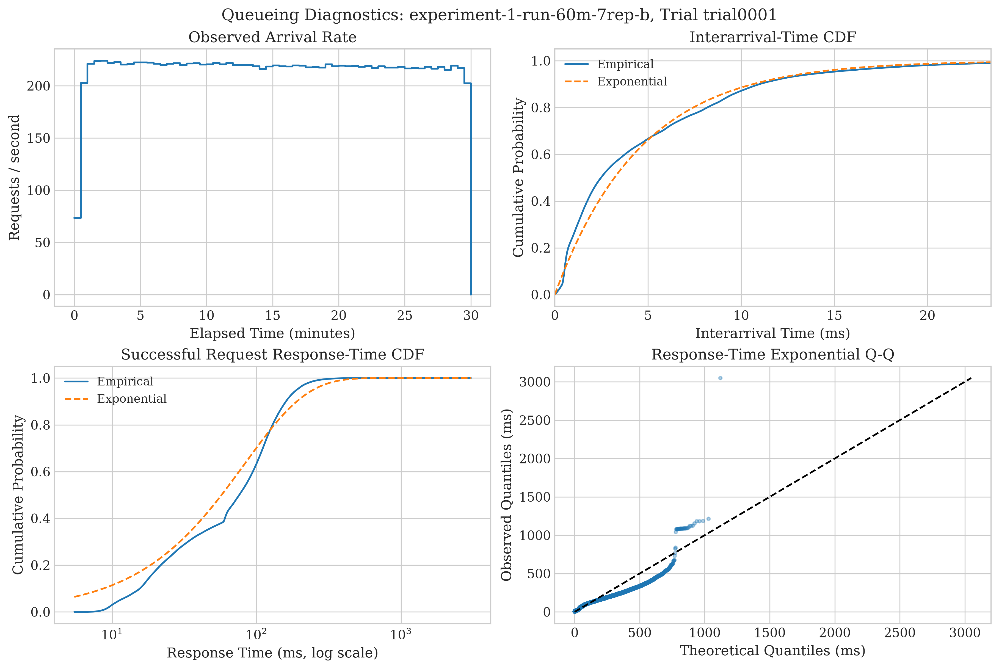

In [ ]:
df = log_df.copy()
data, queueing_summary_df = characterize_queueing(
    df,
    bin_seconds=30,
)

display(
    queueing_summary_df.groupby("autoscaler")[
        [
            "cv_interarrival",
            "arrival_fano",
            "interarrival_lag1_corr",
            "cv_response_time",
            "interarrival_ks_stat",
            "response_time_ks_stat",
        ]
    ].agg(["mean", "std", "median"]).round(3)
)

# Plot one representative trial.
trial = queueing_summary_df.iloc[0]

fig, axes = plot_queueing_diagnostics(
    data,
    run_id=trial["run_id"],
    trial_id=trial["trial_id"],
)
plt.show()


### Revised single plot

In [332]:

def plot_aggregate_queueing_diagnostics(
    df,
    *,
    warmup_seconds=120,
    bin_seconds=30,
    confidence_level=0.95,
    max_interarrival_ms=50,
    max_response_time_ms=2000,
    n_grid=300,
    figsize=(13, 9),
    save_path=None,
):
    """
    Aggregate queueing diagnostics across trials.

    Each trial receives equal weight within its replica
    configuration.

    Panels:
      A. Arrival rate
      B. Interarrival-time CDF
      C. Response-time CDF
      D. Response-time exponential Q-Q

    'autoscaler' contains replica configurations.
    """
    data = df.copy()
    data["replicas"] =data["autoscaler"].str.extract(r"horizontal-(\d+)").astype(int)
    data["autoscaler"] = data["replicas"].apply(lambda x: f"{x} replica{'s' if x > 1 else ''}")   




    data["start_time"] = pd.to_datetime(
        data["start_time"], utc=True, errors="coerce"
    )
    data["response_time"] = pd.to_numeric(
        data["response_time"], errors="coerce"
    )
    data = data.dropna(subset=["start_time"])

    keys = ["run_id", "trial_id"]

    data["elapsed_seconds"] = (
        data["start_time"]
        - data.groupby(keys)["start_time"].transform("min")
    ).dt.total_seconds()

    data = data[
        data["elapsed_seconds"] >= warmup_seconds
    ].copy()

    data["elapsed_seconds"] -= warmup_seconds

    trial_data = {}

    for (run_id, trial_id), g in data.groupby(keys):
        g = g.sort_values("start_time")
        if len(g) < 30:
            continue

        config = g["autoscaler"].iloc[0]

        ia = (
            g["start_time"].diff()
            .dt.total_seconds().dropna()
            .to_numpy(dtype=float) * 1000
        )

        success = (
            g["success"].astype(str)
            .str.lower().isin(["true", "1"])
        )

        rt = (
            g.loc[success, "response_time"]
            .dropna().to_numpy(dtype=float)
        )
        rt = rt[np.isfinite(rt) & (rt >= 0)]
        ia = ia[np.isfinite(ia) & (ia >= 0)]

        if len(ia) < 30 or len(rt) < 30:
            continue

        trial_data[(run_id, trial_id)] = {
            "config": config,
            "elapsed": g["elapsed_seconds"].to_numpy(),
            "ia": np.sort(ia),
            "rt": np.sort(rt),
        }

    configs = sorted({
        t["config"] for t in trial_data.values()
    })

    colors = plt.get_cmap("tab10").colors
    color_map = {
        config: colors[i % len(colors)]
        for i, config in enumerate(configs)
    }

    fig, axes = plt.subplots(
        2, 2, figsize=figsize, constrained_layout=True
    )

    ax_rate, ax_ia, ax_rt, ax_qq = axes.flat

    def mean_ci(values):
        values = np.asarray(values, dtype=float)
        n = values.shape[0]
        mean = values.mean(axis=0)

        if n < 2:
            return mean, mean, mean

        se = values.std(axis=0, ddof=1) / np.sqrt(n)
        critical = stats.t.ppf(
            (1 + confidence_level) / 2, n - 1
        )
        return mean, mean - critical * se, mean + critical * se

    ia_grid = np.linspace(0, max_interarrival_ms, n_grid)
    rt_grid = np.linspace(0, max_response_time_ms, n_grid)

    probabilities = np.linspace(0.01, 0.99, n_grid)

    for config in configs:
        trials = [
            t for t in trial_data.values()
            if t["config"] == config
        ]
        color = color_map[config]

        # A. Arrival rate on a common complete-bin grid
        durations = [t["elapsed"].max() for t in trials]
        n_bins = int(min(durations) // bin_seconds)

        if n_bins >= 2:
            edges = np.arange(n_bins + 1) * bin_seconds
            rates = []

            for t in trials:
                counts, _ = np.histogram(
                    t["elapsed"], bins=edges
                )
                rates.append(counts / bin_seconds)

            mean, lo, hi = mean_ci(rates)
            x = (edges[:-1] + bin_seconds / 2) / 60

            ax_rate.plot(
                x, mean, color=color, label=config
            )
            ax_rate.fill_between(
                x, lo, hi, color=color, alpha=0.12
            )

        # B. Interarrival empirical and fitted CDFs
        ia_empirical = []
        ia_exponential = []

        for t in trials:
            ia = t["ia"]
            ia_empirical.append(
                np.searchsorted(
                    ia, ia_grid, side="right"
                ) / len(ia)
            )
            ia_exponential.append(
                stats.expon.cdf(
                    ia_grid, scale=np.mean(ia)
                )
            )

        mean, lo, hi = mean_ci(ia_empirical)
        exp_mean = np.mean(ia_exponential, axis=0)

        ax_ia.plot(
            ia_grid, mean, color=color, label=config
        )
        ax_ia.fill_between(
            ia_grid, np.clip(lo, 0, 1),
            np.clip(hi, 0, 1),
            color=color, alpha=0.12
        )
        ax_ia.plot(
            ia_grid, exp_mean,
            color=color, linestyle="--", alpha=0.7
        )

        # C. Response-time empirical and fitted CDFs
        rt_empirical = []
        rt_exponential = []

        for t in trials:
            rt = t["rt"]
            rt_empirical.append(
                np.searchsorted(
                    rt, rt_grid, side="right"
                ) / len(rt)
            )
            rt_exponential.append(
                stats.expon.cdf(
                    rt_grid, scale=np.mean(rt)
                )
            )

        mean, lo, hi = mean_ci(rt_empirical)
        exp_mean = np.mean(rt_exponential, axis=0)

        ax_rt.plot(
            rt_grid, mean, color=color, label=config
        )
        ax_rt.fill_between(
            rt_grid, np.clip(lo, 0, 1),
            np.clip(hi, 0, 1),
            color=color, alpha=0.12
        )
        ax_rt.plot(
            rt_grid, exp_mean,
            color=color, linestyle="--", alpha=0.7
        )

        # D. Response-time Q-Q
        observed_quantiles = []
        theoretical_quantiles = []

        for t in trials:
            rt = t["rt"]
            observed_quantiles.append(
                np.quantile(rt, probabilities)
            )
            theoretical_quantiles.append(
                stats.expon.ppf(
                    probabilities, scale=np.mean(rt)
                )
            )

        obs_mean, _, _ = mean_ci(observed_quantiles)
        theory_mean = np.mean(theoretical_quantiles, axis=0)

        ax_qq.plot(
            theory_mean, obs_mean,
            color=color, label=config
        )

    # Formatting
    ax_rate.set(
        title="A. Observed Arrival Rate",
        xlabel="Elapsed Time After Warm-up (minutes)",
        ylabel="Requests / second"
    )

    ax_ia.set(
        title="B. Interarrival-Time Distribution",
        xlabel="Interarrival Time (ms)",
        ylabel="Cumulative Probability",
        ylim=(0, 1.02)
    )

    ax_rt.set(
        title="C. Response-Time Distribution",
        xlabel="Response Time (ms)",
        ylabel="Cumulative Probability",
        ylim=(0, 1.02)
    )

    ax_qq.set(
        title="D. Response-Time Exponential Q-Q",
        xlabel="Theoretical Quantile (ms)",
        ylabel="Observed Quantile (ms)"
    )

    # Reference diagonal for Q-Q.
    limit = max(
        ax_qq.get_xlim()[1],
        ax_qq.get_ylim()[1]
    )
    ax_qq.plot(
        [0, limit], [0, limit],
        "k--", linewidth=1, alpha=0.7
    )

    for ax in axes.flat:
        ax.grid(alpha=0.2)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    handles, labels = ax_rate.get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc="outside lower center",
        ncol=len(configs),
        frameon=False
    )

    if save_path:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    return fig, axes


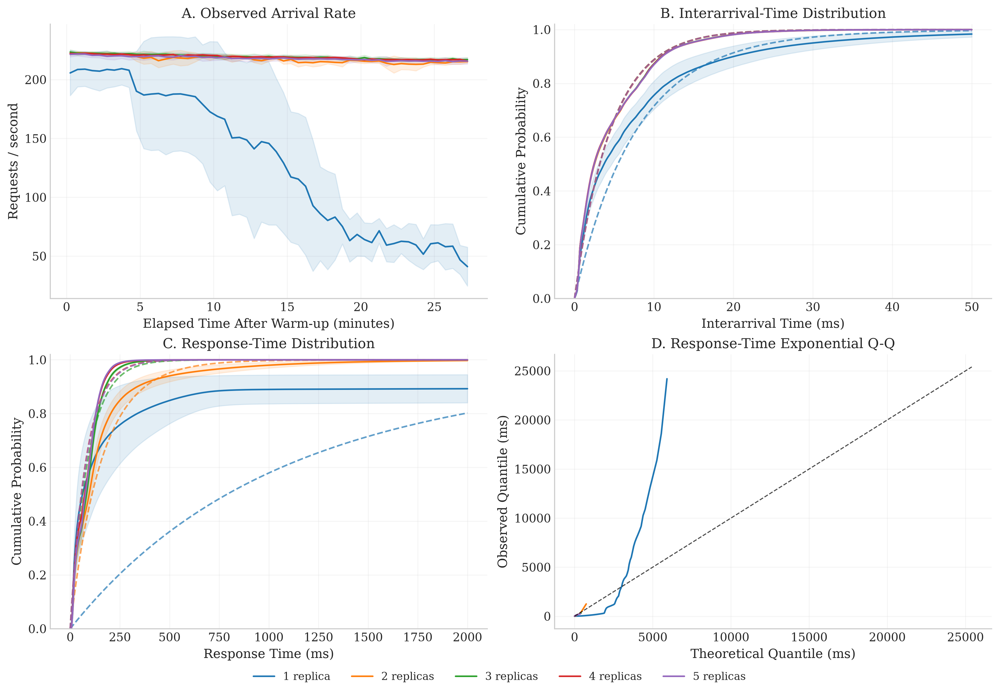

In [335]:
fig, axes = plot_aggregate_queueing_diagnostics(
    df,
    warmup_seconds=120,
    bin_seconds=30,
    max_interarrival_ms=50,
    max_response_time_ms=2000,
    save_path="../figures/experiment-1-queueing-diagnostics.png",
)

plt.show()

### Kolmogorov–Smirnov (KS) goodness-of-fit test

In [348]:


def exponential_ks_bootstrap(
    observations,
    *,
    n_bootstrap=1000,
    random_state=42,
):
    """
    Parametric-bootstrap KS test for an exponential
    distribution with location fixed at zero.

    H0: observations follow Exponential(scale=mean).

    The exponential parameter is re-estimated for
    every bootstrap sample.

    Assumes independent, identically distributed
    observations under H0.
    """
    x = np.asarray(observations, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 2 or np.any(x < 0) or np.mean(x) <= 0:
        return {
            "n": len(x),
            "mean": np.nan,
            "cv": np.nan,
            "ks_statistic": np.nan,
            "p_value": np.nan,
            "std": np.nan,
        }

    n = len(x)
    scale = np.mean(x)

    def ks_statistic(sample):
        fitted_scale = np.mean(sample)
        return stats.kstest(
            sample,
            "expon",
            args=(0, fitted_scale)
        ).statistic

    observed_d = ks_statistic(x)

    rng = np.random.default_rng(random_state)

    bootstrap_d = np.empty(n_bootstrap)

    for b in range(n_bootstrap):
        simulated = rng.exponential(
            scale=scale,
            size=n
        )
        bootstrap_d[b] = ks_statistic(simulated)

    p_value = (
        1 + np.count_nonzero(bootstrap_d >= observed_d)
    ) / (n_bootstrap + 1)

    return {
        "n": n,
        "mean": scale,
        "cv": np.std(x, ddof=1) / scale,
        "ks_statistic": observed_d,
        "p_value": p_value,
        "std": np.std(x, ddof=1),       
    }


def test_queueing_exponential_distributions(
    df,
    *,
    warmup_seconds=120,
    n_bootstrap=1000,
    random_state=42,
    min_observations=30,
):
    """
    Test exponential distributions for:
      1. Aggregate interarrival times
      2. Successful-request response times

    The 'autoscaler' column contains replica
    configurations such as horizontal-1.

    Response times are in milliseconds.

    Each (run_id, trial_id) is analyzed separately.
    """
    data = df.copy()

    data["start_time"] = pd.to_datetime(
        data["start_time"],
        utc=True,
        errors="coerce"
    )
    data["response_time"] = pd.to_numeric(
        data["response_time"],
        errors="coerce"
    )

    data = data.dropna(subset=["start_time"])

    keys = ["run_id", "trial_id"]

    data = data.sort_values(
        keys + ["start_time"]
    )

    data["elapsed_seconds"] = (
        data["start_time"]
        - data.groupby(keys)["start_time"].transform("min")
    ).dt.total_seconds()

    results = []

    for (run_id, trial_id), trial in data.groupby(keys):

        trial = trial[
            trial["elapsed_seconds"] >= warmup_seconds
        ].copy()

        if trial.empty:
            continue

        configuration = trial["autoscaler"].iloc[0]

        # Recompute gaps after removing warm-up.
        ia = (
            trial["start_time"]
            .diff()
            .dt.total_seconds()
            .dropna()
            .to_numpy()
        )

        # Retain zero gaps. Exponential distributions
        # are continuous and assign zero probability
        # to exact zero interarrival times.
        zero_fraction = (
            np.mean(ia == 0) if len(ia) else np.nan
        )

        # Successful requests only.
        success = (
            trial["success"]
            .astype(str)
            .str.lower()
            .isin(["true", "1"])
        )

        rt = (
            trial.loc[success, "response_time"]
            .dropna()
            .to_numpy(dtype=float)
        )

        rt = rt[np.isfinite(rt) & (rt >= 0)]

        for distribution_name, values in [
            ("interarrival", ia),
            ("response_time", rt),
        ]:
            if len(values) < min_observations:
                continue

            test = exponential_ks_bootstrap(
                values,
                n_bootstrap=n_bootstrap,
                random_state=random_state,
            )

            results.append({
                "run_id": run_id,
                "trial_id": trial_id,
                "replica_configuration": configuration,
                "distribution": distribution_name,
                "n": test["n"],
                "mean": test["mean"],
                "cv": test["cv"],
                "std": test["std"],
                "ks_statistic": test["ks_statistic"],
                "p_value": test["p_value"],
                "reject_h0_05": (
                    test["p_value"] < 0.05
                ),
                "zero_interarrival_fraction": (
                    zero_fraction
                    if distribution_name == "interarrival"
                    else np.nan
                ),
            })

    return pd.DataFrame(results)


In [325]:
ks_results_df = test_queueing_exponential_distributions(
    df,
    warmup_seconds=120,
    n_bootstrap=1000,
    random_state=42,
)

display(
    ks_results_df.sort_values(
        ["replica_configuration", "distribution", "trial_id"]
    ).round(4)
)

,run_id,trial_id,replica_configuration,distribution,n,mean,cv,ks_statistic,p_value,reject_h0_05,zero_interarrival_fraction
16,experiment-1-run-60m-7rep-b,trial0009,horizontal-1,interarrival,204160,0.0082,1.6975,0.1617,0.001,True,0.0001
18,experiment-1-run-60m-7rep-b,trial0010,horizontal-1,interarrival,240219,0.0070,1.6602,0.1403,0.001,True,0.0001
22,experiment-1-run-60m-7rep-b,trial0012,horizontal-1,interarrival,237102,0.0071,1.4377,0.1548,0.001,True,0.0001
28,experiment-1-run-60m-7rep-b,trial0015,horizontal-1,interarrival,242456,0.0069,1.3539,0.1418,0.001,True,0.0001
42,experiment-1-run-60m-7rep-b,trial0022,horizontal-1,interarrival,265025,0.0063,1.7084,0.1330,0.001,True,0.0001
...,...,...,...,...,...,...,...,...,...,...,...
5,experiment-1-run-60m-7rep-b,trial0003,horizontal-5,response_time,366622,79.8504,0.7547,0.1177,0.001,True,NaN
15,experiment-1-run-60m-7rep-b,trial0008,horizontal-5,response_time,366419,86.2363,0.6932,0.1634,0.001,True,NaN
31,experiment-1-run-60m-7rep-b,trial0016,horizontal-5,response_time,367320,76.9407,0.7954,0.0968,0.001,True,NaN
37,experiment-1-run-60m-7rep-b,trial0019,horizontal-5,response_time,367759,80.5826,0.7337,0.1265,0.001,True,NaN


In [327]:
ks_summary_df = (
    ks_results_df
    .groupby(["replica_configuration", "distribution"])
    .agg(
        trials=("trial_id", "count"),
        mean_ks=("ks_statistic", "mean"),
        median_cv=("cv", "median"),
        rejected=("reject_h0_05", "sum"),
        median_p=("p_value", "median"),
    )
    .reset_index()
)

ks_summary_df["rejection_percentage"] = (
    100 * ks_summary_df["rejected"]
    / ks_summary_df["trials"]
)

display(ks_summary_df.round(4))

,replica_configuration,distribution,trials,mean_ks,median_cv,rejected,median_p,rejection_percentage
0,horizontal-1,interarrival,7,0.1466,1.5223,7,0.001,100.0
1,horizontal-1,response_time,7,0.5940,3.8143,7,0.001,100.0
2,horizontal-2,interarrival,7,0.0877,1.1229,7,0.001,100.0
3,horizontal-2,response_time,7,0.1055,1.9194,7,0.001,100.0
4,horizontal-3,interarrival,7,0.0876,1.1114,7,0.001,100.0
5,horizontal-3,response_time,7,0.1111,0.8256,7,0.001,100.0
6,horizontal-4,interarrival,7,0.0900,1.1182,7,0.001,100.0
7,horizontal-4,response_time,7,0.1036,0.7857,7,0.001,100.0
8,horizontal-5,interarrival,7,0.0878,1.1138,7,0.001,100.0
9,horizontal-5,response_time,7,0.1335,0.7241,7,0.001,100.0


### K-S to Latex Table

In [347]:
ks_df = ks_summary_df.copy()
ks_df["replicas"] = ks_df["replica_configuration"].str.extract(r"(\d+)").astype(int)
ks_df = ks_df[["replicas", "distribution", "mean_ks", "median_cv", "median_p", "rejection_percentage"]]
ks_df = ks_df.rename(columns={
    "replicas": "Replicas",
    "distribution": "Metric",
    "mean_ks": "Mean KS Statistic",
    "median_cv": "Median CV",
    "median_p": "Median $p$-value",
    "rejection_percentage": r"Rejection \%"
})

format_apa_p = lambda x: f"{x:.3f}".lstrip("0") if x >= 0.001 else "$< .001$"

format_dict = {
    'Median $p$-value': format_apa_p,
    'Mean KS Statistic': "{:.4f}",
    "Median CV": "{:.4f}",
    r"Rejection \%": "{:.1f}"
}

for dist in ks_df.Metric.unique():
    dist_text = "interarrival times" if dist == "interarrival" else "response times"
    latex = ks_df[ks_df.Metric == dist].style.format(format_dict, na_rep='').hide(
            axis='index').hide(subset=["Metric"], axis="columns").to_latex(
        caption=f"Experiment 1 Kolmogorov–Smirnov test of the exponential distribution of {dist_text}.",
        label=f"tab:experiment-1-ks-test-{dist}".replace("_","-"),
        hrules=True
    )
    print(latex)

ks_df


\begin{table}
\caption{Experiment 1 Kolmogorov–Smirnov test of the exponential distribution of interarrival times.}
\label{tab:experiment-1-ks-test-interarrival}
\begin{tabular}{rrrrr}
\toprule
Replicas & Mean KS Statistic & Median CV & Median $p$-value & Rejection \% \\
\midrule
1 & 0.1466 & 1.5223 & $< .001$ & 100.0 \\
2 & 0.0877 & 1.1229 & $< .001$ & 100.0 \\
3 & 0.0876 & 1.1114 & $< .001$ & 100.0 \\
4 & 0.0900 & 1.1182 & $< .001$ & 100.0 \\
5 & 0.0878 & 1.1138 & $< .001$ & 100.0 \\
\bottomrule
\end{tabular}
\end{table}

\begin{table}
\caption{Experiment 1 Kolmogorov–Smirnov test of the exponential distribution of response times.}
\label{tab:experiment-1-ks-test-response-time}
\begin{tabular}{rrrrr}
\toprule
Replicas & Mean KS Statistic & Median CV & Median $p$-value & Rejection \% \\
\midrule
1 & 0.5940 & 3.8143 & $< .001$ & 100.0 \\
2 & 0.1055 & 1.9194 & $< .001$ & 100.0 \\
3 & 0.1111 & 0.8256 & $< .001$ & 100.0 \\
4 & 0.1036 & 0.7857 & $< .001$ & 100.0 \\
5 & 0.1335 & 0.7241 & $<

,Replicas,Metric,Mean KS Statistic,Median CV,Median $p$-value,Rejection \%
0,1,interarrival,0.146602,1.522331,0.000999,100.0
1,1,response_time,0.594022,3.814346,0.000999,100.0
2,2,interarrival,0.087669,1.122935,0.000999,100.0
3,2,response_time,0.105460,1.919377,0.000999,100.0
4,3,interarrival,0.087641,1.111431,0.000999,100.0
5,3,response_time,0.111116,0.825638,0.000999,100.0
6,4,interarrival,0.090018,1.118152,0.000999,100.0
7,4,response_time,0.103569,0.785719,0.000999,100.0
8,5,interarrival,0.087828,1.113799,0.000999,100.0
9,5,response_time,0.133487,0.724059,0.000999,100.0


## Optimized version of KS

In [9]:


def _vectorized_exp_ks_stat_chunk(samples_sorted):
    """samples_sorted: shape (n, chunk_size), sorted along axis 0."""
    n = samples_sorted.shape[0]
    mean = np.mean(samples_sorted, axis=0, keepdims=True)

    # In-place / low-allocation CDF evaluation
    cdf_vals = -np.expm1(-samples_sorted / mean)

    i = np.arange(1, n + 1, dtype=float).reshape(-1, 1)
    d_plus = np.max(i / n - cdf_vals, axis=0)
    d_minus = np.max(cdf_vals - (i - 1.0) / n, axis=0)

    return np.maximum(d_plus, d_minus)


def exponential_ks_bootstrap(
    observations,
    *,
    n_bootstrap=1000,
    random_state=42,
    batch_size=200,  # Limits peak memory consumption
):
    x = np.asarray(observations, dtype=float)
    x = x[np.isfinite(x)]

    n = len(x)
    if n < 2 or np.any(x < 0):
        return {
            "n": n,
            "mean": np.nan,
            "cv": np.nan,
            "ks_statistic": np.nan,
            "p_value": np.nan,
            "std": np.nan,
        }

    scale = np.mean(x)
    if scale <= 0:
        return {
            "n": n,
            "mean": scale,
            "cv": np.nan,
            "ks_statistic": np.nan,
            "p_value": np.nan,
            "std": np.nan,
        }

    # 1. Observed statistic
    x_sorted = np.sort(x)[:, None]
    observed_d = _vectorized_exp_ks_stat_chunk(x_sorted)[0]

    # 2. Chunked Bootstrap: Prevents OOM crashes on large n
    rng = np.random.default_rng(random_state)
    exceedances = 0
    remaining = n_bootstrap

    # Scale chunk size dynamically if n is very large
    # (keeps temporary memory strictly under ~150 MB)
    effective_chunk_size = min(batch_size, max(10, int(2e7 / n)))

    while remaining > 0:
        current_batch = min(remaining, effective_chunk_size)

        simulated = rng.exponential(scale=1.0, size=(n, current_batch))
        simulated.sort(axis=0)

        batch_d = _vectorized_exp_ks_stat_chunk(simulated)
        exceedances += np.count_nonzero(batch_d >= observed_d)

        remaining -= current_batch

    p_value = (1 + exceedances) / (n_bootstrap + 1)
    std_val = np.std(x, ddof=1)

    return {
        "n": n,
        "mean": scale,
        "cv": std_val / scale,
        "ks_statistic": observed_d,
        "p_value": p_value,
        "std": std_val,
    }



def test_queueing_exponential_distributions(
    df,
    *,
    warmup_seconds=120,
    n_bootstrap=1000,
    random_state=42,
    min_observations=30,
):
    data = df.copy()

    # Pre-parse timestamps and response times
    data["start_time"] = pd.to_datetime(
        data["start_time"], utc=True, errors="coerce"
    )
    data["response_time"] = pd.to_numeric(
        data["response_time"], errors="coerce"
    )
    data = data.dropna(subset=["start_time"])

    # Vectorize success check upfront across the whole table
    if data["success"].dtype == object:
        data["is_success"] = (
            data["success"].astype(str).str.lower().isin(["true", "1"])
        )
    else:
        data["is_success"] = data["success"].astype(bool)

    keys = ["run_id", "trial_id"]
    data = data.sort_values(keys + ["start_time"])

    # Elapsed seconds relative to trial start
    data["elapsed_seconds"] = (
        data["start_time"] - data.groupby(keys)["start_time"].transform("min")
    ).dt.total_seconds()

    # Filter out warmup in a single bulk operation
    data = data[data["elapsed_seconds"] >= warmup_seconds]

    results = []

    # Iterate over groups using groupby without redundant internal copies
    for (run_id, trial_id), trial in data.groupby(keys, sort=False):
        if trial.empty:
            continue

        configuration = trial["autoscaler"].iloc[0]

        # Interarrival times (drop diff NaN from first row)
        st_vals = trial["start_time"].values
        if len(st_vals) > 1:
            ia = (
                (st_vals[1:] - st_vals[:-1])
                .astype("timedelta64[ns]")
                .astype(float)
                / 1e9
            )
        else:
            ia = np.empty(0, dtype=float)

        zero_fraction = np.mean(ia == 0) if len(ia) else np.nan

        # Successful response times
        rt = trial.loc[
            trial["is_success"]
            & trial["response_time"].notna()
            & (trial["response_time"] >= 0),
            "response_time",
        ].to_numpy(dtype=float)
        rt = rt[np.isfinite(rt)]

        for distribution_name, values in [
            ("interarrival", ia),
            ("response_time", rt),
        ]:
            if len(values) < min_observations:
                continue

            test = exponential_ks_bootstrap(
                values,
                n_bootstrap=n_bootstrap,
                random_state=random_state,
            )

            results.append({
                "run_id": run_id,
                "trial_id": trial_id,
                "replica_configuration": configuration,
                "distribution": distribution_name,
                "n": test["n"],
                "mean": test["mean"],
                "cv": test["cv"],
                "std": test["std"],
                "ks_statistic": test["ks_statistic"],
                "p_value": test["p_value"],
                "reject_h0_05": (test["p_value"] < 0.05),
                "zero_interarrival_fraction": (
                    zero_fraction
                    if distribution_name == "interarrival"
                    else np.nan
                ),
            })

    return pd.DataFrame(results)


In [10]:
df = log_df.copy()

ks_results_df = test_queueing_exponential_distributions(
    df,
    warmup_seconds=120,
    n_bootstrap=1000,
    random_state=42,
)

display(
    ks_results_df.sort_values(
        ["replica_configuration", "distribution", "trial_id"]
    ).round(4)
)

,run_id,trial_id,replica_configuration,distribution,n,mean,cv,std,ks_statistic,p_value,reject_h0_05,zero_interarrival_fraction
16,experiment-1-run-60m-7rep-b,trial0009,horizontal-1,interarrival,204160,0.0082,1.6975,0.0139,0.1617,0.001,True,0.0001
18,experiment-1-run-60m-7rep-b,trial0010,horizontal-1,interarrival,240219,0.0070,1.6602,0.0116,0.1403,0.001,True,0.0001
22,experiment-1-run-60m-7rep-b,trial0012,horizontal-1,interarrival,237102,0.0071,1.4377,0.0102,0.1548,0.001,True,0.0001
28,experiment-1-run-60m-7rep-b,trial0015,horizontal-1,interarrival,242456,0.0069,1.3539,0.0094,0.1418,0.001,True,0.0001
42,experiment-1-run-60m-7rep-b,trial0022,horizontal-1,interarrival,265025,0.0063,1.7084,0.0108,0.1330,0.001,True,0.0001
...,...,...,...,...,...,...,...,...,...,...,...,...
5,experiment-1-run-60m-7rep-b,trial0003,horizontal-5,response_time,366622,79.8504,0.7547,60.2665,0.1177,0.001,True,NaN
15,experiment-1-run-60m-7rep-b,trial0008,horizontal-5,response_time,366419,86.2363,0.6932,59.7781,0.1634,0.001,True,NaN
31,experiment-1-run-60m-7rep-b,trial0016,horizontal-5,response_time,367320,76.9407,0.7954,61.1968,0.0968,0.001,True,NaN
37,experiment-1-run-60m-7rep-b,trial0019,horizontal-5,response_time,367759,80.5826,0.7337,59.1269,0.1265,0.001,True,NaN


In [11]:
ks_summary_df = (
    ks_results_df
    .groupby(["replica_configuration", "distribution"])
    .agg(
        trials=("trial_id", "count"),
        mean_ks=("ks_statistic", "mean"),
        median_cv=("cv", "median"),
        rejected=("reject_h0_05", "sum"),
        median_p=("p_value", "median"),
        median_std=("std", "median"),
    )
    .reset_index()
)

ks_summary_df["rejection_percentage"] = (
    100 * ks_summary_df["rejected"]
    / ks_summary_df["trials"]
)

display(ks_summary_df.round(4))

,replica_configuration,distribution,trials,mean_ks,median_cv,rejected,median_p,median_std,rejection_percentage
0,horizontal-1,interarrival,7,0.1466,1.5223,7,0.001,0.0116,100.0
1,horizontal-1,response_time,7,0.5940,3.8143,7,0.001,4051.5947,100.0
2,horizontal-2,interarrival,7,0.0877,1.1229,7,0.001,0.0052,100.0
3,horizontal-2,response_time,7,0.1055,1.9194,7,0.001,315.1941,100.0
4,horizontal-3,interarrival,7,0.0876,1.1114,7,0.001,0.0051,100.0
5,horizontal-3,response_time,7,0.1111,0.8256,7,0.001,72.5801,100.0
6,horizontal-4,interarrival,7,0.0900,1.1182,7,0.001,0.0051,100.0
7,horizontal-4,response_time,7,0.1036,0.7857,7,0.001,63.7807,100.0
8,horizontal-5,interarrival,7,0.0878,1.1138,7,0.001,0.0051,100.0
9,horizontal-5,response_time,7,0.1335,0.7241,7,0.001,59.7781,100.0


In [30]:
df = ks_results_df.copy()
# display(df)
df["replicas"] = df["replica_configuration"].str.extract(r"(\d+)").astype(int)
df = df.groupby(["replica_configuration", "distribution"]).agg(
    mean_n=("n", "mean"),
    mean=("mean", "mean"),
    mean_ks=("ks_statistic", "mean"),
    mean_cv=("cv", "mean"),
    mean_std=("std", "mean"),
    trials=("trial_id", "count"),
    # replica_config=("replica_configuration", "first"),
    # distribution=("distribution", "first"),
)
df.reset_index(inplace=True)
df["cv_squared"] = df["mean_cv"] ** 2
df

,replica_configuration,distribution,mean_n,mean,mean_ks,mean_cv,mean_std,trials,cv_squared
0,horizontal-1,interarrival,216083.142857,0.008097,0.146602,1.536723,0.012396,7,2.361517
1,horizontal-1,response_time,206821.571429,1283.691402,0.594022,3.842637,4491.679252,7,14.765857
2,horizontal-2,interarrival,364498.714286,0.004605,0.087669,1.118262,0.005149,7,1.250509
3,horizontal-2,response_time,364461.714286,162.263074,0.105460,1.848620,305.758427,7,3.417396
4,horizontal-3,interarrival,368269.571429,0.004559,0.087641,1.111202,0.005066,7,1.234769
5,horizontal-3,response_time,368264.142857,89.735599,0.111116,0.818766,73.391653,7,0.670378
6,horizontal-4,interarrival,367638.714286,0.004564,0.090018,1.115846,0.005093,7,1.245112
7,horizontal-4,response_time,367635.571429,80.446509,0.103569,0.784164,63.021277,7,0.614913
8,horizontal-5,interarrival,365908.428571,0.004587,0.087828,1.115052,0.005114,7,1.243340
9,horizontal-5,response_time,365904.428571,82.009456,0.133487,0.731076,59.862307,7,0.534472


In [12]:
ks_summary_df["cv_squared"] = ks_summary_df["median_cv"] ** 2


In [34]:
for dist in df.distribution.unique():
    dist_data = df[ks_summary_df.distribution == dist]
    print(dist)
    display(dist_data.round(5))


interarrival


,replica_configuration,distribution,mean_n,mean,mean_ks,mean_cv,mean_std,trials,cv_squared
0,horizontal-1,interarrival,216083.14286,0.00810,0.14660,1.53672,0.01240,7,2.36152
2,horizontal-2,interarrival,364498.71429,0.00460,0.08767,1.11826,0.00515,7,1.25051
4,horizontal-3,interarrival,368269.57143,0.00456,0.08764,1.11120,0.00507,7,1.23477
6,horizontal-4,interarrival,367638.71429,0.00456,0.09002,1.11585,0.00509,7,1.24511
8,horizontal-5,interarrival,365908.42857,0.00459,0.08783,1.11505,0.00511,7,1.24334


response_time


,replica_configuration,distribution,mean_n,mean,mean_ks,mean_cv,mean_std,trials,cv_squared
1,horizontal-1,response_time,206821.57143,1283.69140,0.59402,3.84264,4491.67925,7,14.76586
3,horizontal-2,response_time,364461.71429,162.26307,0.10546,1.84862,305.75843,7,3.41740
5,horizontal-3,response_time,368264.14286,89.73560,0.11112,0.81877,73.39165,7,0.67038
7,horizontal-4,response_time,367635.57143,80.44651,0.10357,0.78416,63.02128,7,0.61491
9,horizontal-5,response_time,365904.42857,82.00946,0.13349,0.73108,59.86231,7,0.53447


# Other

In [111]:
log_df.columns

Index(['run_id', 'trial_id', 'role', 'autoscaler', 'user_id', 'request_type',
       'name', 'response_time', 'response_length', 'response', 'status_code',
       'reason', 'exception', 'start_time', 'url', 'method_and_name',
       'success', 'failure'],
      dtype='str')

In [114]:
result_df = log_df.pivot_table(
    index='method_and_name', 
    columns='autoscaler', 
    aggfunc='size', 
    fill_value=0
)
result_df

autoscaler,horizontal-1,horizontal-2,horizontal-3,horizontal-4,horizontal-5
method_and_name,,,,,
GET /api/balances?portfolio_id={id},37000,12829,12669,12673,13517
GET /api/executions/{id},507550,878405,884828,883215,877868
GET /api/executions?portfolio_id={portfolio_id},37033,12830,12669,12674,13519
GET /api/models/{id},15866,21733,22286,22353,22315
GET /api/orders,14314,5290,5109,5208,5154
GET /api/portfolios/{id},411249,602534,610179,611262,610656
GET /api/rebalances/{id},9971,21676,22229,22291,22247
GET /api/securities,315,315,315,315,315
GET /api/trades,14274,5285,5105,5202,5152


In [117]:
result_df = log_df.pivot_table(
    index='method_and_name', 
    columns='autoscaler', 
    values='response_time', 
    aggfunc='mean'
)
result_df

autoscaler,horizontal-1,horizontal-2,horizontal-3,horizontal-4,horizontal-5
method_and_name,,,,,
GET /api/balances?portfolio_id={id},861.308093,174.385400,156.333945,154.917258,154.156324
GET /api/executions/{id},119.002661,94.382978,80.375148,79.556222,78.126827
GET /api/executions?portfolio_id={portfolio_id},92.545918,173.448801,155.569909,157.176243,158.696534
GET /api/models/{id},34.029566,18.161653,15.945228,15.714927,15.527977
GET /api/orders,432.683416,176.388444,151.013154,148.858020,148.391456
GET /api/portfolios/{id},6485.753394,230.703429,79.745158,54.140455,61.161672
GET /api/rebalances/{id},44.424946,20.385729,18.307834,18.253722,18.044422
GET /api/securities,18731.544700,44.643606,41.530494,47.565520,50.451748
GET /api/trades,1531.828951,225.355332,167.374110,159.189252,165.155266


In [119]:
result_df.columns

Index(['horizontal-1', 'horizontal-2', 'horizontal-3', 'horizontal-4',
       'horizontal-5'],
      dtype='str', name='autoscaler')

In [120]:
result_df["horizontal-1"] = 1.0 / result_df["horizontal-1"]
result_df["horizontal-2"] = 1.0 / result_df["horizontal-2"]
result_df["horizontal-3"] = 1.0 / result_df["horizontal-3"]
result_df["horizontal-4"] = 1.0 / result_df["horizontal-4"]
result_df["horizontal-5"] = 1.0 / result_df["horizontal-5"]
result_df

autoscaler,horizontal-1,horizontal-2,horizontal-3,horizontal-4,horizontal-5
method_and_name,,,,,
GET /api/balances?portfolio_id={id},0.001161,0.005734,0.006397,0.006455,0.006487
GET /api/executions/{id},0.008403,0.010595,0.012442,0.012570,0.012800
GET /api/executions?portfolio_id={portfolio_id},0.010805,0.005765,0.006428,0.006362,0.006301
GET /api/models/{id},0.029386,0.055061,0.062715,0.063634,0.064400
GET /api/orders,0.002311,0.005669,0.006622,0.006718,0.006739
GET /api/portfolios/{id},0.000154,0.004335,0.012540,0.018470,0.016350
GET /api/rebalances/{id},0.022510,0.049054,0.054621,0.054783,0.055419
GET /api/securities,0.000053,0.022400,0.024079,0.021024,0.019821
GET /api/trades,0.000653,0.004437,0.005975,0.006282,0.006055


In [124]:
2 * (((1.0 - 0.6640)/0.1325)**(1/2))

3.184869891599199